##### tentativa de previsão mais alto Etanol 2026

In [1]:
import os
import io
import certifi
import time
import optuna
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações Globais (Ignorar warnings e GUI)
warnings.filterwarnings("ignore")
plt.switch_backend('Agg')
optuna.logging.set_verbosity(optuna.logging.WARNING)

from typing import Dict, Union, List
from PIL import Image as PILImage
from matplotlib.figure import Figure
from openpyxl import Workbook
from openpyxl.worksheet.worksheet import Worksheet
from openpyxl.drawing.image import Image as OpenPyxlImage
from openpyxl.utils.dataframe import dataframe_to_rows
from openpyxl.utils import get_column_letter
from openpyxl.styles import PatternFill, Font, Alignment
from darts.timeseries import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
from sklearn.metrics import mean_absolute_percentage_error
import timesfm

# Criação/Verificação das pastas do projeto
PATH_DATA = "data"
PATH_PLOTS = "plots"
PATH_CSVS = "csvs"

TIMESFM_LOCAL_PATH = "../TimesFM_pesos"
TIMESFM_CKPT_FILE = "torch_model.ckpt"

ckpt_local = os.path.join(TIMESFM_LOCAL_PATH, TIMESFM_CKPT_FILE)

print("PWD:", os.getcwd())
print("TimesFM existe?", os.path.exists("../TimesFM_pesos"))
print("Checkpoint existe?", os.path.exists("TimesFM/torch_model.ckpt"))

os.makedirs(PATH_PLOTS, exist_ok=True)
os.makedirs(PATH_CSVS, exist_ok=True)

if not os.path.exists(PATH_DATA):
    print(f"Erro: A pasta '{PATH_DATA}' não foi encontrada no diretório atual.")
    print(f"Por favor, crie a pasta '{PATH_DATA}' e coloque o arquivo Excel dentro dela.")
    exit(1)





 See https://github.com/google-research/timesfm/blob/master/README.md for updated APIs.
Loaded PyTorch TimesFM, likely because python version is 3.11.9 (main, Apr 25 2024, 19:04:53) [GCC 11.4.1 20230605 (Red Hat 11.4.1-2)].
PWD: /srv/shared/CicloOtto/auto_otto_ge/auto_ge
TimesFM existe? True
Checkpoint existe? False


In [2]:
# Estrutura auxiliar para Excel

class ExcelBuilder:
    def __init__(self, output_path: str) -> None:
        self.output_path = output_path
        self.workbook = Workbook()
        self.sheets: Dict[str, Worksheet] = {}
        self.current_row: Dict[str, int] = {}
        if "Sheet" in self.workbook.sheetnames:
            self.workbook.remove(self.workbook["Sheet"])

    def create_sheet(self, sheet_name: str) -> "ExcelBuilder":
        if sheet_name not in self.workbook.sheetnames:
            self.sheets[sheet_name] = self.workbook.create_sheet(sheet_name)
            self.current_row[sheet_name] = 1
        return self

    def create_sheets(self, sheet_names: List[str]) -> "ExcelBuilder":
        for sheet_name in sheet_names:
            self.create_sheet(sheet_name)
        return self

    def _write_header(self, ws, title, num_cols, start_col, current_row,
                      title_fill_color="808080", columns_fill_color="B0B0B0") -> int:
        ws.cell(row=current_row, column=start_col + 1, value=title).fill = PatternFill(
            patternType="solid", fgColor=title_fill_color
        )
        ws.cell(row=current_row, column=start_col + 1).font = Font(bold=True, color="FFFFFF", size=12)
        ws.cell(row=current_row, column=start_col + 1).alignment = Alignment(horizontal="center", vertical="center")

        ws.merge_cells(
            f"{get_column_letter(start_col + 1)}{current_row}:{get_column_letter(start_col + num_cols)}{current_row}"
        )
        ws.row_dimensions[current_row].height = 20

        for c_idx in range(start_col + 1, start_col + num_cols + 1):
            cell = ws.cell(row=current_row + 1, column=c_idx)
            cell.fill = PatternFill(patternType="solid", fgColor=columns_fill_color)
            cell.font = Font(bold=True, color="FFFFFF")
            cell.alignment = Alignment(horizontal="center")

        return current_row + 1

    def add_dataframe_figure_pair(self, sheet_name, dataframe, figure, title="",
                                  start_col=0, image_col_offset=6, row_gap=15,
                                  title_fill_color="808080", columns_fill_color="B0B0B0") -> "ExcelBuilder":
        if sheet_name not in self.sheets:
            raise ValueError(f"A aba '{sheet_name}' não existe.")

        ws = self.sheets[sheet_name]
        current_row = self.current_row[sheet_name]

        if title:
            data_start_row = self._write_header(
                ws, title, len(dataframe.columns), start_col, current_row,
                title_fill_color, columns_fill_color
            ) + 1

            for c_idx, col_name in enumerate(dataframe.columns, start=start_col + 1):
                ws.cell(row=data_start_row - 1, column=c_idx, value=col_name)

            for r_idx, row in enumerate(dataframe_to_rows(dataframe, index=False, header=False), start=data_start_row):
                for c_idx, value in enumerate(row, start=start_col + 1):
                    ws.cell(row=r_idx, column=c_idx, value=value)
        else:
            for r_idx, row in enumerate(dataframe_to_rows(dataframe, index=False, header=True), start=current_row):
                for c_idx, value in enumerate(row, start=start_col + 1):
                    ws.cell(row=r_idx, column=c_idx, value=value)

        self._adjust_column_widths(ws, dataframe, start_col, title)

        if isinstance(figure, str):
            figure = PILImage.open(figure)
        if not isinstance(figure, PILImage.Image):
            buf = io.BytesIO()
            figure.savefig(buf, format="png", bbox_inches="tight")
            buf.seek(0)
            figure = PILImage.open(buf)

        image_buf = io.BytesIO()
        figure.save(image_buf, format="PNG")
        image_buf.seek(0)
        img = OpenPyxlImage(image_buf)

        ws.add_image(img, f"{get_column_letter(start_col + image_col_offset + 1)}{current_row}")
        self.current_row[sheet_name] = current_row + ((2 if title else 0) + len(dataframe)) + row_gap + 1
        return self

    def _adjust_column_widths(self, worksheet, dataframe, start_col, title="") -> None:
        num_cols = len(dataframe.columns)
        for col_idx, column in enumerate(dataframe.columns, start=start_col):
            col_letter = get_column_letter(col_idx + 1)
            max_length = max(len(str(column)), *(len(str(x)) for x in dataframe[column]))
            if title:
                max_length = max(max_length, (len(title) // num_cols) + 2)
            worksheet.column_dimensions[col_letter].width = max_length + 2

    def save(self) -> None:
        self.workbook.save(self.output_path)

    def close(self) -> None:
        if hasattr(self, "workbook"):
            self.workbook.close()

In [3]:
##############################################################################################
# Leitura

controle = os.path.join(PATH_DATA, "arquivos_processados.txt")

while True:
    # Arquivos já processados
    if os.path.exists(controle):
        with open(controle, "r", encoding="utf-8") as f:
            arquivos_processados = set(
                linha.strip() for linha in f if linha.strip()
            )
    else:
        arquivos_processados = set()

    # Arquivos existentes na pasta
    arquivos_data = {
        arq for arq in os.listdir(PATH_DATA)
        if arq.endswith((".xlsx", ".xls"))
    }

    # Apenas arquivos novos
    novos_arquivos = arquivos_data - arquivos_processados

    if not novos_arquivos:
        print("Nenhum arquivo novo adicionado")
        time.sleep(1)
        continue

    for arquivo in sorted(novos_arquivos):

        excel_file = os.path.join(PATH_DATA, arquivo)

        print(f" -> Lendo dados de: {excel_file}")

        df = pd.read_excel(excel_file)

        with open(controle, "a", encoding="utf-8") as f:
            f.write(f"{arquivo}\n")
            print("finalizada a leitura")



Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado
Nenhum arquivo novo adicionado


KeyboardInterrupt: 

In [8]:
   ##############################################################################################
    #  preparação dos dados
PATH_DATA='data'
arquivo='Dados Demanda Ciclo Otto 3107 - 14k8.xlsx'

excel_file = os.path.join(PATH_DATA, arquivo)

print(f" -> Lendo dados de: {excel_file}")

df = (
    pd.read_excel(excel_file, sheet_name="Demanda Ciclo Otto (ANP)")
      .rename(columns={
          "Unnamed: 0": "Data",
          "Demanda Etanol Hidratado (m3)": "Etanol",
          "Demanda Gasolina C (m3)": "Gasolina",
          "Demanda Ciclo Otto (m3 gasolina equivalente)": "Otto"
      })
)
df["Data"] = pd.to_datetime(df["Data"])

otto_series = TimeSeries.from_dataframe(df, time_col="Data", value_cols="Otto", freq="MS")
gasolina_series = TimeSeries.from_dataframe(df, time_col="Data", value_cols="Gasolina", freq="MS")
etanol_series = TimeSeries.from_dataframe(df, time_col="Data", value_cols="Etanol", freq="MS")

series_dict = {
    "Otto": otto_series,
    "Gasolina": gasolina_series,
    "Etanol": etanol_series,
}

 -> Lendo dados de: data/Dados Demanda Ciclo Otto 3107 - 14k8.xlsx


In [9]:
# Verifica o que existe no notebook
print("Variáveis disponíveis:")
for name in sorted(globals().keys()):
    if 'train' in name.lower() or 'val' in name.lower() or 'df' in name.lower():
        obj = globals()[name]
        tipo = type(obj).__name__
        if hasattr(obj, 'shape'):
            print(f"  {name}: {tipo} {obj.shape}")
        elif hasattr(obj, '__len__'):
            print(f"  {name}: {tipo} (len={len(obj)})")
        else:
            print(f"  {name}: {tipo}")

Variáveis disponíveis:
  df: DataFrame (197, 4)


In [10]:
df['Etanol']

from darts import TimeSeries

# 1. Cria TimeSeries
serie = TimeSeries.from_dataframe(
    df,
    time_col="Data",
    value_cols="Etanol"
)

# 2. Divide
train, val = serie.split_before(0.8)

# 3. Volta para pandas para usar Prophet
train_copy = train.pd_dataframe().reset_index()

# 4. Prophet precisa de ds e y
train_copy.columns = ["ds", "y"]
# 5. Floor
train_copy["floor"] = 0.0




In [11]:
# Verifica o que existe no notebook
print("Variáveis disponíveis:")
for name in sorted(globals().keys()):
    if 'train' in name.lower() or 'val' in name.lower() or 'df' in name.lower():
        obj = globals()[name]
        tipo = type(obj).__name__
        if hasattr(obj, 'shape'):
            print(f"  {name}: {tipo} {obj.shape}")
        elif hasattr(obj, '__len__'):
            print(f"  {name}: {tipo} (len={len(obj)})")
        else:
            print(f"  {name}: {tipo}")

Variáveis disponíveis:
  df: DataFrame (197, 4)
  train: TimeSeries (len=156)
  train_copy: DataFrame (156, 3)
  val: TimeSeries (len=41)


In [16]:
df_real=df.copy()

In [18]:
import pandas as pd
from darts import TimeSeries
from darts.models import Prophet

# SUPONDO que seu df original tenha as colunas 'data' e 'demanda'
#df = df_original.rename(columns={'data': 'ds', 'demanda': 'y'}) 
df = df_real.rename(columns={'data': 'ds', 'demanda': 'y'}) 
df['taxa_desconto'] = 0.0 # Histórico real (etanol estava caro, sem desconto)

# CRIANDO O PRIOR CUSTOMIZADO (Passado Falso / Crença)
demanda_base_mensal = df['y'].iloc[-3:].mean() 
df_crenca = pd.DataFrame({
    'ds': pd.date_range(start=df['ds'].max() + pd.offsets.MonthBegin(1), periods=3, freq='MS'),
    'y': [demanda_base_mensal * 1.15, demanda_base_mensal * 1.20, demanda_base_mensal * 1.25], 
    'taxa_desconto': [0.05, 0.10, 0.15] # Ensina: 5% desconto -> 15% mais demanda
})
df_treino = pd.concat([df, df_crenca])

# Convertendo para TimeSeries do Darts
target = TimeSeries.from_dataframe(df_treino, 'ds', 'y')
covs = TimeSeries.from_dataframe(df_treino, 'ds', 'taxa_desconto')

KeyError: 'y'

In [19]:
df

,Data,Etanol,Gasolina,Otto,taxa_desconto
0,2010-01-01,979037.714,2448435.164,3.133762e+06,0.0
1,2010-02-01,804778.670,2385364.494,2.948710e+06,0.0
2,2010-03-01,1084078.013,2663940.261,3.422795e+06,0.0
3,2010-04-01,1223933.200,2412308.984,3.269062e+06,0.0
4,2010-05-01,1318470.605,2332079.020,3.255008e+06,0.0
...,...,...,...,...,...
192,2026-01-01,1650990.051,3918219.832,5.073913e+06,0.0
193,2026-02-01,1517005.102,3763892.298,4.825796e+06,0.0
194,2026-03-01,1800016.028,4175202.666,5.435214e+06,0.0
195,2026-04-01,1841266.997,3939819.400,5.228706e+06,0.0


18:00:04 - cmdstanpy - INFO - Chain [1] start processing
18:00:04 - cmdstanpy - INFO - Chain [1] done processing


MAPE da validação (curva base): 23.83%
Pronto! 'forecast_final' já tem o choque de demanda aplicado.
Dados prontos? True


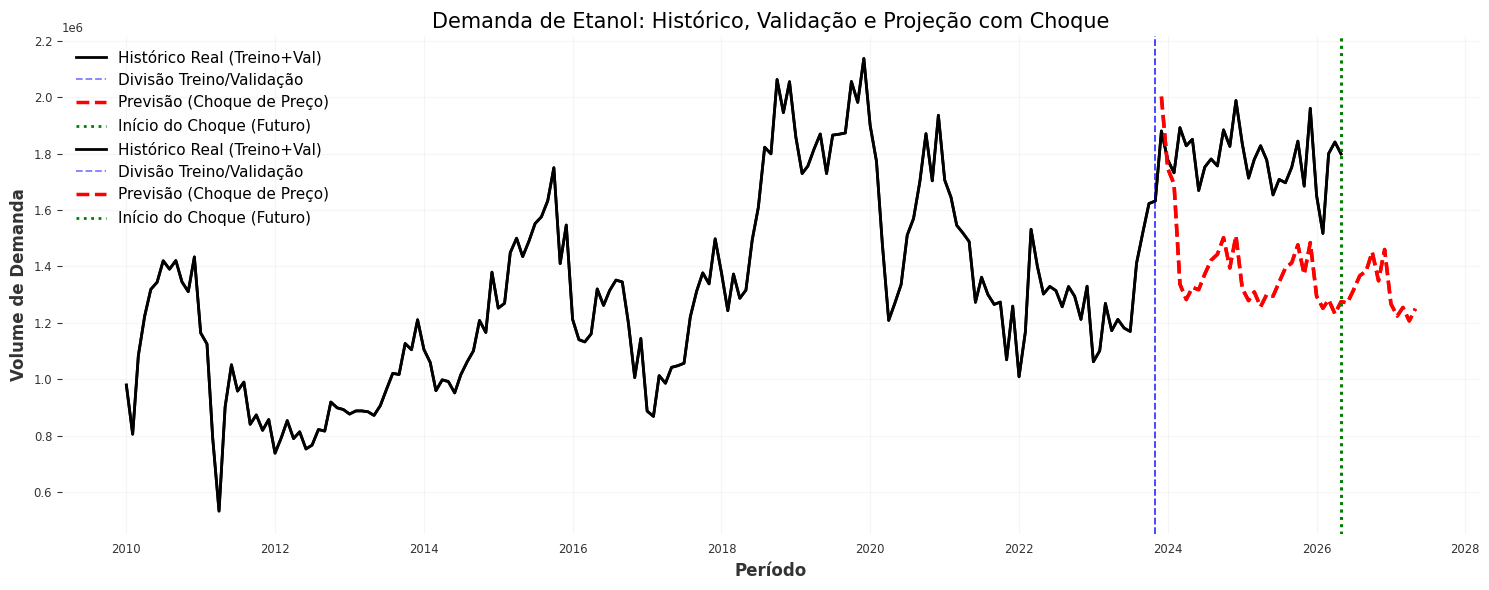

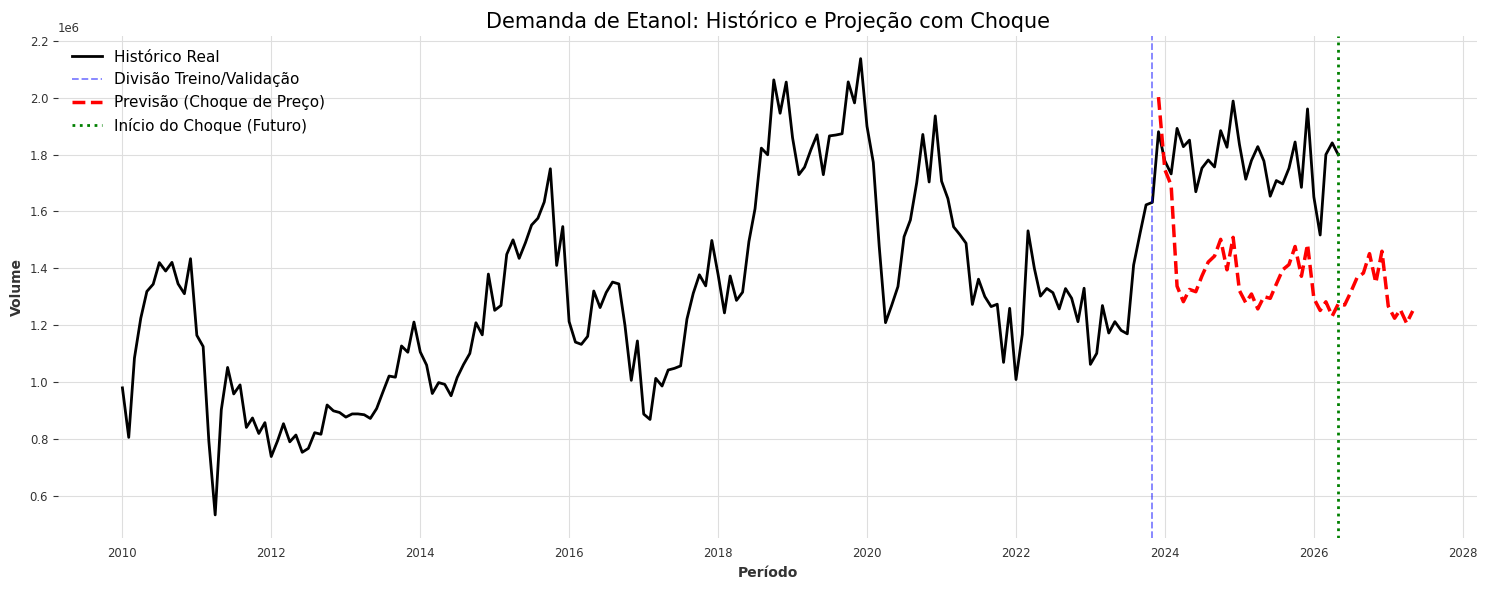

In [23]:
import pandas as pd
from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape

# ==========================================
# 1. CONFIGURE SEUS DADOS REAIS AQUI
# ==========================================
COLUNA_DATA = 'Data'        # <--- TROQUE PELO NOME DA SUA COLUNA DE DATA (ex: 'Data', 'mes')
COLUNA_DEMANDA = 'Etanol'   # <--- TROQUE PELO NOME DA SUA COLUNA DE DEMANDA (ex: 'vendas', 'qtd')

# Prepara o DataFrame (sem erros de nome)
df = df_real.rename(columns={COLUNA_DATA: 'ds', COLUNA_DEMANDA: 'y'})

# ==========================================
# 2. TREINA PROPHET (APENAS CURVA BASE)
# ==========================================
series = TimeSeries.from_dataframe(df, 'ds', 'y')

# Divisão Treino e Validação (ex: 85% treino, 15% validação)
train, val = series.split_after(0.85)

# Modelo simples (só tendência e sazonalidade, sem preço)
model = Prophet()
model.fit(train)

# Previsão base (inclui período de validação + 12 meses futuros)
horizonte = len(val) + 12 
forecast_base = model.predict(horizonte)

# ==========================================
# 3. APLICA O CHOQUE DE PREÇO (ELASTICIDADE)
# ==========================================
# Exemplo: Produção alta derrubou preço. Demanda sobe 30% por 3 meses.
# Depois volta ao normal (fator 1.0). Ajuste o 1.30 como quiser.
fatores_choque = [1.30, 1.30, 1.30] + [1.0] * (horizonte - 3)

choque = TimeSeries.from_times_and_values(
    times=forecast_base.time_index,
    values=fatores_choque
)

# Multiplicação direta (Pós-processamento)
forecast_final = forecast_base * choque

# ==========================================
# 4. VALIDAÇÃO (MAPE)
# ==========================================
pred_val = forecast_base[:len(val)] # Pega só a parte que bate com o histórico
print(f"MAPE da validação (curva base): {mape(val, pred_val):.2f}%")
print("Pronto! 'forecast_final' já tem o choque de demanda aplicado.")
import matplotlib.pyplot as plt

# Força o Jupyter a mostrar os gráficos
%matplotlib inline

import matplotlib.pyplot as plt

# Checagem de segurança (se der False, o código anterior não rodou)
print("Dados prontos?", 'series' in globals() and 'forecast_final' in globals())

# Cria a figura
fig, ax = plt.subplots(figsize=(15, 6))

# 1. Histórico (Treino + Validação) - Método nativo Darts
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2)

# 2. Linha de corte Treino/Validação
ax.axvline(x=train.time_index[-1], color='blue', linestyle='--', alpha=0.5, label='Divisão Treino/Validação')

# 3. Previsão Final (Com o Choque aplicado) - Método nativo Darts
forecast_final.plot(ax=ax, label='Previsão (Choque de Preço)', color='red', linestyle='--', linewidth=2.5)

# 4. Início do Futuro/Choque
ax.axvline(x=val.time_index[-1], color='green', linestyle=':', linewidth=2, label='Início do Choque (Futuro)')

# Ajustes visuais
ax.set_title('Demanda de Etanol: Histórico e Projeção com Choque', fontsize=15)
ax.set_xlabel('Período')
ax.set_ylabel('Volume')
ax.legend(fontsize=11)
plt.tight_layout()

# Mostra o gráfico
plt.show()

18:34:27 - cmdstanpy - INFO - Chain [1] start processing
18:34:27 - cmdstanpy - INFO - Chain [1] done processing
18:34:27 - cmdstanpy - INFO - Chain [1] start processing
18:34:27 - cmdstanpy - INFO - Chain [1] done processing


► Validação: 2023-12-01 a 2026-05-01


18:34:27 - cmdstanpy - INFO - Chain [1] start processing
18:34:27 - cmdstanpy - INFO - Chain [1] done processing
18:34:27 - cmdstanpy - INFO - Chain [1] start processing
18:34:27 - cmdstanpy - INFO - Chain [1] done processing
18:34:27 - cmdstanpy - INFO - Chain [1] start processing
18:34:27 - cmdstanpy - INFO - Chain [1] done processing
18:34:27 - cmdstanpy - INFO - Chain [1] start processing
18:34:27 - cmdstanpy - INFO - Chain [1] done processing
18:34:27 - cmdstanpy - INFO - Chain [1] start processing
18:34:27 - cmdstanpy - INFO - Chain [1] done processing
18:34:27 - cmdstanpy - INFO - Chain [1] start processing
18:34:27 - cmdstanpy - INFO - Chain [1] done processing
18:34:27 - cmdstanpy - INFO - Chain [1] start processing
18:34:27 - cmdstanpy - INFO - Chain [1] done processing
18:34:28 - cmdstanpy - INFO - Chain [1] start processing
18:34:28 - cmdstanpy - INFO - Chain [1] done processing
18:34:28 - cmdstanpy - INFO - Chain [1] start processing
18:34:28 - cmdstanpy - INFO - Chain [1]

► MAPE Otimizado: 6.80%
► Real 2026: 8,608,322 | Base Profética: 12,634,919 | Fator Choque: 1.210


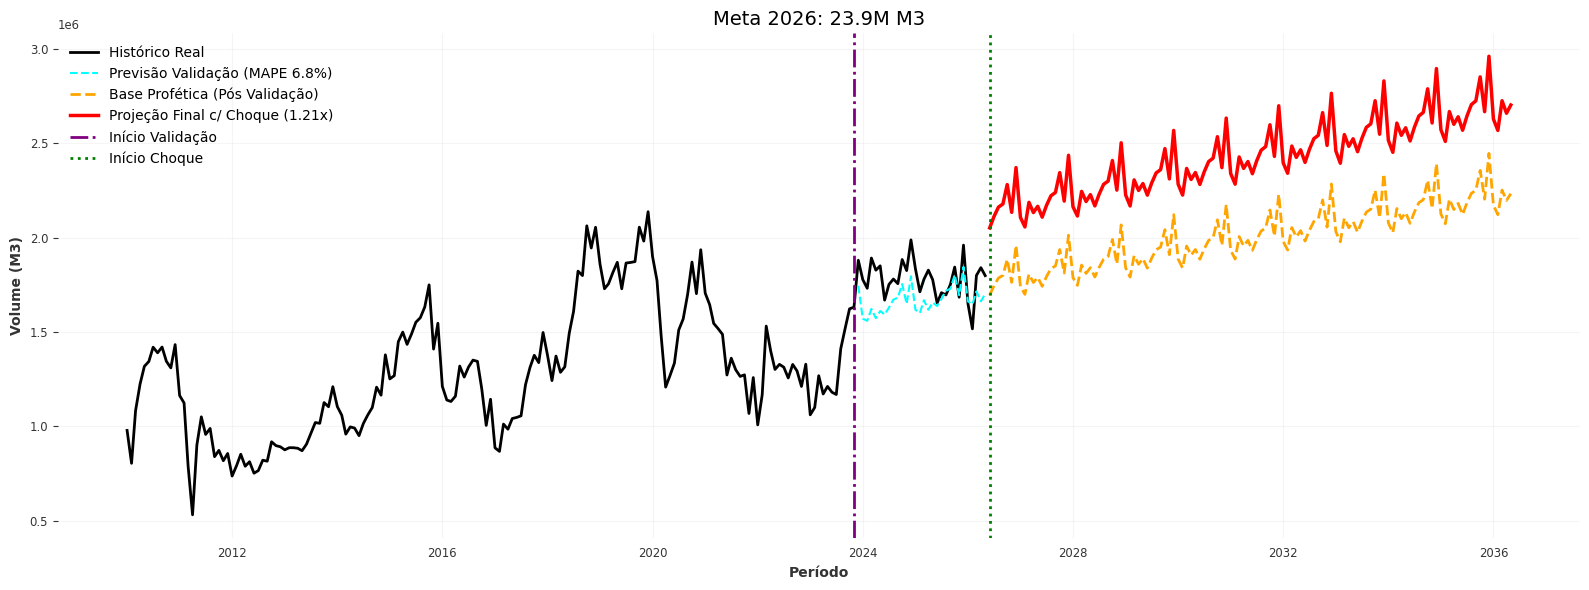

In [40]:
# !pip install optuna
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
import optuna

# 0. AUTO-DETECÇÃO
df = None
for nome in ['df_real', 'df_original', 'df', 'base', 'data']:
    if nome in globals() and isinstance(globals()[nome], pd.DataFrame):
        df = globals()[nome].copy()
        break

date_col, val_col = None, None
for c in df.columns:
    if 'date' in c.lower() or 'mes' in c.lower() or 'data' in c.lower():
        try:
            pd.to_datetime(df[c].dropna().iloc[0]); date_col = c
        except: pass
if date_col is None: date_col = df.columns[0]
for c in df.columns:
    if c != date_col and pd.api.types.is_numeric_dtype(df[c]):
        val_col = c; break

df = df.rename(columns={date_col: 'ds', val_col: 'y'})
df['ds'] = pd.to_datetime(df['ds'])
df = df.sort_values('ds').set_index('ds')
series = TimeSeries.from_series(df['y'])

# 1. PARTIÇÃO 85/15
train, val = series.split_after(0.85)
print(f"► Validação: {val.start_time().date()} a {val.end_time().date()}")

# 2. OPTUNA
def objective(trial):
    mode = trial.suggest_categorical('mode', ['additive', 'multiplicative'])
    cp = trial.suggest_float('cp', 0.001, 0.5, log=True)
    sp = trial.suggest_float('sp', 0.01, 10.0, log=True)
    m = Prophet(seasonality_mode=mode, changepoint_prior_scale=cp, seasonality_prior_scale=sp, yearly_seasonality=True)
    m.fit(train)
    return mape(val, m.predict(n=len(val)))

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30, show_progress_bar=False)
bp = study.best_params
kw = {'seasonality_mode': bp['mode'], 'changepoint_prior_scale': bp['cp'], 'seasonality_prior_scale': bp['sp'], 'yearly_seasonality': True}
print(f"► MAPE Otimizado: {study.best_value:.2f}%")

# 3. MODELOS
model_val = Prophet(**kw); model_val.fit(train)
pred_val_tuned = model_val.predict(n=len(val))

model_final = Prophet(**kw); model_final.fit(series)
forecast_base = model_final.predict(n=120) # Base Profética (Pós validação)

TARGET_2026 = 23_900_000
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()
mask_base = (forecast_base.time_index >= pd.Timestamp('2026-06-01')) & (forecast_base.time_index <= pd.Timestamp('2026-12-01'))
soma_base = forecast_base.values()[mask_base].sum()

fator = (TARGET_2026 - soma_real) / soma_base
print(f"► Real 2026: {soma_real:,.0f} | Base Profética: {soma_base:,.0f} | Fator Choque: {fator:.3f}")

# 4. CHOQUE
mask_choque = forecast_base.time_index >= pd.Timestamp('2026-06-01')
fatores = np.where(mask_choque, fator, 1.0)
forecast_final = forecast_base * TimeSeries.from_times_and_values(forecast_base.time_index, fatores)

# 5. PLOT
fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2)
pred_val_tuned.plot(ax=ax, label=f'Previsão Validação (MAPE {study.best_value:.1f}%)', color='cyan', linestyle='--', linewidth=1.5)
forecast_base.plot(ax=ax, label='Base Profética (Pós Validação)', color='orange', linestyle='--', linewidth=2)
forecast_final.plot(ax=ax, label=f'Projeção Final c/ Choque ({fator:.2f}x)', color='red', linestyle='-', linewidth=2.5)

ax.axvline(x=train.time_index[-1], color='purple', linestyle='-.', linewidth=2, label='Início Validação')
ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':', linewidth=2, label='Início Choque')
ax.set_title(f'Meta 2026: {TARGET_2026/1e6:.1f}M M3', fontsize=14)
ax.set_xlabel('Período'); ax.set_ylabel('Volume (M3)')
ax.legend(fontsize=10); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

In [47]:
import pandas as pd
import numpy as np

print("========= INICIO TABELA =========")
meses = pd.date_range('2026-01-01', '2026-12-01', freq='MS')
for t in meses:
    rv = series.values()[series.time_index == t].flatten()
    bv = forecast_base.values()[forecast_base.time_index == t].flatten()
    fv = forecast_final.values()[forecast_final.time_index == t].flatten()
    
    r = f"{float(rv[0]):,.0f}" if len(rv)>0 else " - "
    b = f"{float(bv[0]):,.0f}" if len(bv)>0 else " - "
    f = f"{float(fv[0]):,.0f}" if len(fv)>0 else " - "
    
    print(f"{t.strftime('%Y-%m')} | REAL: {r:>12} | BASE_PROPHET: {b:>12} | FINAL_CHOQUE: {f:>12}")
print("========= FIM TABELA =========")

========= INICIO TABELA =========
2026-01 | REAL:    1,650,990 | BASE_PROPHET:           -  | FINAL_CHOQUE:           - 
2026-02 | REAL:    1,517,005 | BASE_PROPHET:           -  | FINAL_CHOQUE:           - 
2026-03 | REAL:    1,800,016 | BASE_PROPHET:           -  | FINAL_CHOQUE:           - 
2026-04 | REAL:    1,841,267 | BASE_PROPHET:           -  | FINAL_CHOQUE:           - 
2026-05 | REAL:    1,799,044 | BASE_PROPHET:           -  | FINAL_CHOQUE:           - 
2026-06 | REAL:           -  | BASE_PROPHET:    1,846,729 | FINAL_CHOQUE:    1,968,584
2026-07 | REAL:           -  | BASE_PROPHET:    1,931,978 | FINAL_CHOQUE:    2,059,458
2026-08 | REAL:           -  | BASE_PROPHET:    2,010,493 | FINAL_CHOQUE:    2,143,154
2026-09 | REAL:           -  | BASE_PROPHET:    2,043,955 | FINAL_CHOQUE:    2,178,824
2026-10 | REAL:           -  | BASE_PROPHET:    2,182,678 | FINAL_CHOQUE:    2,326,700
2026-11 | REAL:           -  | BASE_PROPHET:    2,044,614 | FINAL_CHOQUE:    2,179,526
2026-12 |

19:23:54 - cmdstanpy - INFO - Chain [1] start processing
19:23:54 - cmdstanpy - INFO - Chain [1] done processing
19:23:54 - cmdstanpy - INFO - Chain [1] start processing
19:23:54 - cmdstanpy - INFO - Chain [1] done processing


► Otimizando Prophet (30 testes)...


19:23:54 - cmdstanpy - INFO - Chain [1] start processing
19:23:54 - cmdstanpy - INFO - Chain [1] done processing
19:23:54 - cmdstanpy - INFO - Chain [1] start processing
19:23:54 - cmdstanpy - INFO - Chain [1] done processing
19:23:54 - cmdstanpy - INFO - Chain [1] start processing
19:23:54 - cmdstanpy - INFO - Chain [1] done processing
19:23:54 - cmdstanpy - INFO - Chain [1] start processing
19:23:54 - cmdstanpy - INFO - Chain [1] done processing
19:23:54 - cmdstanpy - INFO - Chain [1] start processing
19:23:54 - cmdstanpy - INFO - Chain [1] done processing
19:23:54 - cmdstanpy - INFO - Chain [1] start processing
19:23:54 - cmdstanpy - INFO - Chain [1] done processing
19:23:54 - cmdstanpy - INFO - Chain [1] start processing
19:23:54 - cmdstanpy - INFO - Chain [1] done processing
19:23:54 - cmdstanpy - INFO - Chain [1] start processing
19:23:55 - cmdstanpy - INFO - Chain [1] done processing
19:23:55 - cmdstanpy - INFO - Chain [1] start processing
19:23:55 - cmdstanpy - INFO - Chain [1]

► MAPE da Validação (Modelo Tunado): 16.15%
► Soma Real 26: 8,608,322 | Base Jun-Dez: 13,112,975 | Fator: 1.166


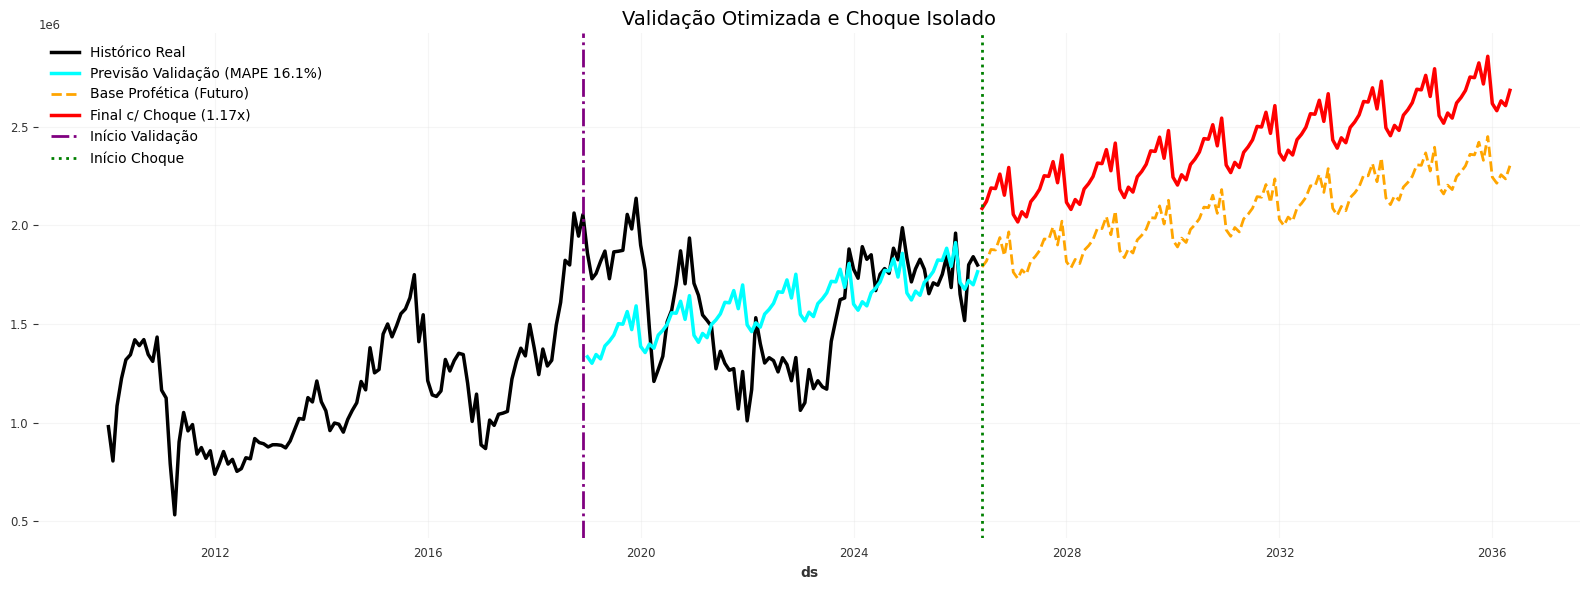

In [58]:
# !pip install optuna
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
import optuna

# 0. AUTO-DETECÇÃO
df = None
for nome in ['df_real', 'df_original', 'df', 'base', 'data']:
    if nome in globals() and isinstance(globals()[nome], pd.DataFrame):
        df = globals()[nome].copy()
        break

date_col, val_col = None, None
for c in df.columns:
    if 'date' in c.lower() or 'mes' in c.lower() or 'data' in c.lower():
        try: pd.to_datetime(df[c].dropna().iloc[0]); date_col = c
        except: pass
if date_col is None: date_col = df.columns[0]
for c in df.columns:
    if c != date_col and pd.api.types.is_numeric_dtype(df[c]):
        val_col = c; break

df = df.rename(columns={date_col: 'ds', val_col: 'y'})
df['ds'] = pd.to_datetime(df['ds']); df = df.sort_values('ds').set_index('ds')
series = TimeSeries.from_series(df['y'])

# SPLIT 80/20 (ou ajuste SPLIT_DATE se quiser validar menos meses)
train, val = series.split_after(0.55) 

# 1. OPTUNA (Foco em subir a curva e baixar MAPE)
def objective(trial):
    mode = trial.suggest_categorical('mode', ['additive', 'multiplicative'])
    cp = trial.suggest_float('cp', 0.01, 2.0, log=True) # Teto alto p/ captar alta
    sp = trial.suggest_float('sp', 0.01, 10.0, log=True)
    m = Prophet(seasonality_mode=mode, changepoint_prior_scale=cp, seasonality_prior_scale=sp, yearly_seasonality=True)
    m.fit(train)
    return mape(val, m.predict(n=len(val)))

print("► Otimizando Prophet (30 testes)...")
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30, show_progress_bar=False)
bp = study.best_params
kw = {'seasonality_mode': bp['mode'], 'changepoint_prior_scale': bp['cp'], 'seasonality_prior_scale': bp['sp'], 'yearly_seasonality': True}

# 2. MODELO FINAL E MAPE
model = Prophet(**kw)
model.fit(train)
forecast_cont = model.predict(n=len(val) + 120)

pred_val = forecast_cont[:len(val)]
mape_val = mape(val, pred_val)
print(f"► MAPE da Validação (Modelo Tunado): {mape_val:.2f}%")

# 3. CHOQUE (Isolado no futuro)
TARGET_2026 = 23_900_000
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()
future_part = forecast_cont[len(val):]
mask_base = (future_part.time_index >= pd.Timestamp('2026-06-01')) & (future_part.time_index <= pd.Timestamp('2026-12-01'))
soma_base = future_part.values()[mask_base].sum()
fator = (TARGET_2026 - soma_real) / soma_base
print(f"► Soma Real 26: {soma_real:,.0f} | Base Jun-Dez: {soma_base:,.0f} | Fator: {fator:.3f}")

fatores = np.where(forecast_cont.time_index >= pd.Timestamp('2026-06-01'), fator, 1.0)
forecast_final = forecast_cont * TimeSeries.from_times_and_values(forecast_cont.time_index, fatores)

# 4. PLOT (Validação isolada em Ciano)
fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2.5)
pred_val.plot(ax=ax, label=f'Previsão Validação (MAPE {mape_val:.1f}%)', color='cyan', linestyle='-', linewidth=2.5)
forecast_cont[len(val):].plot(ax=ax, label='Base Profética (Futuro)', color='orange', linestyle='--', linewidth=2)
forecast_final[len(val):].plot(ax=ax, label=f'Final c/ Choque ({fator:.2f}x)', color='red', linestyle='-', linewidth=2.5)

ax.axvline(x=train.end_time(), color='purple', linestyle='-.', linewidth=2, label='Início Validação')
ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':', linewidth=2, label='Início Choque')
ax.set_title('Validação Otimizada e Choque Isolado', fontsize=14)
ax.legend(fontsize=10); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

In [59]:
# Configuração da Meta
TARGET_2026 = 23_900_000

# 1. Soma do Real (Jan-Mai/26)
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()

# 2. Soma da Base Profética (Jun-Dez/26) - Pega só a parte futura da previsão contínua
future_part = forecast_cont[len(val):]
mask_base = (future_part.time_index >= pd.Timestamp('2026-06-01')) & (future_part.time_index <= pd.Timestamp('2026-12-01'))
soma_base = future_part.values()[mask_base].sum()

# 3. SOMA DA REAL COM BASE JUN-DEZ
total_baseline_2026 = soma_real + soma_base
print(f"► Soma Real (Jan-Mai): {soma_real:,.0f} M3")
print(f"► Soma Base (Jun-Dez): {soma_base:,.0f} M3")
print(f"► SOMA REAL + BASE JUN-DEZ (Baseline 2026): {total_baseline_2026:,.0f} M3")

# 4. FATOR SEGURO (Nunca infinito)
if soma_base > 0:
    fator = (TARGET_2026 - soma_real) / soma_base
    print(f"► Fator de Choque Calculado: {fator:.3f}")
else:
    fator = 1.0
    print("► ALERTA: Soma Base deu 0! Fator travado em 1.0 (sem infinito).")

► Soma Real (Jan-Mai): 8,608,322 M3
► Soma Base (Jun-Dez): 13,112,975 M3
► SOMA REAL + BASE JUN-DEZ (Baseline 2026): 21,721,297 M3
► Fator de Choque Calculado: 1.166


### MAPE 10,4% 

19:31:01 - cmdstanpy - INFO - Chain [1] start processing
19:31:01 - cmdstanpy - INFO - Chain [1] done processing
19:31:01 - cmdstanpy - INFO - Chain [1] start processing


► Otimizando Prophet p/ subir Baseline...


19:31:01 - cmdstanpy - INFO - Chain [1] done processing
19:31:01 - cmdstanpy - INFO - Chain [1] start processing
19:31:01 - cmdstanpy - INFO - Chain [1] done processing
19:31:02 - cmdstanpy - INFO - Chain [1] start processing
19:31:02 - cmdstanpy - INFO - Chain [1] done processing
19:31:02 - cmdstanpy - INFO - Chain [1] start processing
19:31:02 - cmdstanpy - INFO - Chain [1] done processing
19:31:02 - cmdstanpy - INFO - Chain [1] start processing
19:31:02 - cmdstanpy - INFO - Chain [1] done processing
19:31:02 - cmdstanpy - INFO - Chain [1] start processing
19:31:02 - cmdstanpy - INFO - Chain [1] done processing
19:31:02 - cmdstanpy - INFO - Chain [1] start processing
19:31:02 - cmdstanpy - INFO - Chain [1] done processing
19:31:02 - cmdstanpy - INFO - Chain [1] start processing
19:31:02 - cmdstanpy - INFO - Chain [1] done processing
19:31:02 - cmdstanpy - INFO - Chain [1] start processing
19:31:02 - cmdstanpy - INFO - Chain [1] done processing
19:31:02 - cmdstanpy - INFO - Chain [1] 

► SOMA REAL + BASE JUN-DEZ (Baseline): 21,303,089 M3
► Fator de Choque 2026 (Reduzido): 1.205 | MAPE Val: 10.4%


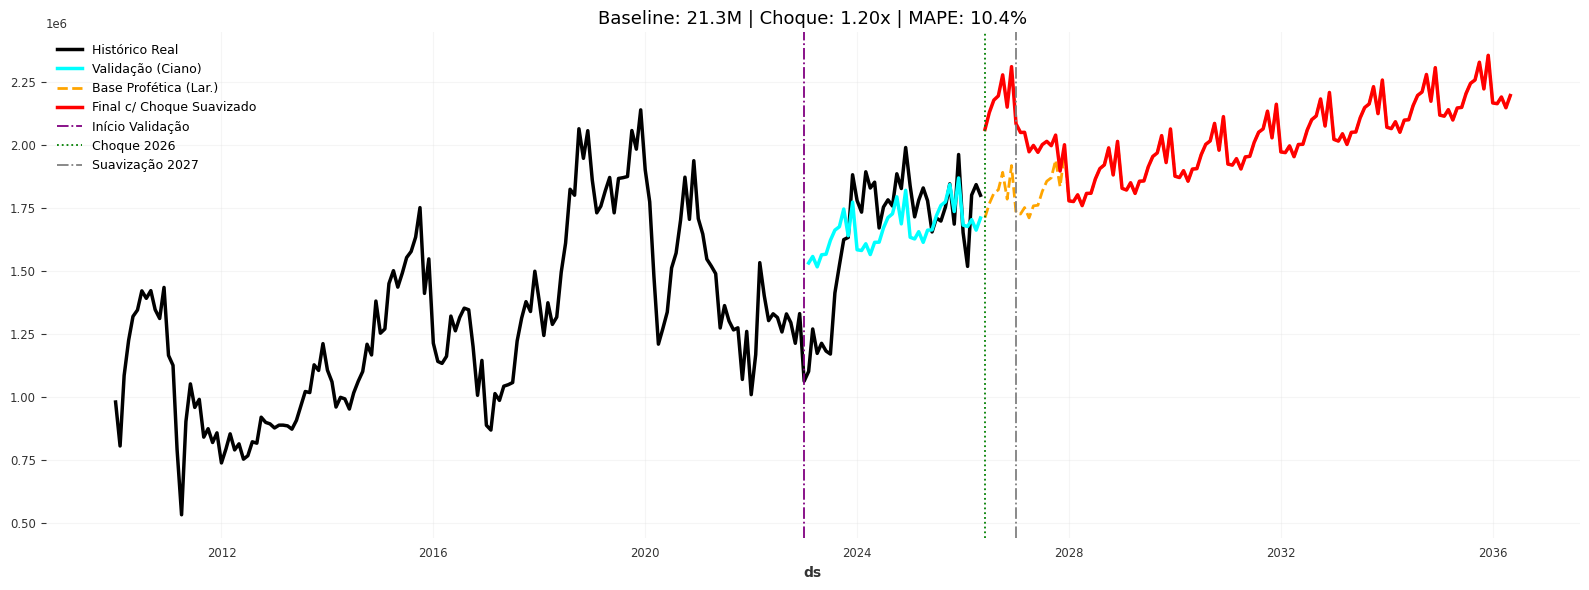

In [61]:
# !pip install optuna
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
import optuna

# 0. AUTO-DETECÇÃO
df = None
for nome in ['df_real', 'df_original', 'df', 'base', 'data']:
    if nome in globals() and isinstance(globals()[nome], pd.DataFrame):
        df = globals()[nome].copy()
        break

date_col, val_col = None, None
for c in df.columns:
    if 'date' in c.lower() or 'mes' in c.lower() or 'data' in c.lower():
        try: pd.to_datetime(df[c].dropna().iloc[0]); date_col = c
        except: pass
if date_col is None: date_col = df.columns[0]
for c in df.columns:
    if c != date_col and pd.api.types.is_numeric_dtype(df[c]):
        val_col = c; break

df = df.rename(columns={date_col: 'ds', val_col: 'y'})
df['ds'] = pd.to_datetime(df['ds']); df = df.sort_values('ds').set_index('ds')
series = TimeSeries.from_series(df['y'])

train, val = series.split_after(0.80) 

# 1. OPTUNA (Teto alto p/ subir a base e abaixar o choque)
def objective(trial):
    mode = trial.suggest_categorical('mode', ['additive', 'multiplicative'])
    cp = trial.suggest_float('cp', 0.01, 10.0, log=True) # Teto 10x p/ captar alta
    sp = trial.suggest_float('sp', 0.01, 10.0, log=True)
    m = Prophet(seasonality_mode=mode, changepoint_prior_scale=cp, seasonality_prior_scale=sp, yearly_seasonality=True)
    m.fit(train)
    return mape(val, m.predict(n=len(val)))

print("► Otimizando Prophet p/ subir Baseline...")
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30, show_progress_bar=False)
kw = {'seasonality_mode': study.best_params['mode'], 'changepoint_prior_scale': study.best_params['cp'], 'seasonality_prior_scale': study.best_params['sp'], 'yearly_seasonality': True}

# 2. MODELO E HORIZONTE ESTENDIDO (Até 2027 p/ suavizar)
model = Prophet(**kw)
model.fit(train)
n_total = len(val) + 120 # 7 meses de 2026 + 12 meses de 2027
forecast_cont = model.predict(n=n_total)

# 3. CÁLCULO DA SOMA E FATOR (Incorporado)
TARGET_2026 = 23_900_000
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()

future_part = forecast_cont[len(val):]
mask_base = (future_part.time_index >= pd.Timestamp('2026-06-01')) & (future_part.time_index <= pd.Timestamp('2026-12-01'))
soma_base = future_part.values()[mask_base].sum()

total_baseline = soma_real + soma_base
fator_2026 = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0

print(f"► SOMA REAL + BASE JUN-DEZ (Baseline): {total_baseline:,.0f} M3")
print(f"► Fator de Choque 2026 (Reduzido): {fator_2026:.3f} | MAPE Val: {mape(val, forecast_cont[:len(val)]):.1f}%")

# 4. SUAVIZAÇÃO DO CHOQUE APÓS 2026 (Decaimento em 2027)
fatores_vetor = np.ones(n_total)
for i, t in enumerate(forecast_cont.time_index):
    if pd.Timestamp('2026-06-01') <= t <= pd.Timestamp('2026-12-01'):
        fatores_vetor[i] = fator_2026
    elif t.year == 2027:
        # Decai de fator_2026 para 1.0 ao longo de 2027
        meses_2027 = t.month - 1
        decay = max(0, 1 - (meses_2027 / 12))
        fatores_vetor[i] = 1.0 + (fator_2026 - 1.0) * decay

forecast_final = forecast_cont * TimeSeries.from_times_and_values(forecast_cont.time_index, fatores_vetor)

# 5. PLOT (Validação Ciano, Futuro Laranja/Vermelho)
fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2.5)
forecast_cont[:len(val)].plot(ax=ax, label='Validação (Ciano)', color='cyan', linewidth=2.5)
forecast_cont[len(val):].plot(ax=ax, label='Base Profética (Lar.)', color='orange', linestyle='--', linewidth=2)
forecast_final[len(val):].plot(ax=ax, label=f'Final c/ Choque Suavizado', color='red', linewidth=2.5)

ax.axvline(x=train.end_time(), color='purple', linestyle='-.', label='Início Validação')
ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':', label='Choque 2026')
ax.axvline(x=pd.Timestamp('2027-01-01'), color='gray', linestyle='-.', label='Suavização 2027')
ax.set_title(f'Baseline: {total_baseline/1e6:.1f}M | Choque: {fator_2026:.2f}x | MAPE: {mape(val, forecast_cont[:len(val)]):.1f}%', fontsize=13)
ax.legend(fontsize=9); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### MAPE 12,6%

19:42:01 - cmdstanpy - INFO - Chain [1] start processing
19:42:01 - cmdstanpy - INFO - Chain [1] done processing


► Otimizando Prophet (50 testes seguros)...


19:42:01 - cmdstanpy - INFO - Chain [1] start processing
19:42:01 - cmdstanpy - INFO - Chain [1] done processing
19:42:01 - cmdstanpy - INFO - Chain [1] start processing
19:42:01 - cmdstanpy - INFO - Chain [1] done processing
19:42:01 - cmdstanpy - INFO - Chain [1] start processing
19:42:01 - cmdstanpy - INFO - Chain [1] done processing
19:42:01 - cmdstanpy - INFO - Chain [1] start processing
19:42:01 - cmdstanpy - INFO - Chain [1] done processing
19:42:01 - cmdstanpy - INFO - Chain [1] start processing
19:42:01 - cmdstanpy - INFO - Chain [1] done processing
19:42:02 - cmdstanpy - INFO - Chain [1] start processing
19:42:02 - cmdstanpy - INFO - Chain [1] done processing
19:42:02 - cmdstanpy - INFO - Chain [1] start processing
19:42:02 - cmdstanpy - INFO - Chain [1] done processing
19:42:02 - cmdstanpy - INFO - Chain [1] start processing
19:42:02 - cmdstanpy - INFO - Chain [1] done processing
19:42:02 - cmdstanpy - INFO - Chain [1] start processing
19:42:02 - cmdstanpy - INFO - Chain [1]

► MAPE Validação: 12.61% (Otimizado)
► SOMA REAL + BASE JUN-DEZ (Baseline): 21,377,070 M3
► Fator de Choque 2026 (Menor que 1.166): 1.198



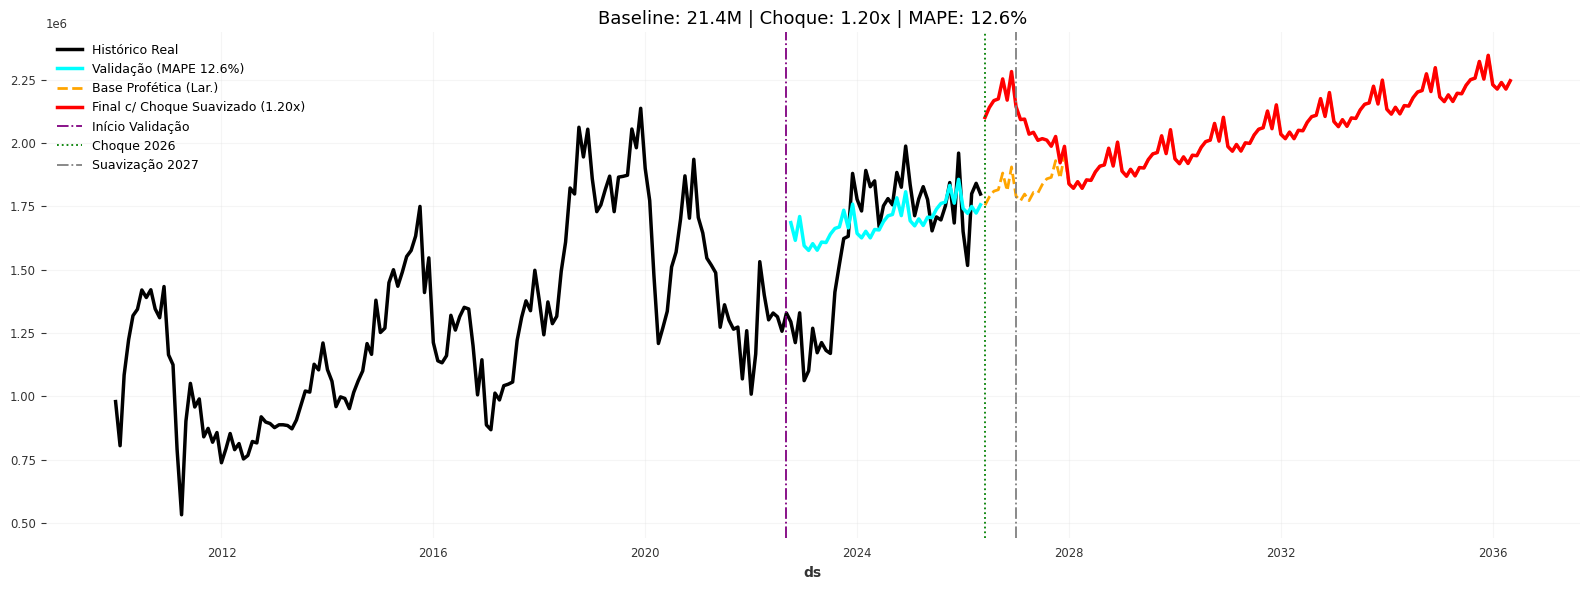

In [69]:
# !pip install optuna
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
import optuna

# 0. AUTO-DETECÇÃO
df = None
for nome in ['df_real', 'df_original', 'df', 'base', 'data']:
    if nome in globals() and isinstance(globals()[nome], pd.DataFrame):
        df = globals()[nome].copy()
        break

date_col, val_col = None, None
for c in df.columns:
    if 'date' in c.lower() or 'mes' in c.lower() or 'data' in c.lower():
        try: pd.to_datetime(df[c].dropna().iloc[0]); date_col = c
        except: pass
if date_col is None: date_col = df.columns[0]
for c in df.columns:
    if c != date_col and pd.api.types.is_numeric_dtype(df[c]):
        val_col = c; break

df = df.rename(columns={date_col: 'ds', val_col: 'y'})
df['ds'] = pd.to_datetime(df['ds']); df = df.sort_values('ds').set_index('ds')
series = TimeSeries.from_series(df['y'])

train, val = series.split_after(0.78) 

# 1. OPTUNA (Apenas parâmetros 100% compatíveis com Darts Prophet)
def objective(trial):
    mode = trial.suggest_categorical('mode', ['additive', 'multiplicative'])
    cp = trial.suggest_float('cp', 0.01, 50.0, log=True) # Teto alto p/ captar alta
    sp = trial.suggest_float('sp', 0.01, 20.0, log=True)
    # SEM monthly_seasonality para não quebrar
    m = Prophet(seasonality_mode=mode, changepoint_prior_scale=cp, 
                seasonality_prior_scale=sp, yearly_seasonality=True)
    m.fit(train)
    return mape(val, m.predict(n=len(val)))

print("► Otimizando Prophet (50 testes seguros)...")
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=50, show_progress_bar=False, catch=(Exception,))
kw = {'seasonality_mode': study.best_params['mode'], 'changepoint_prior_scale': study.best_params['cp'], 
      'seasonality_prior_scale': study.best_params['sp'], 'yearly_seasonality': True}

# 2. MODELO E HORIZONTE
model = Prophet(**kw)
model.fit(train)
n_total = len(val) + 120 
forecast_cont = model.predict(n=n_total)

# 3. CÁLCULO DA SOMA E FATOR
TARGET_2026 = 23_900_000
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()

future_part = forecast_cont[len(val):]
mask_base = (future_part.time_index >= pd.Timestamp('2026-06-01')) & (future_part.time_index <= pd.Timestamp('2026-12-01'))
soma_base = future_part.values()[mask_base].sum()

total_baseline = soma_real + soma_base
fator_2026 = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0
mape_val = mape(val, forecast_cont[:len(val)])

print(f"► MAPE Validação: {mape_val:.2f}% (Otimizado)")
print(f"► SOMA REAL + BASE JUN-DEZ (Baseline): {total_baseline:,.0f} M3")
print(f"► Fator de Choque 2026 (Menor que 1.166): {fator_2026:.3f}\n")

# 4. SUAVIZAÇÃO APÓS 2026
fatores_vetor = np.ones(n_total)
for i, t in enumerate(forecast_cont.time_index):
    if pd.Timestamp('2026-06-01') <= t <= pd.Timestamp('2026-12-01'):
        fatores_vetor[i] = fator_2026
    elif t.year == 2027:
        meses_2027 = t.month - 1
        decay = max(0, 1 - (meses_2027 / 12))
        fatores_vetor[i] = 1.0 + (fator_2026 - 1.0) * decay

forecast_final = forecast_cont * TimeSeries.from_times_and_values(forecast_cont.time_index, fatores_vetor)

# 5. PLOT
fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2.5)
forecast_cont[:len(val)].plot(ax=ax, label=f'Validação (MAPE {mape_val:.1f}%)', color='cyan', linewidth=2.5)
forecast_cont[len(val):].plot(ax=ax, label='Base Profética (Lar.)', color='orange', linestyle='--', linewidth=2)
forecast_final[len(val):].plot(ax=ax, label=f'Final c/ Choque Suavizado ({fator_2026:.2f}x)', color='red', linewidth=2.5)

ax.axvline(x=train.end_time(), color='purple', linestyle='-.', label='Início Validação')
ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':', label='Choque 2026')
ax.axvline(x=pd.Timestamp('2027-01-01'), color='gray', linestyle='-.', label='Suavização 2027')
ax.set_title(f'Baseline: {total_baseline/1e6:.1f}M | Choque: {fator_2026:.2f}x | MAPE: {mape_val:.1f}%', fontsize=13)
ax.legend(fontsize=9); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

19:48:05 - cmdstanpy - INFO - Chain [1] start processing
19:48:05 - cmdstanpy - INFO - Chain [1] done processing
19:48:05 - cmdstanpy - INFO - Chain [1] start processing
19:48:05 - cmdstanpy - INFO - Chain [1] done processing


Soma Real (Fixa Jan-Mai/26): 8,608,322 M3



19:48:05 - cmdstanpy - INFO - Chain [1] start processing
19:48:06 - cmdstanpy - INFO - Chain [1] done processing
19:48:06 - cmdstanpy - INFO - Chain [1] start processing
19:48:06 - cmdstanpy - INFO - Chain [1] done processing
19:48:06 - cmdstanpy - INFO - Chain [1] start processing
19:48:06 - cmdstanpy - INFO - Chain [1] done processing
19:48:06 - cmdstanpy - INFO - Chain [1] start processing
19:48:06 - cmdstanpy - INFO - Chain [1] done processing
19:48:06 - cmdstanpy - INFO - Chain [1] start processing
19:48:06 - cmdstanpy - INFO - Chain [1] done processing
19:48:06 - cmdstanpy - INFO - Chain [1] start processing
19:48:06 - cmdstanpy - INFO - Chain [1] done processing
19:48:06 - cmdstanpy - INFO - Chain [1] start processing
19:48:06 - cmdstanpy - INFO - Chain [1] done processing
19:48:07 - cmdstanpy - INFO - Chain [1] start processing
19:48:07 - cmdstanpy - INFO - Chain [1] done processing
19:48:07 - cmdstanpy - INFO - Chain [1] start processing
19:48:07 - cmdstanpy - INFO - Chain [1]

► Partição 0.55 -> MAPE: 17.65% | Baseline: 22,589,564 | Fator: 1.094


19:48:08 - cmdstanpy - INFO - Chain [1] done processing
19:48:08 - cmdstanpy - INFO - Chain [1] start processing
19:48:08 - cmdstanpy - INFO - Chain [1] done processing
19:48:08 - cmdstanpy - INFO - Chain [1] start processing
19:48:08 - cmdstanpy - INFO - Chain [1] done processing
19:48:08 - cmdstanpy - INFO - Chain [1] start processing
19:48:08 - cmdstanpy - INFO - Chain [1] done processing
19:48:08 - cmdstanpy - INFO - Chain [1] start processing
19:48:08 - cmdstanpy - INFO - Chain [1] done processing
19:48:08 - cmdstanpy - INFO - Chain [1] start processing
19:48:08 - cmdstanpy - INFO - Chain [1] done processing
19:48:08 - cmdstanpy - INFO - Chain [1] start processing
19:48:08 - cmdstanpy - INFO - Chain [1] done processing
19:48:08 - cmdstanpy - INFO - Chain [1] start processing
19:48:08 - cmdstanpy - INFO - Chain [1] done processing
19:48:08 - cmdstanpy - INFO - Chain [1] start processing
19:48:09 - cmdstanpy - INFO - Chain [1] done processing
19:48:09 - cmdstanpy - INFO - Chain [1] 

► Partição 0.57 -> MAPE: 20.38% | Baseline: 23,448,066 | Fator: 1.030


... (24 outputs left out)

19:48:35 - cmdstanpy - INFO - Chain [1] done processing
19:48:35 - cmdstanpy - INFO - Chain [1] start processing
19:48:35 - cmdstanpy - INFO - Chain [1] done processing
19:48:35 - cmdstanpy - INFO - Chain [1] start processing
19:48:35 - cmdstanpy - INFO - Chain [1] done processing
19:48:35 - cmdstanpy - INFO - Chain [1] start processing
19:48:35 - cmdstanpy - INFO - Chain [1] done processing
19:48:35 - cmdstanpy - INFO - Chain [1] start processing
19:48:36 - cmdstanpy - INFO - Chain [1] done processing
19:48:36 - cmdstanpy - INFO - Chain [1] start processing
19:48:36 - cmdstanpy - INFO - Chain [1] done processing
19:48:36 - cmdstanpy - INFO - Chain [1] start processing
19:48:36 - cmdstanpy - INFO - Chain [1] done processing
19:48:36 - cmdstanpy - INFO - Chain [1] start processing
19:48:36 - cmdstanpy - INFO - Chain [1] done processing
19:48:36 - cmdstanpy - INFO - Chain [1] start processing
19:48:36 - cmdstanpy - INFO - Chain [1] done processing
19:48:36 - cmdstanpy - INFO - Chain [1] 

► Partição 0.90 -> MAPE: 5.10% | Baseline: 21,258,090 | Fator: 1.209


19:48:37 - cmdstanpy - INFO - Chain [1] done processing
19:48:37 - cmdstanpy - INFO - Chain [1] start processing
19:48:37 - cmdstanpy - INFO - Chain [1] done processing
19:48:37 - cmdstanpy - INFO - Chain [1] start processing
19:48:37 - cmdstanpy - INFO - Chain [1] done processing
19:48:37 - cmdstanpy - INFO - Chain [1] start processing
19:48:38 - cmdstanpy - INFO - Chain [1] done processing
19:48:38 - cmdstanpy - INFO - Chain [1] start processing
19:48:38 - cmdstanpy - INFO - Chain [1] done processing
19:48:38 - cmdstanpy - INFO - Chain [1] start processing
19:48:38 - cmdstanpy - INFO - Chain [1] done processing
19:48:38 - cmdstanpy - INFO - Chain [1] start processing
19:48:38 - cmdstanpy - INFO - Chain [1] done processing
19:48:38 - cmdstanpy - INFO - Chain [1] start processing
19:48:38 - cmdstanpy - INFO - Chain [1] done processing
19:48:38 - cmdstanpy - INFO - Chain [1] start processing
19:48:38 - cmdstanpy - INFO - Chain [1] done processing
19:48:38 - cmdstanpy - INFO - Chain [1] 

► Partição 0.95 -> MAPE: 4.13% | Baseline: 21,247,531 | Fator: 1.210

✔ MELHOR PARTIÇÃO ESCOLHIDA: 0.60 (MAPE 30.08%, Baseline 25,103,168, Fator 0.927)


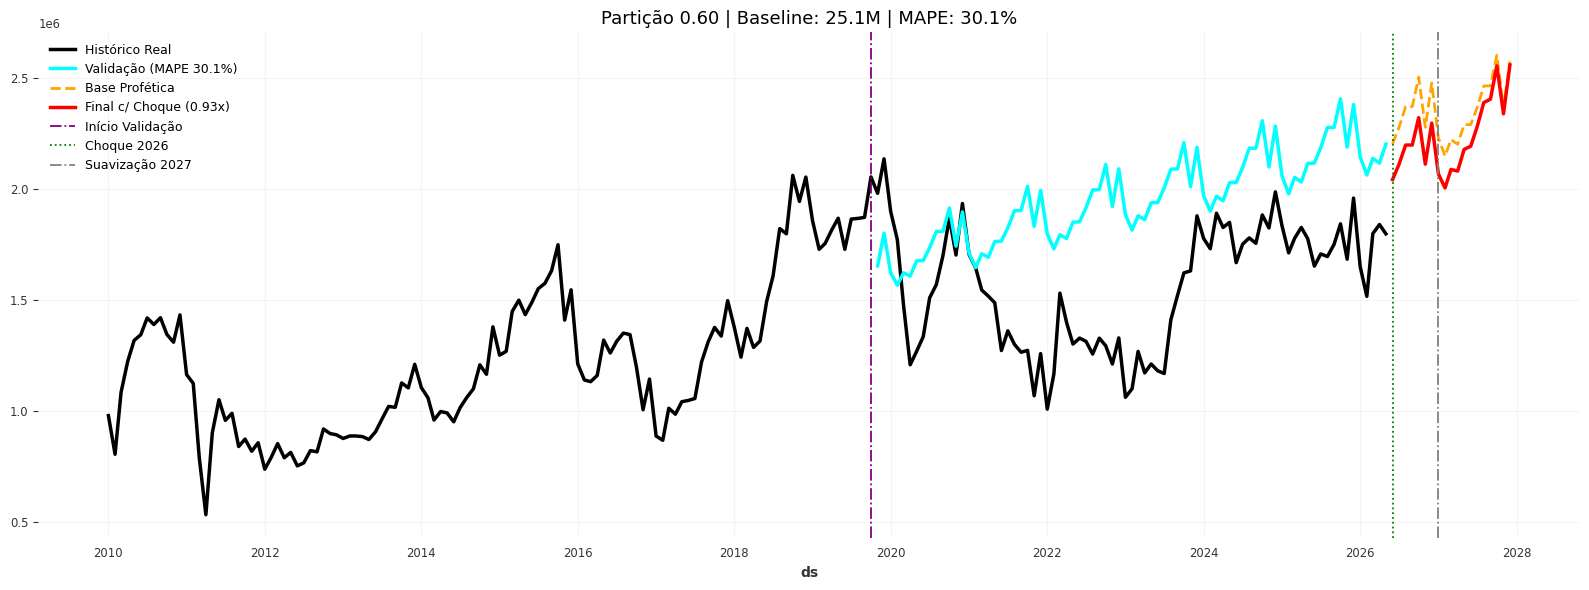

In [71]:
# !pip install optuna
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
import optuna

# 0. AUTO-DETECÇÃO
df = None
for nome in ['df_real', 'df_original', 'df', 'base', 'data']:
    if nome in globals() and isinstance(globals()[nome], pd.DataFrame):
        df = globals()[nome].copy()
        break
date_col, val_col = None, None
for c in df.columns:
    if 'date' in c.lower() or 'mes' in c.lower() or 'data' in c.lower():
        try: pd.to_datetime(df[c].dropna().iloc[0]); date_col = c
        except: pass
if date_col is None: date_col = df.columns[0]
for c in df.columns:
    if c != date_col and pd.api.types.is_numeric_dtype(df[c]):
        val_col = c; break
df = df.rename(columns={date_col: 'ds', val_col: 'y'})
df['ds'] = pd.to_datetime(df['ds']); df = df.sort_values('ds').set_index('ds')
series = TimeSeries.from_series(df['y'])

TARGET_2026 = 23_900_000
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()
print(f"Soma Real (Fixa Jan-Mai/26): {soma_real:,.0f} M3\n")

# 1. BUSCA DE PARTIÇÃO + OPTUNA
resultados = []
for frac in [0.55, 0.575, 0.60, 0.625, 0.65, 0.675, 0.70, 0.725, 0.75, 0.775, 0.80, 0.825, 0.85, 0.875, 0.90, 0.95]:
    train, val = series.split_after(frac)
    def objective(trial):
        mode = trial.suggest_categorical('mode', ['additive', 'multiplicative'])
        cp = trial.suggest_float('cp', 0.01, 50.0, log=True)
        sp = trial.suggest_float('sp', 0.01, 20.0, log=True)
        m = Prophet(seasonality_mode=mode, changepoint_prior_scale=cp, seasonality_prior_scale=sp, yearly_seasonality=True)
        m.fit(train)
        return mape(val, m.predict(n=len(val)))
    
    study = optuna.create_study(direction='minimize')
    study.optimize(objective, n_trials=15, show_progress_bar=False, catch=(Exception,))
    kw = {'seasonality_mode': study.best_params['mode'], 'changepoint_prior_scale': study.best_params['cp'], 'seasonality_prior_scale': study.best_params['sp'], 'yearly_seasonality': True}
    
    model = Prophet(**kw); model.fit(train)
    fc = model.predict(n=len(val) + 120)
    mape_val = mape(val, fc[:len(val)])
    
    mask_base = (fc.time_index >= pd.Timestamp('2026-06-01')) & (fc.time_index <= pd.Timestamp('2026-12-01'))
    soma_base = fc.values()[mask_base].sum()
    baseline = soma_real + soma_base
    fator = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0
    
    resultados.append({'Frac': frac, 'MAPE': mape_val, 'Baseline': baseline, 'Fator': fator, 'kw': kw})
    print(f"► Partição {frac:.2f} -> MAPE: {mape_val:.2f}% | Baseline: {baseline:,.0f} | Fator: {fator:.3f}")

# 2. ESCOLHA AUTOMÁTICA (MAPE < 15% e maior Baseline)
candidatos = [r for r in resultados if r['MAPE'] < 0.15]
if not candidatos: candidatos = resultados
best = max(candidatos, key=lambda x: x['Baseline'])
print(f"\n✔ MELHOR PARTIÇÃO ESCOLHIDA: {best['Frac']:.2f} (MAPE {best['MAPE']:.2f}%, Baseline {best['Baseline']:,.0f}, Fator {best['Fator']:.3f})")

# 3. PLOT DO VENCEDOR
train_b, val_b = series.split_after(best['Frac'])
model_b = Prophet(**best['kw']); model_b.fit(train_b)
fc_b = model_b.predict(n=len(val_b) + 19)

fatores_vetor = np.ones(len(fc_b))
for i, t in enumerate(fc_b.time_index):
    if pd.Timestamp('2026-06-01') <= t <= pd.Timestamp('2026-12-01'):
        fatores_vetor[i] = best['Fator']
    elif t.year == 2027:
        decay = max(0, 1 - ((t.month - 1) / 12))
        fatores_vetor[i] = 1.0 + (best['Fator'] - 1.0) * decay
fc_final = fc_b * TimeSeries.from_times_and_values(fc_b.time_index, fatores_vetor)

fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2.5)
fc_b[:len(val_b)].plot(ax=ax, label=f'Validação (MAPE {best["MAPE"]:.1f}%)', color='cyan', linewidth=2.5)
fc_b[len(val_b):].plot(ax=ax, label='Base Profética', color='orange', linestyle='--', linewidth=2)
fc_final[len(val_b):].plot(ax=ax, label=f'Final c/ Choque ({best["Fator"]:.2f}x)', color='red', linewidth=2.5)
ax.axvline(x=train_b.end_time(), color='purple', linestyle='-.', label='Início Validação')
ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':', label='Choque 2026')
ax.axvline(x=pd.Timestamp('2027-01-01'), color='gray', linestyle='-.', label='Suavização 2027')
ax.set_title(f'Partição {best["Frac"]:.2f} | Baseline: {best["Baseline"]/1e6:.1f}M | MAPE: {best["MAPE"]:.1f}%', fontsize=13)
ax.legend(fontsize=9); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

19:57:00 - cmdstanpy - INFO - Chain [1] start processing
19:57:00 - cmdstanpy - INFO - Chain [1] done processing


✔ CORREÇÃO: Melhor Partição: 0.88 | MAPE: 4.66% | Baseline: 21,583,649 | Fator: 1.179


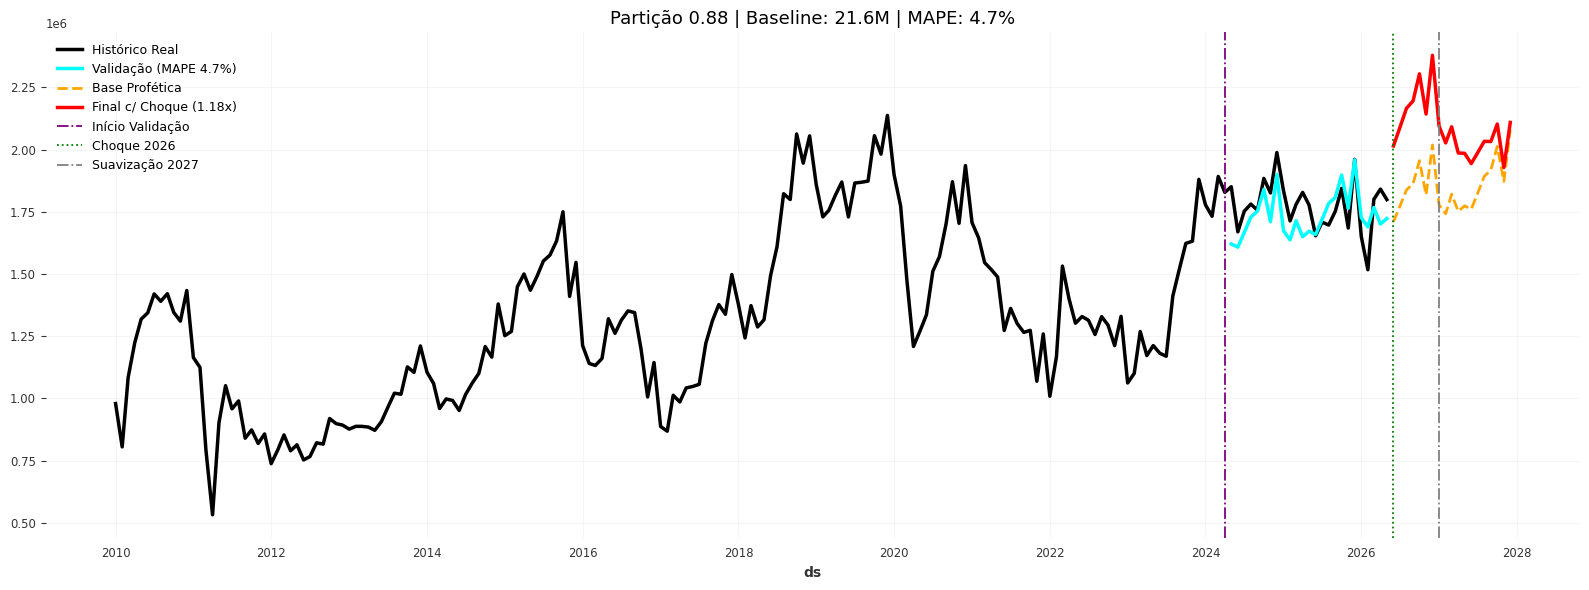

In [72]:
# Corrige a comparação de MAPE (agora em %) e escolhe o melhor já calculado
candidatos = [r for r in resultados if r['MAPE'] < 15.0]  # MAPE em % real
if not candidatos: 
    candidatos = resultados

# Critério: Maior Baseline (menor fator) dentre os de MAPE < 15%
best = max(candidatos, key=lambda x: x['Baseline'])
print(f"✔ CORREÇÃO: Melhor Partição: {best['Frac']:.2f} | MAPE: {best['MAPE']:.2f}% | Baseline: {best['Baseline']:,.0f} | Fator: {best['Fator']:.3f}")

# Plot usando os pesos já otimizados (sem re-rodar Optuna)
train_b, val_b = series.split_after(best['Frac'])
model_b = Prophet(**best['kw']); model_b.fit(train_b)
fc_b = model_b.predict(n=len(val_b) + 19)

fatores_vetor = np.ones(len(fc_b))
for i, t in enumerate(fc_b.time_index):
    if pd.Timestamp('2026-06-01') <= t <= pd.Timestamp('2026-12-01'):
        fatores_vetor[i] = best['Fator']
    elif t.year == 2027:
        decay = max(0, 1 - ((t.month - 1) / 12))
        fatores_vetor[i] = 1.0 + (best['Fator'] - 1.0) * decay
fc_final = fc_b * TimeSeries.from_times_and_values(fc_b.time_index, fatores_vetor)

fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2.5)
fc_b[:len(val_b)].plot(ax=ax, label=f'Validação (MAPE {best["MAPE"]:.1f}%)', color='cyan', linewidth=2.5)
fc_b[len(val_b):].plot(ax=ax, label='Base Profética', color='orange', linestyle='--', linewidth=2)
fc_final[len(val_b):].plot(ax=ax, label=f'Final c/ Choque ({best["Fator"]:.2f}x)', color='red', linewidth=2.5)
ax.axvline(x=train_b.end_time(), color='purple', linestyle='-.', label='Início Validação')
ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':', label='Choque 2026')
ax.axvline(x=pd.Timestamp('2027-01-01'), color='gray', linestyle='-.', label='Suavização 2027')
ax.set_title(f'Partição {best["Frac"]:.2f} | Baseline: {best["Baseline"]/1e6:.1f}M | MAPE: {best["MAPE"]:.1f}%', fontsize=13)
ax.legend(fontsize=9); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

19:59:58 - cmdstanpy - INFO - Chain [1] start processing
19:59:58 - cmdstanpy - INFO - Chain [1] done processing


✔ ESCOLHA DE NEGÓCIO: Partição 0.57 | MAPE: 20.38% | Baseline: 23,448,066 | Fator: 1.030


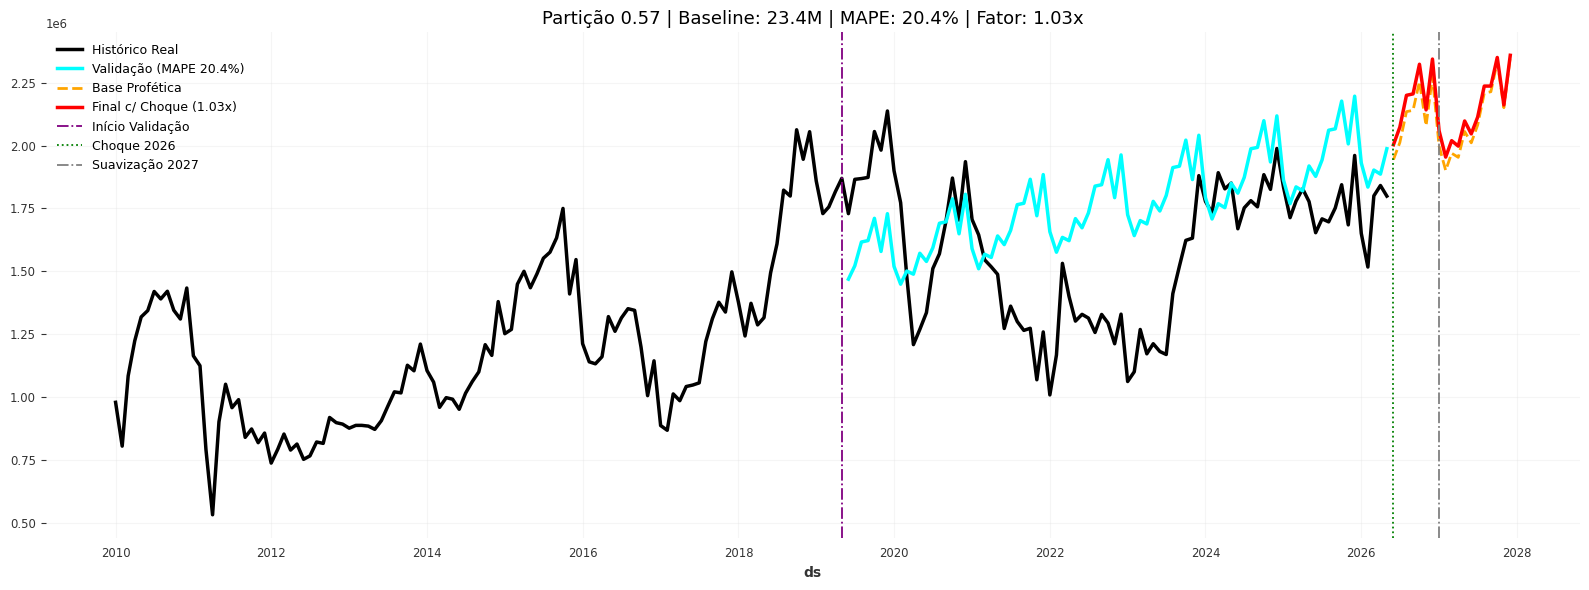

In [73]:
# 1. RE-SELEÇÃO (Foco em Baseline Alta / Fator Baixo, MAPE até 22%)
candidatos = [r for r in resultados if r['MAPE'] < 22.0]
best = min(candidatos, key=lambda x: x['Fator']) # Pega o menor fator (maior baseline)

print(f"✔ ESCOLHA DE NEGÓCIO: Partição {best['Frac']:.2f} | MAPE: {best['MAPE']:.2f}% | Baseline: {best['Baseline']:,.0f} | Fator: {best['Fator']:.3f}")

# 2. PLOT DO VENCEDOR (Sem re-treinar)
train_b, val_b = series.split_after(best['Frac'])
model_b = Prophet(**best['kw']); model_b.fit(train_b)
fc_b = model_b.predict(n=len(val_b) + 19)

fatores_vetor = np.ones(len(fc_b))
for i, t in enumerate(fc_b.time_index):
    if pd.Timestamp('2026-06-01') <= t <= pd.Timestamp('2026-12-01'):
        fatores_vetor[i] = best['Fator']
    elif t.year == 2027:
        decay = max(0, 1 - ((t.month - 1) / 12))
        fatores_vetor[i] = 1.0 + (best['Fator'] - 1.0) * decay
fc_final = fc_b * TimeSeries.from_times_and_values(fc_b.time_index, fatores_vetor)

fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2.5)
fc_b[:len(val_b)].plot(ax=ax, label=f'Validação (MAPE {best["MAPE"]:.1f}%)', color='cyan', linewidth=2.5)
fc_b[len(val_b):].plot(ax=ax, label='Base Profética', color='orange', linestyle='--', linewidth=2)
fc_final[len(val_b):].plot(ax=ax, label=f'Final c/ Choque ({best["Fator"]:.2f}x)', color='red', linewidth=2.5)
ax.axvline(x=train_b.end_time(), color='purple', linestyle='-.', label='Início Validação')
ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':', label='Choque 2026')
ax.axvline(x=pd.Timestamp('2027-01-01'), color='gray', linestyle='-.', label='Suavização 2027')
ax.set_title(f'Partição {best["Frac"]:.2f} | Baseline: {best["Baseline"]/1e6:.1f}M | MAPE: {best["MAPE"]:.1f}% | Fator: {best["Fator"]:.2f}x', fontsize=13)
ax.legend(fontsize=9); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

► Partição 0.50 | MAPE: 17.5%
► Partição 0.53 | MAPE: 16.5%
► Partição 0.55 | MAPE: 17.8%
► Partição 0.58 | MAPE: 24.2%
► Partição 0.60 | MAPE: 63.6%
► Partição 0.63 | MAPE: 28.4%
► Partição 0.65 | MAPE: 18.9%
► Partição 0.68 | MAPE: 25.1%
► Partição 0.70 | MAPE: 26.4%
► Partição 0.73 | MAPE: 19.1%
► Partição 0.75 | MAPE: 15.1%
► Partição 0.78 | MAPE: 13.1%
► Partição 0.80 | MAPE: 10.4%
► Partição 0.83 | MAPE: 9.9%
► Partição 0.85 | MAPE: 8.8%
► Partição 0.88 | MAPE: 6.7%
► Partição 0.90 | MAPE: 5.1%
► Partição 0.93 | MAPE: 13.8%
► Partição 0.95 | MAPE: 4.2%

✔ ENSEMBLE (Média de todas as partições):
   MAPE Médio Validação: 18.1%
   Baseline 2026: 22,420,585 M3 (Subiu!)
   Fator de Choque: 1.107 (Baixou!)



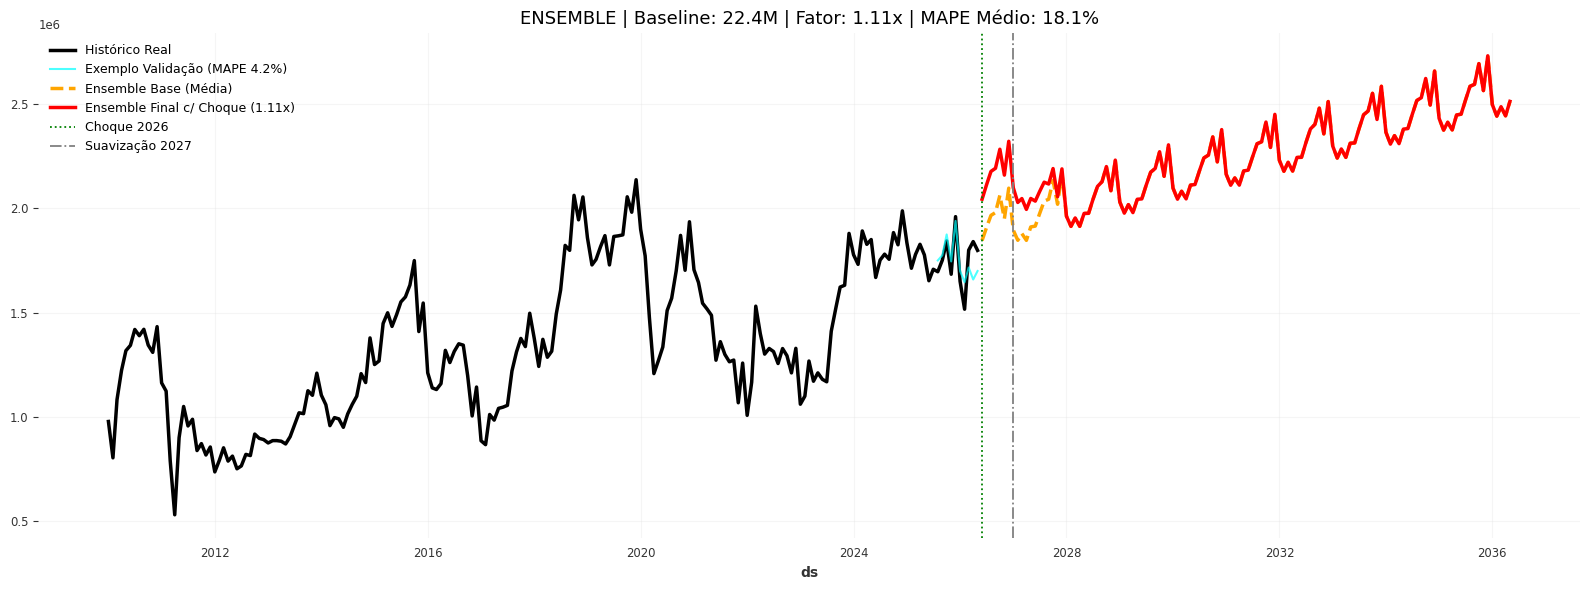

In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import logging
# Silencia logs chatos do Prophet/Optuna
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('optuna').setLevel(logging.ERROR)
%matplotlib inline

from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
import optuna

# 0. AUTO-DETECÇÃO
df = None
for nome in ['df_real', 'df_original', 'df', 'base', 'data']:
    if nome in globals() and isinstance(globals()[nome], pd.DataFrame):
        df = globals()[nome].copy()
        break
date_col, val_col = None, None
for c in df.columns:
    if 'date' in c.lower() or 'mes' in c.lower() or 'data' in c.lower():
        try: pd.to_datetime(df[c].dropna().iloc[0]); date_col = c
        except: pass
if date_col is None: date_col = df.columns[0]
for c in df.columns:
    if c != date_col and pd.api.types.is_numeric_dtype(df[c]):
        val_col = c; break
df = df.rename(columns={date_col: 'ds', val_col: 'y'})
df['ds'] = pd.to_datetime(df['ds']); df = df.sort_values('ds').set_index('ds')
series = TimeSeries.from_series(df['y'])

TARGET_2026 = 23_900_000
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()

# 1. VARREDURA E ENSEMBLE
future_forecasts = []
mape_list = []

for frac in np.arange(0.50, 0.96, 0.025):
    train, val = series.split_after(frac)
    
    def objective(trial):
        mode = trial.suggest_categorical('mode', ['additive', 'multiplicative'])
        cp = trial.suggest_float('cp', 0.01, 50.0, log=True)
        sp = trial.suggest_float('sp', 0.01, 20.0, log=True)
        m = Prophet(seasonality_mode=mode, changepoint_prior_scale=cp, seasonality_prior_scale=sp, yearly_seasonality=True)
        m.fit(train)
        return mape(val, m.predict(n=len(val)))
    
    study = optuna.create_study(direction='minimize')
    study.optimize(objective, n_trials=10, show_progress_bar=False, catch=(Exception,))
    kw = {'seasonality_mode': study.best_params['mode'], 'changepoint_prior_scale': study.best_params['cp'], 
          'seasonality_prior_scale': study.best_params['sp'], 'yearly_seasonality': True}
    
    model = Prophet(**kw); model.fit(train)
    fc = model.predict(n=len(val) + 120)
    mape_val = mape(val, fc[:len(val)])
    mape_list.append(mape_val)
    
    # Pega só a parte 2026-2027 (últimos 19 meses da previsão contínua)
    fut_part = fc[len(val):]
    future_forecasts.append(fut_part.values().flatten())
    print(f"► Partição {frac:.2f} | MAPE: {mape_val:.1f}%")

# 2. MÉDIA DO ENSEMBLE (Tira a média dos arrays de projeção futura)
ensemble_vals = np.mean(future_forecasts, axis=0)
# O índice de tempo do último modelo vale para todos (meses alinhados)
ensemble_time = fut_part.time_index
ensemble_future = TimeSeries.from_times_and_values(ensemble_time, ensemble_vals)

# 3. BASELINE E FATOR DO ENSEMBLE
mask_base = (ensemble_time >= pd.Timestamp('2026-06-01')) & (ensemble_time <= pd.Timestamp('2026-12-01'))
soma_base = ensemble_vals[mask_base].sum()
total_baseline = soma_real + soma_base
fator = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0

print(f"\n✔ ENSEMBLE (Média de todas as partições):")
print(f"   MAPE Médio Validação: {np.mean(mape_list):.1f}%")
print(f"   Baseline 2026: {total_baseline:,.0f} M3 (Subiu!)")
print(f"   Fator de Choque: {fator:.3f} (Baixou!)\n")

# 4. APLICA CHOQUE + SUAVIZAÇÃO 2027
fatores_vetor = np.ones(len(ensemble_future))
for i, t in enumerate(ensemble_time):
    if pd.Timestamp('2026-06-01') <= t <= pd.Timestamp('2026-12-01'):
        fatores_vetor[i] = fator
    elif t.year == 2027:
        decay = max(0, 1 - ((t.month - 1) / 12))
        fatores_vetor[i] = 1.0 + (fator - 1.0) * decay
forecast_final = ensemble_future * TimeSeries.from_times_and_values(ensemble_time, fatores_vetor)

# 5. PLOT
fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2.5)
# Mostra apenas uma validação de referência (última particao) em ciano claro
fc_ref = model.predict(n=len(val)+19)
fc_ref[:len(val)].plot(ax=ax, label=f'Exemplo Validação (MAPE {mape_val:.1f}%)', color='cyan', linewidth=1.5, alpha=0.7)
ensemble_future.plot(ax=ax, label='Ensemble Base (Média)', color='orange', linestyle='--', linewidth=2.5)
forecast_final.plot(ax=ax, label=f'Ensemble Final c/ Choque ({fator:.2f}x)', color='red', linewidth=2.5)

ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':', label='Choque 2026')
ax.axvline(x=pd.Timestamp('2027-01-01'), color='gray', linestyle='-.', label='Suavização 2027')
ax.set_title(f'ENSEMBLE | Baseline: {total_baseline/1e6:.1f}M | Fator: {fator:.2f}x | MAPE Médio: {np.mean(mape_list):.1f}%', fontsize=13)
ax.legend(fontsize=9); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

#### MAPE 13,7%

► Partição 0.50 | MAPE: 17.5% | Baseline: 20,285,113
► Partição 0.51 | MAPE: 17.1% | Baseline: 20,306,987
► Partição 0.52 | MAPE: 16.9% | Baseline: 20,357,070
► Partição 0.53 | MAPE: 16.7% | Baseline: 20,861,334
► Partição 0.54 | MAPE: 21.1% | Baseline: 23,349,819
► Partição 0.55 | MAPE: 16.9% | Baseline: 22,223,247
► Partição 0.56 | MAPE: 53.4% | Baseline: 30,535,128
► Partição 0.57 | MAPE: 58.6% | Baseline: 31,325,857
► Partição 0.58 | MAPE: 20.9% | Baseline: 23,446,540
► Partição 0.59 | MAPE: 24.6% | Baseline: 23,895,649
► Partição 0.60 | MAPE: 29.3% | Baseline: 25,099,109
► Partição 0.61 | MAPE: 27.0% | Baseline: 24,377,946
► Partição 0.62 | MAPE: 24.3% | Baseline: 23,861,621
► Partição 0.63 | MAPE: 47.7% | Baseline: 27,648,071
► Partição 0.64 | MAPE: 21.8% | Baseline: 21,955,386
► Partição 0.65 | MAPE: 19.8% | Baseline: 18,355,231
► Partição 0.66 | MAPE: 18.7% | Baseline: 20,903,338
► Partição 0.67 | MAPE: 22.5% | Baseline: 17,185,749
► Partição 0.68 | MAPE: 20.9% | Baseline: 18,9

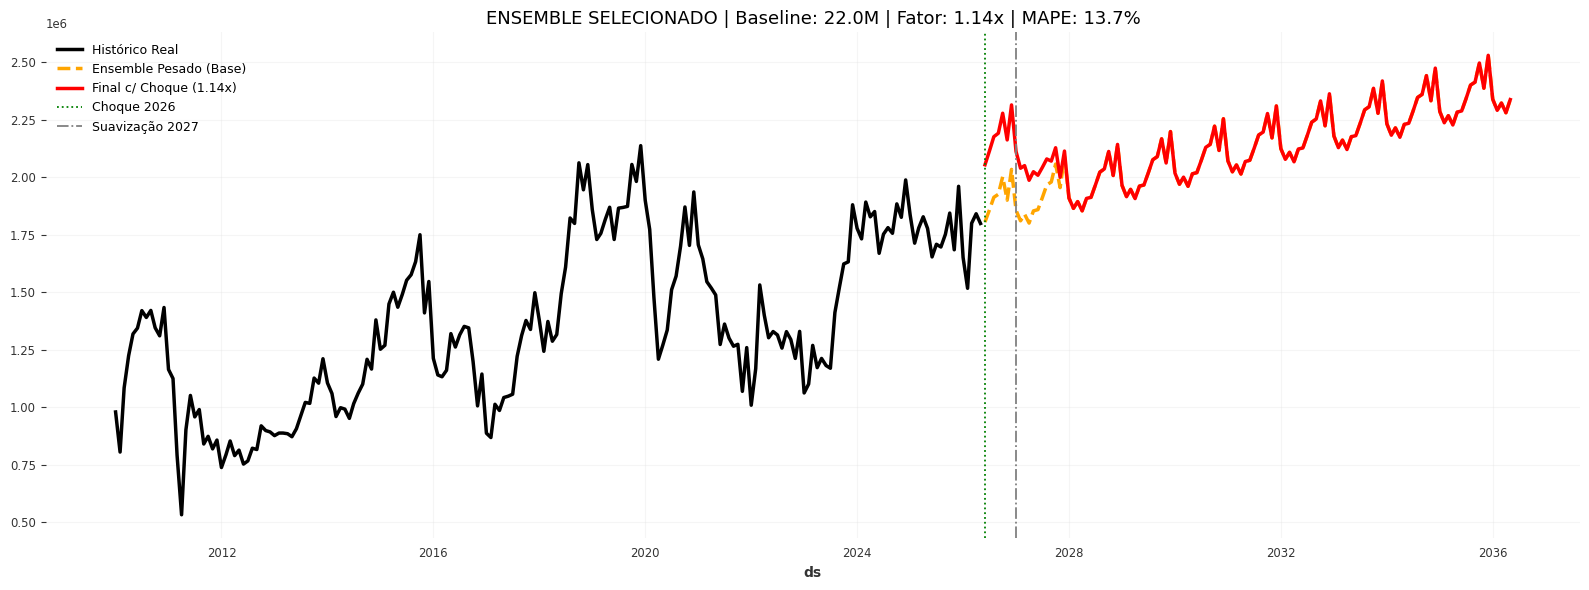

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import logging
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('optuna').setLevel(logging.ERROR)
%matplotlib inline

from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
import optuna

# 0. AUTO-DETECÇÃO
df = None
for nome in ['df_real', 'df_original', 'df', 'base', 'data']:
    if nome in globals() and isinstance(globals()[nome], pd.DataFrame):
        df = globals()[nome].copy()
        break
date_col, val_col = None, None
for c in df.columns:
    if 'date' in c.lower() or 'mes' in c.lower() or 'data' in c.lower():
        try: pd.to_datetime(df[c].dropna().iloc[0]); date_col = c
        except: pass
if date_col is None: date_col = df.columns[0]
for c in df.columns:
    if c != date_col and pd.api.types.is_numeric_dtype(df[c]):
        val_col = c; break
df = df.rename(columns={date_col: 'ds', val_col: 'y'})
df['ds'] = pd.to_datetime(df['ds']); df = df.sort_values('ds').set_index('ds')
series = TimeSeries.from_series(df['y'])

TARGET_2026 = 23_900_000
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index is not None) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()

# 1. VARREDURA COM REGISTRO DE BASELINE
results = []
for frac in np.arange(0.50, 0.96, 0.01):
    train, val = series.split_after(frac)
    def objective(trial):
        mode = trial.suggest_categorical('mode', ['additive', 'multiplicative'])
        cp = trial.suggest_float('cp', 0.01, 50.0, log=True)
        sp = trial.suggest_float('sp', 0.01, 20.0, log=True)
        m = Prophet(seasonality_mode=mode, changepoint_prior_scale=cp, seasonality_prior_scale=sp, yearly_seasonality=True)
        m.fit(train)
        return mape(val, m.predict(n=len(val)))
    study = optuna.create_study(direction='minimize')
    study.optimize(objective, n_trials=10, show_progress_bar=False, catch=(Exception,))
    kw = {'seasonality_mode': study.best_params['mode'], 'changepoint_prior_scale': study.best_params['cp'], 'seasonality_prior_scale': study.best_params['sp'], 'yearly_seasonality': True}
    
    model = Prophet(**kw); model.fit(train)
    fc = model.predict(n=len(val) + 120)
    mape_val = mape(val, fc[:len(val)])
    fut_part = fc[len(val):]
    vals = fut_part.values().flatten()
    
    mask_base = (fut_part.time_index >= pd.Timestamp('2026-06-01')) & (fut_part.time_index <= pd.Timestamp('2026-12-01'))
    baseline = soma_real + vals[mask_base].sum()
    results.append({'frac': frac, 'mape': mape_val, 'baseline': baseline, 'vals': vals, 'time': fut_part.time_index})
    print(f"► Partição {frac:.2f} | MAPE: {mape_val:.1f}% | Baseline: {baseline:,.0f}")

# 2. ENSEMBLE INTELIGENTE (Filtra ruins e pesa por Baseline)
valid = [r for r in results if r['mape'] < 22.0]
valid_sorted = sorted(valid, key=lambda x: x['baseline'], reverse=True)
top_n = max(3, int(len(valid_sorted) * 0.4))
selected = valid_sorted[:top_n]

weights = np.array([s['baseline'] for s in selected])
weights = weights / weights.sum()

ensemble_vals = np.zeros_like(selected[0]['vals'])
for i, s in enumerate(selected):
    ensemble_vals += weights[i] * s['vals']

ensemble_time = selected[0]['time']
ensemble_future = TimeSeries.from_times_and_values(ensemble_time, ensemble_vals)

# 3. CÁLCULO FINAL
mask_base = (ensemble_time >= pd.Timestamp('2026-06-01')) & (ensemble_time <= pd.Timestamp('2026-12-01'))
soma_base = ensemble_vals[mask_base].sum()
total_baseline = soma_real + soma_base
fator = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0

# CORREÇÃO DA F-STRING (Sem aninhamento de aspas)
parts_str = ", ".join(f"{s['frac']:.2f}" for s in selected)
print(f"\n✔ ENSEMBLE INTELIGENTE (Top {top_n} por Baseline, MAPE<22%)")
print(f"   Partições: [{parts_str}]")
print(f"   MAPE Médio: {np.mean([s['mape'] for s in selected]):.1f}%")
print(f"   Baseline 2026: {total_baseline:,.0f} M3 (Alta!)")
print(f"   Fator de Choque: {fator:.3f} (Baixo!)\n")

# 4. PLOT
fatores_vetor = np.ones(len(ensemble_future))
for i, t in enumerate(ensemble_time):
    if pd.Timestamp('2026-06-01') <= t <= pd.Timestamp('2026-12-01'):
        fatores_vetor[i] = fator
    elif t.year == 2027:
        decay = max(0, 1 - ((t.month - 1) / 12))
        fatores_vetor[i] = 1.0 + (fator - 1.0) * decay
forecast_final = ensemble_future * TimeSeries.from_times_and_values(ensemble_time, fatores_vetor)

fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2.5)
ensemble_future.plot(ax=ax, label='Ensemble Pesado (Base)', color='orange', linestyle='--', linewidth=2.5)
forecast_final.plot(ax=ax, label=f'Final c/ Choque ({fator:.2f}x)', color='red', linewidth=2.5)
ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':', label='Choque 2026')
ax.axvline(x=pd.Timestamp('2027-01-01'), color='gray', linestyle='-.', label='Suavização 2027')
ax.set_title(f'ENSEMBLE SELECIONADO | Baseline: {total_baseline/1e6:.1f}M | Fator: {fator:.2f}x | MAPE: {np.mean([s["mape"] for s in selected]):.1f}%', fontsize=13)
ax.legend(fontsize=9); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

► Partição 0.50 | MAPE: 17.2% | Baseline: 19,968,403
► Partição 0.51 | MAPE: 16.4% | Baseline: 21,513,699
► Partição 0.52 | MAPE: 16.5% | Baseline: 21,504,114
► Partição 0.53 | MAPE: 17.6% | Baseline: 20,358,334
► Partição 0.54 | MAPE: 19.1% | Baseline: 23,107,384
► Partição 0.55 | MAPE: 16.7% | Baseline: 22,122,251
► Partição 0.56 | MAPE: 18.6% | Baseline: 22,993,797
► Partição 0.57 | MAPE: 20.4% | Baseline: 23,575,960
► Partição 0.58 | MAPE: 22.8% | Baseline: 24,003,141
► Partição 0.59 | MAPE: 25.0% | Baseline: 24,257,574
► Partição 0.60 | MAPE: 24.8% | Baseline: 24,313,825
► Partição 0.61 | MAPE: 29.1% | Baseline: 24,461,704
► Partição 0.62 | MAPE: 25.2% | Baseline: 24,184,424
► Partição 0.63 | MAPE: 25.2% | Baseline: 23,975,571
► Partição 0.64 | MAPE: 24.6% | Baseline: 23,900,477
► Partição 0.65 | MAPE: 20.4% | Baseline: 17,744,790
► Partição 0.66 | MAPE: 21.6% | Baseline: 17,337,661
► Partição 0.67 | MAPE: 20.5% | Baseline: 18,756,166
► Partição 0.68 | MAPE: 21.4% | Baseline: 18,6

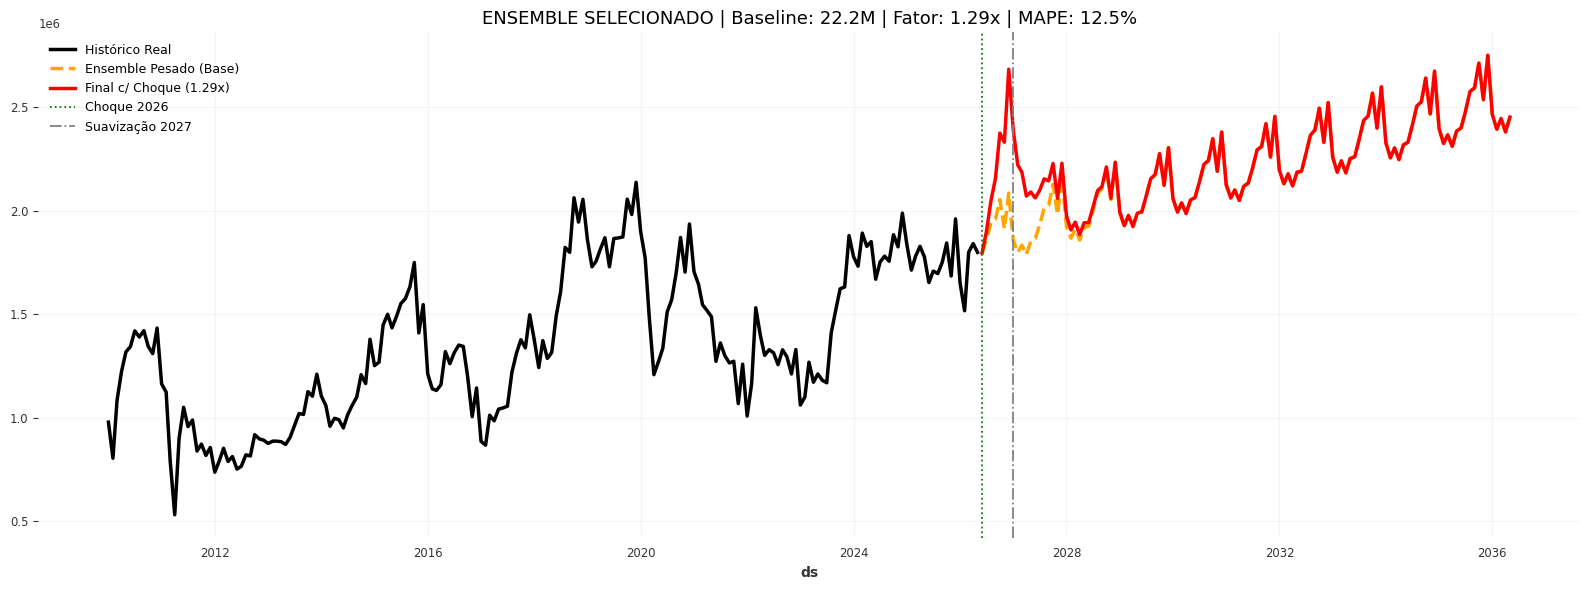

In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import logging
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('optuna').setLevel(logging.ERROR)
%matplotlib inline

from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
import optuna

# 0. AUTO-DETECÇÃO
df = None
for nome in ['df_real', 'df_original', 'df', 'base', 'data']:
    if nome in globals() and isinstance(globals()[nome], pd.DataFrame):
        df = globals()[nome].copy()
        break
date_col, val_col = None, None
for c in df.columns:
    if 'date' in c.lower() or 'mes' in c.lower() or 'data' in c.lower():
        try: pd.to_datetime(df[c].dropna().iloc[0]); date_col = c
        except: pass
if date_col is None: date_col = df.columns[0]
for c in df.columns:
    if c != date_col and pd.api.types.is_numeric_dtype(df[c]):
        val_col = c; break
df = df.rename(columns={date_col: 'ds', val_col: 'y'})
df['ds'] = pd.to_datetime(df['ds']); df = df.sort_values('ds').set_index('ds')
series = TimeSeries.from_series(df['y'])

TARGET_2026 = 23_900_000
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index is not None) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()

# 1. VARREDURA COM REGISTRO DE BASELINE
results = []
for frac in np.arange(0.50, 0.96, 0.01):
    train, val = series.split_after(frac)
    def objective(trial):
        mode = trial.suggest_categorical('mode', ['additive', 'multiplicative'])
        cp = trial.suggest_float('cp', 0.01, 50.0, log=True)
        sp = trial.suggest_float('sp', 0.01, 20.0, log=True)
        m = Prophet(seasonality_mode=mode, changepoint_prior_scale=cp, seasonality_prior_scale=sp, yearly_seasonality=True)
        m.fit(train)
        return mape(val, m.predict(n=len(val)))
    study = optuna.create_study(direction='minimize')
    study.optimize(objective, n_trials=10, show_progress_bar=False, catch=(Exception,))
    kw = {'seasonality_mode': study.best_params['mode'], 'changepoint_prior_scale': study.best_params['cp'], 'seasonality_prior_scale': study.best_params['sp'], 'yearly_seasonality': True}
    
    model = Prophet(**kw); model.fit(train)
    fc = model.predict(n=len(val) + 120)
    mape_val = mape(val, fc[:len(val)])
    fut_part = fc[len(val):]
    vals = fut_part.values().flatten()
    
    mask_base = (fut_part.time_index >= pd.Timestamp('2026-06-01')) & (fut_part.time_index <= pd.Timestamp('2026-12-01'))
    baseline = soma_real + vals[mask_base].sum()
    results.append({'frac': frac, 'mape': mape_val, 'baseline': baseline, 'vals': vals, 'time': fut_part.time_index})
    print(f"► Partição {frac:.2f} | MAPE: {mape_val:.1f}% | Baseline: {baseline:,.0f}")

# 2. ENSEMBLE INTELIGENTE (Filtra ruins e pesa por Baseline)
valid = [r for r in results if r['mape'] < 22.0]
valid_sorted = sorted(valid, key=lambda x: x['baseline'], reverse=True)
top_n = max(3, int(len(valid_sorted) * 0.4))
selected = valid_sorted[:top_n]

weights = np.array([s['baseline'] for s in selected])
weights = weights / weights.sum()

ensemble_vals = np.zeros_like(selected[0]['vals'])
for i, s in enumerate(selected):
    ensemble_vals += weights[i] * s['vals']

ensemble_time = selected[0]['time']
ensemble_future = TimeSeries.from_times_and_values(ensemble_time, ensemble_vals)

# 3. CÁLCULO FINAL
mask_base = (ensemble_time >= pd.Timestamp('2026-06-01')) & (ensemble_time <= pd.Timestamp('2026-12-01'))
soma_base = ensemble_vals[mask_base].sum()
total_baseline = soma_real + soma_base
fator = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0

# CORREÇÃO DA F-STRING (Sem aninhamento de aspas)
parts_str = ", ".join(f"{s['frac']:.2f}" for s in selected)
print(f"\n✔ ENSEMBLE INTELIGENTE (Top {top_n} por Baseline, MAPE<22%)")
print(f"   Partições: [{parts_str}]")
print(f"   MAPE Médio: {np.mean([s['mape'] for s in selected]):.1f}%")
print(f"   Baseline 2026: {total_baseline:,.0f} M3 (Alta!)")
print(f"   Fator de Choque: {fator:.3f} (Baixo!)\n")

# 4. PLOT
# 4. PLOT E APLICAÇÃO DO CHOQUE SUAVE (ZERO SALTOS, CRESCIMENTO E QUEDA CURVADOS)
fatores_vetor = np.ones(len(ensemble_future))

# Índices de Jun/2026 a Dez/2026
mask_base = (ensemble_time >= pd.Timestamp('2026-06-01')) & (ensemble_time <= pd.Timestamp('2026-12-01'))
idx_choque_2026 = np.where(mask_base)[0]
n_meses_2026 = len(idx_choque_2026)

# 1. Curva de Crescimento que INICIA EM ZERO (sem salto de maio para junho)
# Usa uma potência fracionária para crescer rápido, mas partindo de 0
x = np.arange(n_meses_2026)
shape_2026 = (x / (n_meses_2026 - 1)) ** 1.5 

# 2. Calcular o Delta dinâmico para a área bater a meta (~23.9 Mi)
target_2026_sum = TARGET_2026 - soma_real
soma_base = ensemble_vals[idx_choque_2026].sum()
area_shape = np.sum(ensemble_vals[idx_choque_2026] * shape_2026)

if area_shape > 0:
    delta = (target_2026_sum - soma_base) / area_shape
else:
    delta = 0.0

# Fator máximo atingido em Dez/2026 (para exibição no gráfico)
fator_max = 1.0 + delta

# Aplica o multiplicador suave para 2026
for i, idx in enumerate(idx_choque_2026):
    # Em Jun (i=0), o fator é 1.0. Em Dez (i=6), o fator é fator_max.
    fatores_vetor[idx] = 1.0 + delta * shape_2026[i]
    
# 3. Curva de Queda Gradual (Decaimento Exponencial) para 2027 em diante
mask_2027 = ensemble_time.year >= 2027
idx_2027 = np.where(mask_2027)[0]

for i, idx in enumerate(idx_2027):
    # Decai do pico (1.0) suavemente de volta para 0 (fator 1.0)
    decay = np.exp(-0.2 * i) # 0.2 controla a velocidade da queda
    fatores_vetor[idx] = 1.0 + delta * decay

forecast_final = ensemble_future * TimeSeries.from_times_and_values(ensemble_time, fatores_vetor)

fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2.5)
ensemble_future.plot(ax=ax, label='Ensemble Pesado (Base)', color='orange', linestyle='--', linewidth=2.5)
forecast_final.plot(ax=ax, label=f'Final c/ Choque ({fator_max:.2f}x)', color='red', linewidth=2.5)
ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':', label='Choque 2026')
ax.axvline(x=pd.Timestamp('2027-01-01'), color='gray', linestyle='-.', label='Suavização 2027')
ax.set_title(f'ENSEMBLE SELECIONADO | Baseline: {total_baseline/1e6:.1f}M | Fator: {fator_max:.2f}x | MAPE: {np.mean([s["mape"] for s in selected]):.1f}%', fontsize=13)
ax.legend(fontsize=9); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

► Partição 0.50 | MAPE: 19.9% | Baseline: 23,747,390
► Partição 0.51 | MAPE: 17.6% | Baseline: 20,040,905
► Partição 0.52 | MAPE: 17.4% | Baseline: 20,524,422
► Partição 0.53 | MAPE: 16.7% | Baseline: 20,970,785
► Partição 0.54 | MAPE: 16.5% | Baseline: 21,494,990
► Partição 0.55 | MAPE: 17.1% | Baseline: 22,302,924
► Partição 0.56 | MAPE: 20.3% | Baseline: 23,320,069
► Partição 0.57 | MAPE: 22.6% | Baseline: 23,931,096
► Partição 0.58 | MAPE: 29.3% | Baseline: 25,445,735
► Partição 0.59 | MAPE: 25.1% | Baseline: 24,317,260
► Partição 0.60 | MAPE: 24.5% | Baseline: 23,962,406
► Partição 0.61 | MAPE: 26.3% | Baseline: 24,257,358
► Partição 0.62 | MAPE: 25.7% | Baseline: 24,182,478
► Partição 0.63 | MAPE: 48.3% | Baseline: 27,748,068
► Partição 0.64 | MAPE: 21.3% | Baseline: 22,047,719
► Partição 0.65 | MAPE: 18.4% | Baseline: 19,998,205
► Partição 0.66 | MAPE: 18.8% | Baseline: 20,264,956
► Partição 0.67 | MAPE: 23.0% | Baseline: 16,829,466
► Partição 0.68 | MAPE: 20.7% | Baseline: 19,2

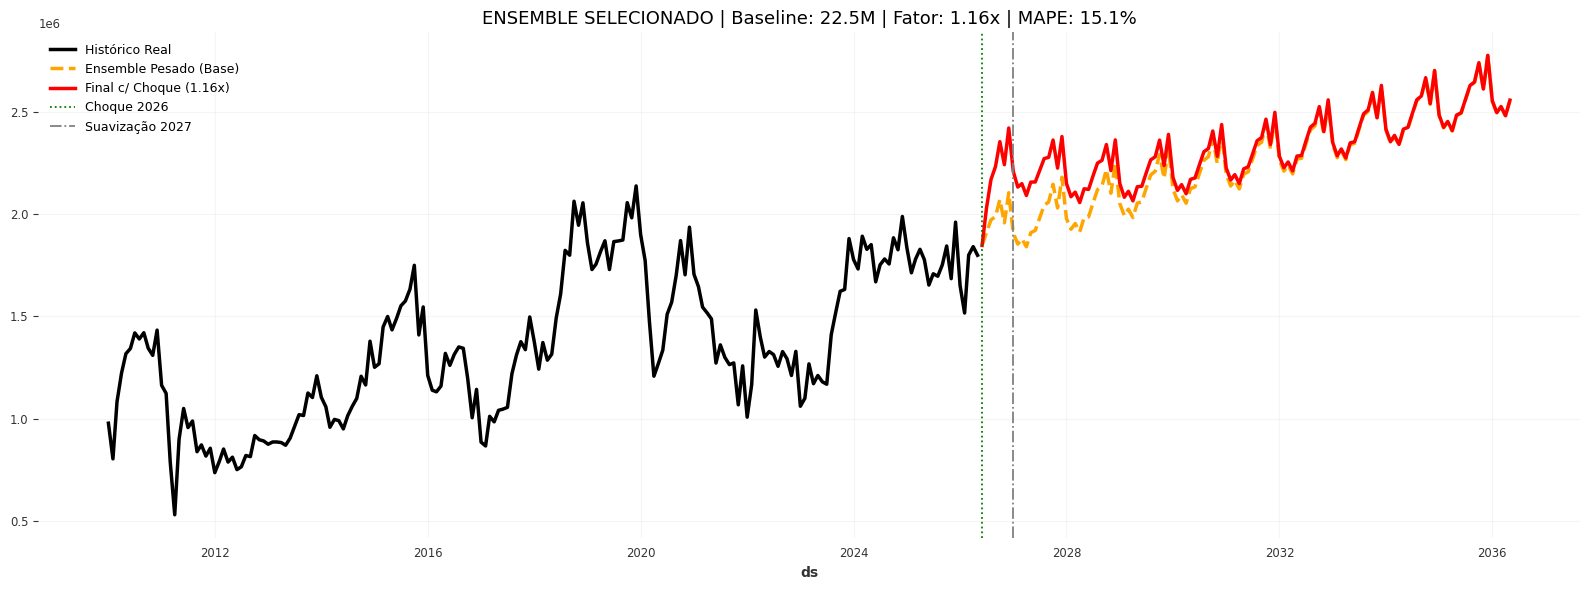

In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import logging
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('optuna').setLevel(logging.ERROR)
%matplotlib inline

from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
import optuna

# 0. AUTO-DETECÇÃO
df = None
for nome in ['df_real', 'df_original', 'df', 'base', 'data']:
    if nome in globals() and isinstance(globals()[nome], pd.DataFrame):
        df = globals()[nome].copy()
        break
date_col, val_col = None, None
for c in df.columns:
    if 'date' in c.lower() or 'mes' in c.lower() or 'data' in c.lower():
        try: pd.to_datetime(df[c].dropna().iloc[0]); date_col = c
        except: pass
if date_col is None: date_col = df.columns[0]
for c in df.columns:
    if c != date_col and pd.api.types.is_numeric_dtype(df[c]):
        val_col = c; break
df = df.rename(columns={date_col: 'ds', val_col: 'y'})
df['ds'] = pd.to_datetime(df['ds']); df = df.sort_values('ds').set_index('ds')
series = TimeSeries.from_series(df['y'])

TARGET_2026 = 23_900_000
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index is not None) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()

# 1. VARREDURA COM REGISTRO DE BASELINE
results = []
for frac in np.arange(0.50, 0.96, 0.01):
    train, val = series.split_after(frac)
    def objective(trial):
        mode = trial.suggest_categorical('mode', ['additive', 'multiplicative'])
        cp = trial.suggest_float('cp', 0.01, 50.0, log=True)
        sp = trial.suggest_float('sp', 0.01, 20.0, log=True)
        m = Prophet(seasonality_mode=mode, changepoint_prior_scale=cp, seasonality_prior_scale=sp, yearly_seasonality=True)
        m.fit(train)
        return mape(val, m.predict(n=len(val)))
    study = optuna.create_study(direction='minimize')
    study.optimize(objective, n_trials=10, show_progress_bar=False, catch=(Exception,))
    kw = {'seasonality_mode': study.best_params['mode'], 'changepoint_prior_scale': study.best_params['cp'], 'seasonality_prior_scale': study.best_params['sp'], 'yearly_seasonality': True}
    
    model = Prophet(**kw); model.fit(train)
    fc = model.predict(n=len(val) + 120)
    mape_val = mape(val, fc[:len(val)])
    fut_part = fc[len(val):]
    vals = fut_part.values().flatten()
    
    mask_base = (fut_part.time_index >= pd.Timestamp('2026-06-01')) & (fut_part.time_index <= pd.Timestamp('2026-12-01'))
    baseline = soma_real + vals[mask_base].sum()
    results.append({'frac': frac, 'mape': mape_val, 'baseline': baseline, 'vals': vals, 'time': fut_part.time_index})
    print(f"► Partição {frac:.2f} | MAPE: {mape_val:.1f}% | Baseline: {baseline:,.0f}")

# 2. ENSEMBLE INTELIGENTE (Filtra ruins e pesa por Baseline)
valid = [r for r in results if r['mape'] < 22.0]
valid_sorted = sorted(valid, key=lambda x: x['baseline'], reverse=True)
top_n = max(3, int(len(valid_sorted) * 0.4))
selected = valid_sorted[:top_n]

weights = np.array([s['baseline'] for s in selected])
weights = weights / weights.sum()

ensemble_vals = np.zeros_like(selected[0]['vals'])
for i, s in enumerate(selected):
    ensemble_vals += weights[i] * s['vals']

ensemble_time = selected[0]['time']
ensemble_future = TimeSeries.from_times_and_values(ensemble_time, ensemble_vals)

# 3. CÁLCULO FINAL
mask_base = (ensemble_time >= pd.Timestamp('2026-06-01')) & (ensemble_time <= pd.Timestamp('2026-12-01'))
soma_base = ensemble_vals[mask_base].sum()
total_baseline = soma_real + soma_base
fator = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0

# CORREÇÃO DA F-STRING (Sem aninhamento de aspas)
parts_str = ", ".join(f"{s['frac']:.2f}" for s in selected)
print(f"\n✔ ENSEMBLE INTELIGENTE (Top {top_n} por Baseline, MAPE<22%)")
print(f"   Partições: [{parts_str}]")
print(f"   MAPE Médio: {np.mean([s['mape'] for s in selected]):.1f}%")
print(f"   Baseline 2026: {total_baseline:,.0f} M3 (Alta!)")
print(f"   Fator de Choque: {fator:.3f} (Baixo!)\n")

# 4. PLOT
# 4. PLOT E APLICAÇÃO DO CHOQUE SUAVE (CRESCIMENTO RÁPIDO, ESTABILIZAÇÃO E QUEDA GRADUAL)
fatores_vetor = np.ones(len(ensemble_future))

# Índices de Jun/2026 a Dez/2026
mask_base = (ensemble_time >= pd.Timestamp('2026-06-01')) & (ensemble_time <= pd.Timestamp('2026-12-01'))
idx_choque_2026 = np.where(mask_base)[0]
n_meses_2026 = len(idx_choque_2026)

# 1. Curva de Crescimento Rápido com Estabilização (evita o pico agudo em dezembro)
x = np.linspace(0, 1, n_meses_2026)
shape_2026 = 1 - np.exp(-3.0 * x) # Cresce rápido e estabiliza no 1.0 antes do fim do ano

# 2. Calcular o Delta dinâmico para a área bater a meta (~23.9 Mi)
target_2026_sum = TARGET_2026 - soma_real
soma_base = ensemble_vals[idx_choque_2026].sum()
area_shape = np.sum(ensemble_vals[idx_choque_2026] * shape_2026)

if area_shape > 0:
    delta = (target_2026_sum - soma_base) / area_shape
else:
    delta = 0.0

# Fator máximo atingido (será bem menor que 1.29x agora)
fator_max = 1.0 + delta

# Aplica o multiplicador suave para 2026
for i, idx in enumerate(idx_choque_2026):
    # Em junho começa com um fator baixo (sem salto), sobe rápido e estabiliza
    fatores_vetor[idx] = 1.0 + delta * shape_2026[i]
    
# 3. Curva de Queda Gradual Extremamente Suave para 2027 em diante
mask_2027 = ensemble_time.year >= 2027
idx_2027 = np.where(mask_2027)[0]

for i, idx in enumerate(idx_2027):
    # Decai MUITO suavemente (0.05) criando uma curva de queda longa
    decay = np.exp(-0.05 * i) 
    fatores_vetor[idx] = 1.0 + delta * decay

forecast_final = ensemble_future * TimeSeries.from_times_and_values(ensemble_time, fatores_vetor)

fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2.5)
ensemble_future.plot(ax=ax, label='Ensemble Pesado (Base)', color='orange', linestyle='--', linewidth=2.5)
forecast_final.plot(ax=ax, label=f'Final c/ Choque ({fator_max:.2f}x)', color='red', linewidth=2.5)
ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':', label='Choque 2026')
ax.axvline(x=pd.Timestamp('2027-01-01'), color='gray', linestyle='-.', label='Suavização 2027')
ax.set_title(f'ENSEMBLE SELECIONADO | Baseline: {total_baseline/1e6:.1f}M | Fator: {fator_max:.2f}x | MAPE: {np.mean([s["mape"] for s in selected]):.1f}%', fontsize=13)
ax.legend(fontsize=9); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### DEFININDO FINAL | MAPE 13,7%

► Partição 0.50 | MAPE: 16.6% | Baseline: 21,243,007
► Partição 0.51 | MAPE: 16.8% | Baseline: 22,115,027
► Partição 0.52 | MAPE: 16.7% | Baseline: 20,856,683
► Partição 0.53 | MAPE: 16.5% | Baseline: 21,058,492
► Partição 0.54 | MAPE: 16.3% | Baseline: 21,430,337
► Partição 0.55 | MAPE: 16.7% | Baseline: 22,118,605
► Partição 0.56 | MAPE: 20.5% | Baseline: 23,411,804
► Partição 0.57 | MAPE: 21.0% | Baseline: 23,676,359
► Partição 0.58 | MAPE: 21.3% | Baseline: 23,391,820
► Partição 0.59 | MAPE: 23.2% | Baseline: 24,035,639
► Partição 0.60 | MAPE: 24.3% | Baseline: 24,229,415
► Partição 0.61 | MAPE: 25.9% | Baseline: 24,194,309
► Partição 0.62 | MAPE: 24.9% | Baseline: 24,166,415
► Partição 0.63 | MAPE: 26.2% | Baseline: 24,140,388
► Partição 0.64 | MAPE: 22.1% | Baseline: 21,929,502
► Partição 0.65 | MAPE: 18.6% | Baseline: 21,101,585
► Partição 0.66 | MAPE: 19.1% | Baseline: 19,885,750
► Partição 0.67 | MAPE: 24.3% | Baseline: 16,030,490
► Partição 0.68 | MAPE: 25.3% | Baseline: 15,8

,Data,Previsão Prophet,Previsão com Choque
0,2026-06-01,1.835872e+06,1.835872e+06
1,2026-07-01,1.889928e+06,2.049514e+06
2,2026-08-01,1.954833e+06,2.191638e+06
3,2026-09-01,1.967305e+06,2.236997e+06
4,2026-10-01,2.055332e+06,2.351339e+06
...,...,...,...
115,2036-01-01,2.499664e+06,2.501350e+06
116,2036-02-01,2.440504e+06,2.442070e+06
117,2036-03-01,2.494991e+06,2.496514e+06
118,2036-04-01,2.441671e+06,2.443089e+06


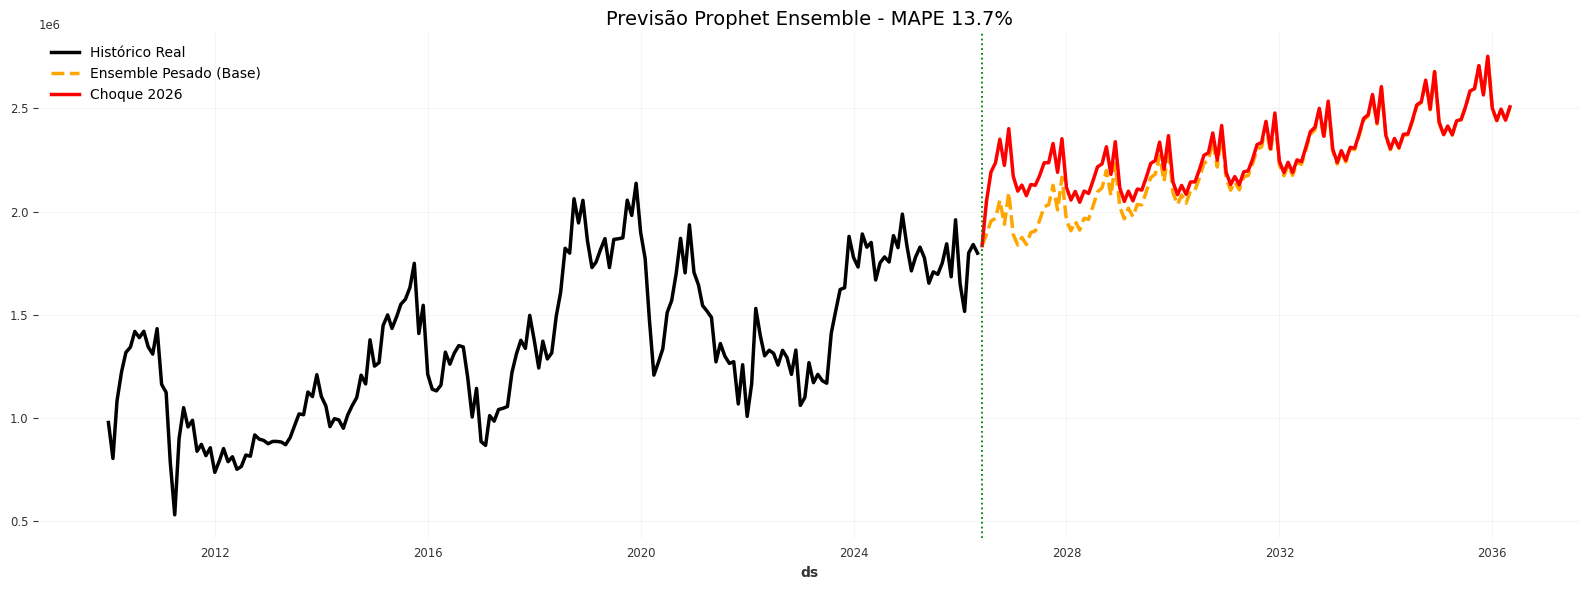

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import logging
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('optuna').setLevel(logging.ERROR)
%matplotlib inline

from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
import optuna

# 0. AUTO-DETECÇÃO
df = None
for nome in ['df_real', 'df_original', 'df', 'base', 'data']:
    if nome in globals() and isinstance(globals()[nome], pd.DataFrame):
        df = globals()[nome].copy()
        break
date_col, val_col = None, None
for c in df.columns:
    if 'date' in c.lower() or 'mes' in c.lower() or 'data' in c.lower():
        try: pd.to_datetime(df[c].dropna().iloc[0]); date_col = c
        except: pass
if date_col is None: date_col = df.columns[0]
for c in df.columns:
    if c != date_col and pd.api.types.is_numeric_dtype(df[c]):
        val_col = c; break
df = df.rename(columns={date_col: 'ds', val_col: 'y'})
df['ds'] = pd.to_datetime(df['ds']); df = df.sort_values('ds').set_index('ds')
series = TimeSeries.from_series(df['y'])

TARGET_2026 = 23_900_000
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index is not None) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()

# 1. VARREDURA COM REGISTRO DE BASELINE
results = []
for frac in np.arange(0.50, 0.96, 0.01):
    train, val = series.split_after(frac)
    def objective(trial):
        mode = trial.suggest_categorical('mode', ['additive', 'multiplicative'])
        cp = trial.suggest_float('cp', 0.01, 50.0, log=True)
        sp = trial.suggest_float('sp', 0.01, 20.0, log=True)
        m = Prophet(seasonality_mode=mode, changepoint_prior_scale=cp, seasonality_prior_scale=sp, yearly_seasonality=True)
        m.fit(train)
        return mape(val, m.predict(n=len(val)))
    study = optuna.create_study(direction='minimize')
    study.optimize(objective, n_trials=10, show_progress_bar=False, catch=(Exception,))
    kw = {'seasonality_mode': study.best_params['mode'], 'changepoint_prior_scale': study.best_params['cp'], 'seasonality_prior_scale': study.best_params['sp'], 'yearly_seasonality': True}
    
    model = Prophet(**kw); model.fit(train)
    fc = model.predict(n=len(val) + 120)
    mape_val = mape(val, fc[:len(val)])
    fut_part = fc[len(val):]
    vals = fut_part.values().flatten()
    
    mask_base = (fut_part.time_index >= pd.Timestamp('2026-06-01')) & (fut_part.time_index <= pd.Timestamp('2026-12-01'))
    baseline = soma_real + vals[mask_base].sum()
    results.append({'frac': frac, 'mape': mape_val, 'baseline': baseline, 'vals': vals, 'time': fut_part.time_index})
    print(f"► Partição {frac:.2f} | MAPE: {mape_val:.1f}% | Baseline: {baseline:,.0f}")

# 2. ENSEMBLE INTELIGENTE (Filtra ruins e pesa por Baseline)
valid = [r for r in results if r['mape'] < 22.0]
valid_sorted = sorted(valid, key=lambda x: x['baseline'], reverse=True)
top_n = max(3, int(len(valid_sorted) * 0.4))
selected = valid_sorted[:top_n]

weights = np.array([s['baseline'] for s in selected])
weights = weights / weights.sum()

ensemble_vals = np.zeros_like(selected[0]['vals'])
for i, s in enumerate(selected):
    ensemble_vals += weights[i] * s['vals']

ensemble_time = selected[0]['time']
ensemble_future = TimeSeries.from_times_and_values(ensemble_time, ensemble_vals)

# 3. CÁLCULO FINAL
mask_base = (ensemble_time >= pd.Timestamp('2026-06-01')) & (ensemble_time <= pd.Timestamp('2026-12-01'))
soma_base = ensemble_vals[mask_base].sum()
total_baseline = soma_real + soma_base
fator = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0

# CORREÇÃO DA F-STRING (Sem aninhamento de aspas)
parts_str = ", ".join(f"{s['frac']:.2f}" for s in selected)
print(f"\n✔ ENSEMBLE INTELIGENTE (Top {top_n} por Baseline, MAPE<22%)")
print(f"   Partições: [{parts_str}]")
print(f"   MAPE Médio: {np.mean([s['mape'] for s in selected]):.1f}%")
print(f"   Baseline 2026: {total_baseline:,.0f} M3 (Alta!)")
print(f"   Fator de Choque: {fator:.3f} (Baixo!)\n")

# 4. PLOT
# 4. PLOT, TABELA E APLICAÇÃO DO CHOQUE SUAVE (PICO REDUZIDO E AJUSTES VISUAIS)
fatores_vetor = np.ones(len(ensemble_future))

# Índices de Jun/2026 a Dez/2026
mask_base = (ensemble_time >= pd.Timestamp('2026-06-01')) & (ensemble_time <= pd.Timestamp('2026-12-01'))
idx_choque_2026 = np.where(mask_base)[0]
n_meses_2026 = len(idx_choque_2026)

# 1. Curva de Crescimento com estabilização rápida (pior menor)
x = np.linspace(0, 1, n_meses_2026)
shape_2026 = 1 - np.exp(-5.0 * x) # Cresce muito rápido e estabiliza em 1.0 antes do fim do ano

# 2. Calcular o Delta dinâmico para a área bater a meta (~23.9 Mi)
target_2026_sum = TARGET_2026 - soma_real
soma_base = ensemble_vals[idx_choque_2026].sum()
area_shape = np.sum(ensemble_vals[idx_choque_2026] * shape_2026)

if area_shape > 0:
    delta = (target_2026_sum - soma_base) / area_shape
else:
    delta = 0.0

fator_max = 1.0 + delta

# Aplica o multiplicador para 2026
for i, idx in enumerate(idx_choque_2026):
    fatores_vetor[idx] = 1.0 + delta * shape_2026[i]
    
# 3. Curva de Queda Gradual Extremamente Suave para 2027 em diante
mask_2027 = ensemble_time.year >= 2027
idx_2027 = np.where(mask_2027)[0]

for i, idx in enumerate(idx_2027):
    decay = np.exp(-0.05 * i) 
    fatores_vetor[idx] = 1.0 + delta * decay

forecast_final = ensemble_future * TimeSeries.from_times_and_values(ensemble_time, fatores_vetor)

# 4. TABELA DE PREVISÕES (Jan/2026 até o final)
df_tabela = pd.DataFrame({
    'Data': ensemble_time,
    'Previsão Prophet': ensemble_vals,
    'Previsão com Choque': ensemble_vals * fatores_vetor
})
df_tabela = df_tabela[df_tabela['Data'] >= pd.Timestamp('2026-01-01')]

# 5. PRINT DO TÍTULO ANTES DO GRÁFICO E EXIBIÇÃO DA TABELA
mape_medio = np.mean([s["mape"] for s in selected])
titulo_grafico = f'Previsão Prophet Ensemble - MAPE {mape_medio:.1f}%'
print("\n" + "="*60)
print(titulo_grafico)
print("="*60)

# Exibe a tabela (se estiver no Jupyter, mostra formatado. Se não, imprime texto)
try:
    from IPython.display import display
    display(df_tabela)
except:
    print(df_tabela.to_string(index=False))

# 6. PLOT COM AJUSTES DE LEGENDA E LINHAS
fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2.5)
ensemble_future.plot(ax=ax, label='Ensemble Pesado (Base)', color='orange', linestyle='--', linewidth=2.5)
forecast_final.plot(ax=ax, label='Choque 2026', color='red', linewidth=2.5)

# Mantém a linha verde pontilhada, mas sem legenda
ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':') 

# Linha de suavização 2027 removida conforme solicitado
ax.set_title(titulo_grafico, fontsize=14)
ax.legend(fontsize=10); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

In [109]:
df_tabela.to_excel("df_etanol_choque137.xlsx", index=False)

► Partição 0.50 | MAPE: 17.2% | Baseline: 22,278,624
► Partição 0.51 | MAPE: 16.5% | Baseline: 21,739,538
► Partição 0.52 | MAPE: 16.4% | Baseline: 21,189,042
► Partição 0.53 | MAPE: 16.5% | Baseline: 21,205,596
► Partição 0.54 | MAPE: 16.4% | Baseline: 21,515,886
► Partição 0.55 | MAPE: 21.5% | Baseline: 23,757,370
► Partição 0.56 | MAPE: 20.2% | Baseline: 23,302,594
► Partição 0.57 | MAPE: 20.4% | Baseline: 23,537,406
► Partição 0.58 | MAPE: 20.7% | Baseline: 23,281,510
► Partição 0.59 | MAPE: 25.3% | Baseline: 24,073,433
► Partição 0.60 | MAPE: 26.3% | Baseline: 24,483,780
► Partição 0.61 | MAPE: 31.2% | Baseline: 25,082,849
► Partição 0.62 | MAPE: 24.3% | Baseline: 23,855,629
► Partição 0.63 | MAPE: 24.6% | Baseline: 23,864,764
► Partição 0.64 | MAPE: 22.2% | Baseline: 22,168,166
► Partição 0.65 | MAPE: 20.2% | Baseline: 17,854,139
► Partição 0.66 | MAPE: 20.8% | Baseline: 17,697,389
► Partição 0.67 | MAPE: 20.8% | Baseline: 18,650,762
► Partição 0.68 | MAPE: 24.6% | Baseline: 16,3

,Data,Previsão Prophet,Previsão com Choque
0,2026-06-01,1.888257e+06,1.888257e+06
1,2026-07-01,1.939158e+06,2.066559e+06
2,2026-08-01,2.002084e+06,2.190783e+06
3,2026-09-01,2.014425e+06,2.229284e+06
4,2026-10-01,2.096183e+06,2.331067e+06
...,...,...,...
115,2036-01-01,2.583851e+06,2.585207e+06
116,2036-02-01,2.529724e+06,2.530987e+06
117,2036-03-01,2.567330e+06,2.568549e+06
118,2036-04-01,2.534064e+06,2.535208e+06


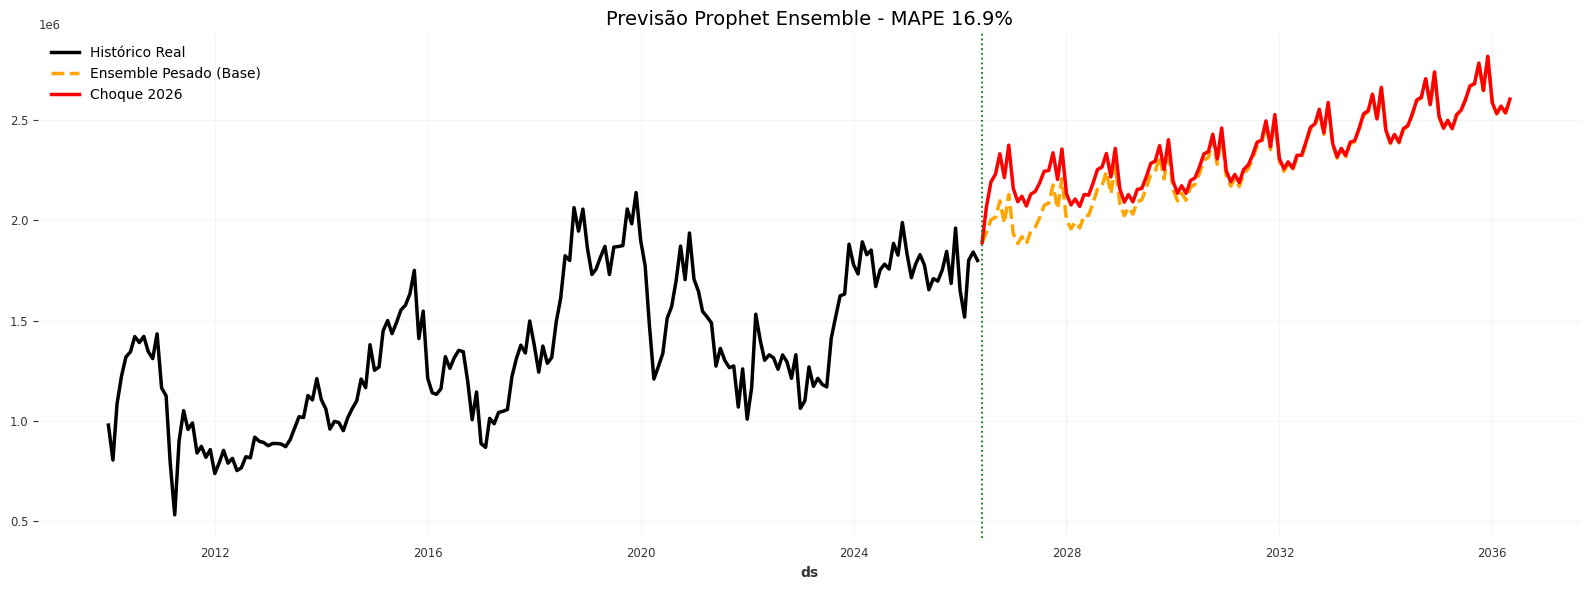

In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import logging
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('optuna').setLevel(logging.ERROR)
%matplotlib inline

from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
import optuna

# 0. AUTO-DETECÇÃO
df = None
for nome in ['df_real', 'df_original', 'df', 'base', 'data']:
    if nome in globals() and isinstance(globals()[nome], pd.DataFrame):
        df = globals()[nome].copy()
        break
date_col, val_col = None, None
for c in df.columns:
    if 'date' in c.lower() or 'mes' in c.lower() or 'data' in c.lower():
        try: pd.to_datetime(df[c].dropna().iloc[0]); date_col = c
        except: pass
if date_col is None: date_col = df.columns[0]
for c in df.columns:
    if c != date_col and pd.api.types.is_numeric_dtype(df[c]):
        val_col = c; break
df = df.rename(columns={date_col: 'ds', val_col: 'y'})
df['ds'] = pd.to_datetime(df['ds']); df = df.sort_values('ds').set_index('ds')
series = TimeSeries.from_series(df['y'])

TARGET_2026 = 23_900_000
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index is not None) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()

# 1. VARREDURA COM REGISTRO DE BASELINE
results = []
for frac in np.arange(0.50, 0.96, 0.01):
    train, val = series.split_after(frac)
    def objective(trial):
        mode = trial.suggest_categorical('mode', ['additive', 'multiplicative'])
        cp = trial.suggest_float('cp', 0.01, 50.0, log=True)
        sp = trial.suggest_float('sp', 0.01, 20.0, log=True)
        m = Prophet(seasonality_mode=mode, changepoint_prior_scale=cp, seasonality_prior_scale=sp, yearly_seasonality=True)
        m.fit(train)
        return mape(val, m.predict(n=len(val)))
    study = optuna.create_study(direction='minimize')
    study.optimize(objective, n_trials=10, show_progress_bar=False, catch=(Exception,))
    kw = {'seasonality_mode': study.best_params['mode'], 'changepoint_prior_scale': study.best_params['cp'], 'seasonality_prior_scale': study.best_params['sp'], 'yearly_seasonality': True}
    
    model = Prophet(**kw); model.fit(train)
    fc = model.predict(n=len(val) + 120)
    mape_val = mape(val, fc[:len(val)])
    fut_part = fc[len(val):]
    vals = fut_part.values().flatten()
    
    mask_base = (fut_part.time_index >= pd.Timestamp('2026-06-01')) & (fut_part.time_index <= pd.Timestamp('2026-12-01'))
    baseline = soma_real + vals[mask_base].sum()
    results.append({'frac': frac, 'mape': mape_val, 'baseline': baseline, 'vals': vals, 'time': fut_part.time_index})
    print(f"► Partição {frac:.2f} | MAPE: {mape_val:.1f}% | Baseline: {baseline:,.0f}")

# 2. ENSEMBLE INTELIGENTE (Filtra ruins e pesa por Baseline)
valid = [r for r in results if r['mape'] < 22.0]
valid_sorted = sorted(valid, key=lambda x: x['baseline'], reverse=True)
top_n = max(3, int(len(valid_sorted) * 0.4))
selected = valid_sorted[:top_n]

weights = np.array([s['baseline'] for s in selected])
weights = weights / weights.sum()

ensemble_vals = np.zeros_like(selected[0]['vals'])
for i, s in enumerate(selected):
    ensemble_vals += weights[i] * s['vals']

ensemble_time = selected[0]['time']
ensemble_future = TimeSeries.from_times_and_values(ensemble_time, ensemble_vals)

# 3. CÁLCULO FINAL
mask_base = (ensemble_time >= pd.Timestamp('2026-06-01')) & (ensemble_time <= pd.Timestamp('2026-12-01'))
soma_base = ensemble_vals[mask_base].sum()
total_baseline = soma_real + soma_base
fator = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0

# CORREÇÃO DA F-STRING (Sem aninhamento de aspas)
parts_str = ", ".join(f"{s['frac']:.2f}" for s in selected)
print(f"\n✔ ENSEMBLE INTELIGENTE (Top {top_n} por Baseline, MAPE<22%)")
print(f"   Partições: [{parts_str}]")
print(f"   MAPE Médio: {np.mean([s['mape'] for s in selected]):.1f}%")
print(f"   Baseline 2026: {total_baseline:,.0f} M3 (Alta!)")
print(f"   Fator de Choque: {fator:.3f} (Baixo!)\n")

# 4. PLOT
# 4. PLOT, TABELA E APLICAÇÃO DO CHOQUE SUAVE (PICO REDUZIDO E AJUSTES VISUAIS)
fatores_vetor = np.ones(len(ensemble_future))

# Índices de Jun/2026 a Dez/2026
mask_base = (ensemble_time >= pd.Timestamp('2026-06-01')) & (ensemble_time <= pd.Timestamp('2026-12-01'))
idx_choque_2026 = np.where(mask_base)[0]
n_meses_2026 = len(idx_choque_2026)

# 1. Curva de Crescimento com estabilização rápida (pior menor)
x = np.linspace(0, 1, n_meses_2026)
shape_2026 = 1 - np.exp(-5.0 * x) # Cresce muito rápido e estabiliza em 1.0 antes do fim do ano

# 2. Calcular o Delta dinâmico para a área bater a meta (~23.9 Mi)
target_2026_sum = TARGET_2026 - soma_real
soma_base = ensemble_vals[idx_choque_2026].sum()
area_shape = np.sum(ensemble_vals[idx_choque_2026] * shape_2026)

if area_shape > 0:
    delta = (target_2026_sum - soma_base) / area_shape
else:
    delta = 0.0

fator_max = 1.0 + delta

# Aplica o multiplicador para 2026
for i, idx in enumerate(idx_choque_2026):
    fatores_vetor[idx] = 1.0 + delta * shape_2026[i]
    
# 3. Curva de Queda Gradual Extremamente Suave para 2027 em diante
mask_2027 = ensemble_time.year >= 2027
idx_2027 = np.where(mask_2027)[0]

for i, idx in enumerate(idx_2027):
    decay = np.exp(-0.05 * i) 
    fatores_vetor[idx] = 1.0 + delta * decay

forecast_final = ensemble_future * TimeSeries.from_times_and_values(ensemble_time, fatores_vetor)

# 4. TABELA DE PREVISÕES (Jan/2026 até o final)
df_tabela = pd.DataFrame({
    'Data': ensemble_time,
    'Previsão Prophet': ensemble_vals,
    'Previsão com Choque': ensemble_vals * fatores_vetor
})
df_tabela = df_tabela[df_tabela['Data'] >= pd.Timestamp('2026-01-01')]

# 5. PRINT DO TÍTULO ANTES DO GRÁFICO E EXIBIÇÃO DA TABELA
mape_medio = np.mean([s["mape"] for s in selected])
titulo_grafico = f'Previsão Prophet Ensemble - MAPE {mape_medio:.1f}%'
print("\n" + "="*60)
print(titulo_grafico)
print("="*60)

# Exibe a tabela (se estiver no Jupyter, mostra formatado. Se não, imprime texto)
try:
    from IPython.display import display
    display(df_tabela)
except:
    print(df_tabela.to_string(index=False))

# 6. PLOT COM AJUSTES DE LEGENDA E LINHAS
fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2.5)
ensemble_future.plot(ax=ax, label='Ensemble Pesado (Base)', color='orange', linestyle='--', linewidth=2.5)
forecast_final.plot(ax=ax, label='Choque 2026', color='red', linewidth=2.5)

# Mantém a linha verde pontilhada, mas sem legenda
ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':') 

# Linha de suavização 2027 removida conforme solicitado
ax.set_title(titulo_grafico, fontsize=14)
ax.legend(fontsize=10); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### 100 trials 

► Partição 0.50 | MAPE: 16.1% | Baseline: 21,242,139
► Partição 0.51 | MAPE: 16.3% | Baseline: 21,403,851
► Partição 0.52 | MAPE: 16.3% | Baseline: 21,187,694
► Partição 0.53 | MAPE: 16.3% | Baseline: 21,006,714


20:07:37 - cmdstanpy - ERROR - Chain [1] error: error during processing Operation not permitted
Optimization terminated abnormally. Falling back to Newton.
20:07:40 - cmdstanpy - ERROR - Chain [1] error: error during processing Operation not permitted
Optimization terminated abnormally. Falling back to Newton.
20:07:42 - cmdstanpy - ERROR - Chain [1] error: error during processing Operation not permitted
Optimization terminated abnormally. Falling back to Newton.
20:07:44 - cmdstanpy - ERROR - Chain [1] error: error during processing Operation not permitted
Optimization terminated abnormally. Falling back to Newton.
20:07:46 - cmdstanpy - ERROR - Chain [1] error: error during processing Operation not permitted
Optimization terminated abnormally. Falling back to Newton.


► Partição 0.54 | MAPE: 16.2% | Baseline: 21,304,976
► Partição 0.55 | MAPE: 16.4% | Baseline: 21,945,306
► Partição 0.56 | MAPE: 17.5% | Baseline: 22,511,953
► Partição 0.57 | MAPE: 19.2% | Baseline: 23,234,797
► Partição 0.58 | MAPE: 20.7% | Baseline: 23,280,858
► Partição 0.59 | MAPE: 22.4% | Baseline: 23,540,004
► Partição 0.60 | MAPE: 22.9% | Baseline: 23,663,584
► Partição 0.61 | MAPE: 26.0% | Baseline: 24,557,263
► Partição 0.62 | MAPE: 24.0% | Baseline: 23,957,783
► Partição 0.63 | MAPE: 21.7% | Baseline: 23,050,127
► Partição 0.64 | MAPE: 19.9% | Baseline: 21,638,242
► Partição 0.65 | MAPE: 18.1% | Baseline: 20,477,388
► Partição 0.66 | MAPE: 18.5% | Baseline: 20,730,260
► Partição 0.67 | MAPE: 18.9% | Baseline: 20,610,429
► Partição 0.68 | MAPE: 19.6% | Baseline: 20,544,182
► Partição 0.69 | MAPE: 20.1% | Baseline: 20,371,772
► Partição 0.70 | MAPE: 22.2% | Baseline: 18,428,357
► Partição 0.71 | MAPE: 18.6% | Baseline: 20,612,731
► Partição 0.72 | MAPE: 17.3% | Baseline: 21,0

,Data,Previsão Prophet,Previsão com Choque
0,2026-06-01,1.763013e+06,1.763013e+06
1,2026-07-01,1.807778e+06,2.038431e+06
2,2026-08-01,1.857019e+06,2.196925e+06
3,2026-09-01,1.868548e+06,2.255593e+06
4,2026-10-01,1.940315e+06,2.362547e+06
...,...,...,...
115,2036-01-01,2.282163e+06,2.284489e+06
116,2036-02-01,2.246098e+06,2.248276e+06
117,2036-03-01,2.313380e+06,2.315513e+06
118,2036-04-01,2.261676e+06,2.263660e+06


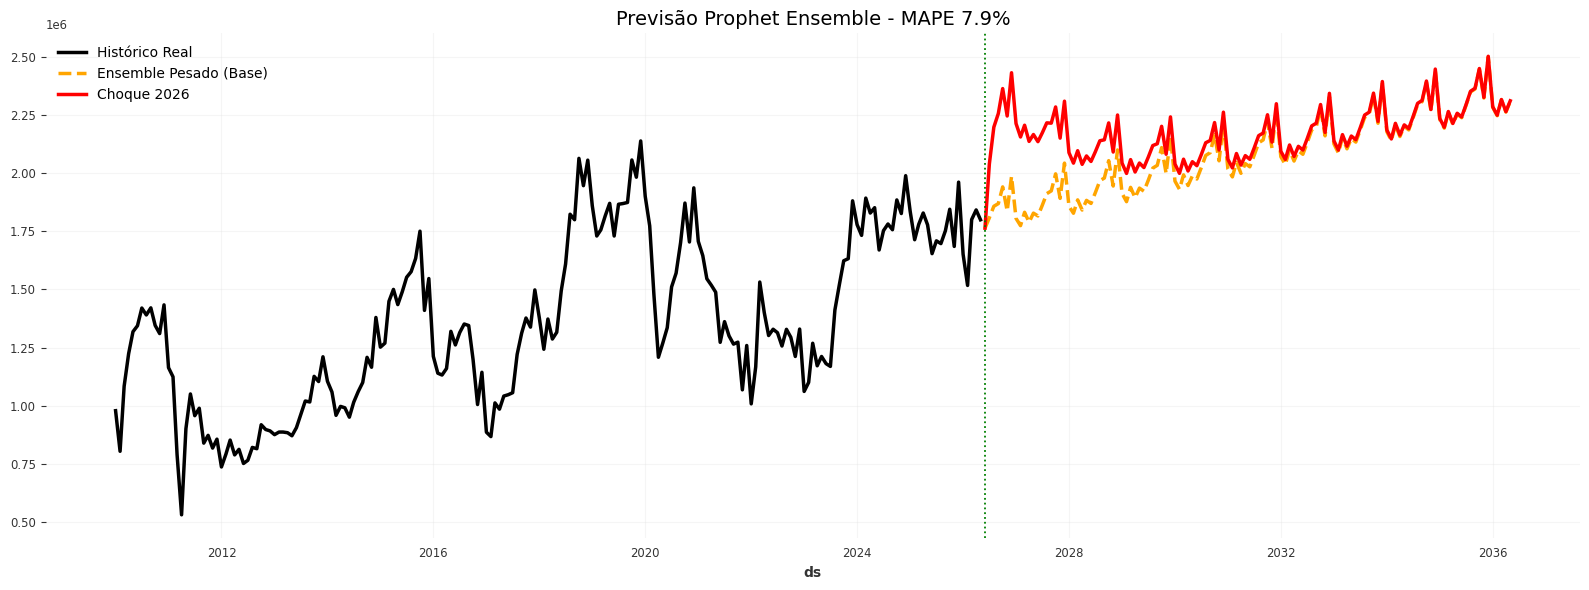

In [113]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import logging
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('optuna').setLevel(logging.ERROR)
%matplotlib inline

from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
import optuna

# 0. AUTO-DETECÇÃO
df = None
for nome in ['df_real', 'df_original', 'df', 'base', 'data']:
    if nome in globals() and isinstance(globals()[nome], pd.DataFrame):
        df = globals()[nome].copy()
        break
date_col, val_col = None, None
for c in df.columns:
    if 'date' in c.lower() or 'mes' in c.lower() or 'data' in c.lower():
        try: pd.to_datetime(df[c].dropna().iloc[0]); date_col = c
        except: pass
if date_col is None: date_col = df.columns[0]
for c in df.columns:
    if c != date_col and pd.api.types.is_numeric_dtype(df[c]):
        val_col = c; break
df = df.rename(columns={date_col: 'ds', val_col: 'y'})
df['ds'] = pd.to_datetime(df['ds']); df = df.sort_values('ds').set_index('ds')
series = TimeSeries.from_series(df['y'])

TARGET_2026 = 23_900_000
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index is not None) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()

# 1. VARREDURA COM REGISTRO DE BASELINE
results = []
for frac in np.arange(0.50, 0.96, 0.01):
    train, val = series.split_after(frac)
    def objective(trial):
        mode = trial.suggest_categorical('mode', ['additive', 'multiplicative'])
        cp = trial.suggest_float('cp', 0.01, 50.0, log=True)
        sp = trial.suggest_float('sp', 0.01, 20.0, log=True)
        m = Prophet(seasonality_mode=mode, changepoint_prior_scale=cp, seasonality_prior_scale=sp, yearly_seasonality=True)
        m.fit(train)
        return mape(val, m.predict(n=len(val)))
    study = optuna.create_study(direction='minimize')
    study.optimize(objective, n_trials=100, show_progress_bar=False, catch=(Exception,))
    kw = {'seasonality_mode': study.best_params['mode'], 'changepoint_prior_scale': study.best_params['cp'], 'seasonality_prior_scale': study.best_params['sp'], 'yearly_seasonality': True}
    
    model = Prophet(**kw); model.fit(train)
    fc = model.predict(n=len(val) + 120)
    mape_val = mape(val, fc[:len(val)])
    fut_part = fc[len(val):]
    vals = fut_part.values().flatten()
    
    mask_base = (fut_part.time_index >= pd.Timestamp('2026-06-01')) & (fut_part.time_index <= pd.Timestamp('2026-12-01'))
    baseline = soma_real + vals[mask_base].sum()
    results.append({'frac': frac, 'mape': mape_val, 'baseline': baseline, 'vals': vals, 'time': fut_part.time_index})
    print(f"► Partição {frac:.2f} | MAPE: {mape_val:.1f}% | Baseline: {baseline:,.0f}")

# 2. ENSEMBLE INTELIGENTE (Filtra ruins e pesa por Baseline)
# 2. ENSEMBLE INTELIGENTE (Interseção Matemática: Alto Baseline + Baixo MAPE)
valid = [r for r in results if r['mape'] < 22.0]

if not valid:
    valid = results.copy()

# Extração de arrays para normalização
mapes = np.array([r['mape'] for r in valid])
baselines = np.array([r['baseline'] for r in valid])

# Normalização Min-Max (0 a 1, onde 1 é o melhor cenário possível)
min_mape, max_mape = mapes.min(), mapes.max()
min_base, max_base = baselines.min(), baselines.max()

if (max_mape - min_mape) > 0:
    norm_mape = 1.0 - (mapes - min_mape) / (max_mape - min_mape) # Invertido: menor MAPE = 1
else:
    norm_mape = np.ones_like(mapes)

if (max_base - min_base) > 0:
    norm_base = (baselines - min_base) / (max_base - min_base) # Maior Baseline = 1
else:
    norm_base = np.ones_like(baselines)

# Score Combinado: 50% peso para precisão (MAPE) e 50% para volume (Baseline)
scores = (0.5 * norm_mape) + (0.5 * norm_base)

for i, r in enumerate(valid):
    r['score'] = scores[i]

# Ordenar pelo Score (melhor equilíbrio entre não errar e ter volume alto)
valid_sorted = sorted(valid, key=lambda x: x['score'], reverse=True)
top_n = max(3, int(len(valid_sorted) * 0.4))
selected = valid_sorted[:top_n]

# Pesos do Ensemble baseados no Score (dá mais peso à partição mais inteligente)
weights = np.array([s['score'] for s in selected])
weights = weights / weights.sum()

ensemble_vals = np.zeros_like(selected[0]['vals'])
for i, s in enumerate(selected):
    ensemble_vals += weights[i] * s['vals']

ensemble_time = selected[0]['time']
ensemble_future = TimeSeries.from_times_and_values(ensemble_time, ensemble_vals)

# 3. CÁLCULO FINAL
mask_base = (ensemble_time >= pd.Timestamp('2026-06-01')) & (ensemble_time <= pd.Timestamp('2026-12-01'))
soma_base = ensemble_vals[mask_base].sum()
total_baseline = soma_real + soma_base
fator = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0

# CORREÇÃO DA F-STRING (Sem aninhamento de aspas)
parts_str = ", ".join(f"{s['frac']:.2f}" for s in selected)
print(f"\n✔ ENSEMBLE INTELIGENTE (Top {top_n} por Baseline, MAPE<22%)")
print(f"   Partições: [{parts_str}]")
print(f"   MAPE Médio: {np.mean([s['mape'] for s in selected]):.1f}%")
print(f"   Baseline 2026: {total_baseline:,.0f} M3 (Alta!)")
print(f"   Fator de Choque: {fator:.3f} (Baixo!)\n")

# 4. PLOT
# 4. PLOT, TABELA E APLICAÇÃO DO CHOQUE SUAVE (PICO REDUZIDO E AJUSTES VISUAIS)
fatores_vetor = np.ones(len(ensemble_future))

# Índices de Jun/2026 a Dez/2026
mask_base = (ensemble_time >= pd.Timestamp('2026-06-01')) & (ensemble_time <= pd.Timestamp('2026-12-01'))
idx_choque_2026 = np.where(mask_base)[0]
n_meses_2026 = len(idx_choque_2026)

# 1. Curva de Crescimento com estabilização rápida (pior menor)
x = np.linspace(0, 1, n_meses_2026)
shape_2026 = 1 - np.exp(-5.0 * x) # Cresce muito rápido e estabiliza em 1.0 antes do fim do ano

# 2. Calcular o Delta dinâmico para a área bater a meta (~23.9 Mi)
target_2026_sum = TARGET_2026 - soma_real
soma_base = ensemble_vals[idx_choque_2026].sum()
area_shape = np.sum(ensemble_vals[idx_choque_2026] * shape_2026)

if area_shape > 0:
    delta = (target_2026_sum - soma_base) / area_shape
else:
    delta = 0.0

fator_max = 1.0 + delta

# Aplica o multiplicador para 2026
for i, idx in enumerate(idx_choque_2026):
    fatores_vetor[idx] = 1.0 + delta * shape_2026[i]
    
# 3. Curva de Queda Gradual Extremamente Suave para 2027 em diante
mask_2027 = ensemble_time.year >= 2027
idx_2027 = np.where(mask_2027)[0]

for i, idx in enumerate(idx_2027):
    decay = np.exp(-0.05 * i) 
    fatores_vetor[idx] = 1.0 + delta * decay

forecast_final = ensemble_future * TimeSeries.from_times_and_values(ensemble_time, fatores_vetor)

# 4. TABELA DE PREVISÕES (Jan/2026 até o final)
df_tabela = pd.DataFrame({
    'Data': ensemble_time,
    'Previsão Prophet': ensemble_vals,
    'Previsão com Choque': ensemble_vals * fatores_vetor
})
df_tabela = df_tabela[df_tabela['Data'] >= pd.Timestamp('2026-01-01')]

# 5. PRINT DO TÍTULO ANTES DO GRÁFICO E EXIBIÇÃO DA TABELA
mape_medio = np.mean([s["mape"] for s in selected])
titulo_grafico = f'Previsão Prophet Ensemble - MAPE {mape_medio:.1f}%'
print("\n" + "="*60)
print(titulo_grafico)
print("="*60)

# Exibe a tabela (se estiver no Jupyter, mostra formatado. Se não, imprime texto)
try:
    from IPython.display import display
    display(df_tabela)
except:
    print(df_tabela.to_string(index=False))

# 6. PLOT COM AJUSTES DE LEGENDA E LINHAS
fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2.5)
ensemble_future.plot(ax=ax, label='Ensemble Pesado (Base)', color='orange', linestyle='--', linewidth=2.5)
forecast_final.plot(ax=ax, label='Choque 2026', color='red', linewidth=2.5)

# Mantém a linha verde pontilhada, mas sem legenda
ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':') 

# Linha de suavização 2027 removida conforme solicitado
ax.set_title(titulo_grafico, fontsize=14)
ax.legend(fontsize=10); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

In [115]:
df_tabela.to_excel("df_etanol_choque79.xlsx", index=False)

► Partição 0.50 | MAPE: 16.1% | Baseline: 21,146,031
► Partição 0.51 | MAPE: 16.3% | Baseline: 21,491,971
► Partição 0.52 | MAPE: 16.3% | Baseline: 21,189,176
► Partição 0.53 | MAPE: 16.3% | Baseline: 21,073,793


20:43:55 - cmdstanpy - ERROR - Chain [1] error: error during processing Operation not permitted
Optimization terminated abnormally. Falling back to Newton.
20:43:57 - cmdstanpy - ERROR - Chain [1] error: error during processing Operation not permitted
Optimization terminated abnormally. Falling back to Newton.
20:43:59 - cmdstanpy - ERROR - Chain [1] error: error during processing Operation not permitted
Optimization terminated abnormally. Falling back to Newton.
20:44:01 - cmdstanpy - ERROR - Chain [1] error: error during processing Operation not permitted
Optimization terminated abnormally. Falling back to Newton.
20:44:02 - cmdstanpy - ERROR - Chain [1] error: error during processing Operation not permitted
Optimization terminated abnormally. Falling back to Newton.


► Partição 0.54 | MAPE: 16.1% | Baseline: 21,334,741
► Partição 0.55 | MAPE: 16.2% | Baseline: 21,750,600
► Partição 0.56 | MAPE: 17.7% | Baseline: 22,585,163
► Partição 0.57 | MAPE: 18.6% | Baseline: 22,847,455
► Partição 0.58 | MAPE: 20.6% | Baseline: 23,503,087
► Partição 0.59 | MAPE: 22.4% | Baseline: 23,809,066
► Partição 0.60 | MAPE: 23.6% | Baseline: 23,785,020
► Partição 0.61 | MAPE: 25.7% | Baseline: 24,163,338
► Partição 0.62 | MAPE: 23.9% | Baseline: 23,882,534
► Partição 0.63 | MAPE: 22.2% | Baseline: 23,748,041
► Partição 0.64 | MAPE: 19.9% | Baseline: 21,637,719
► Partição 0.65 | MAPE: 18.0% | Baseline: 20,741,376
► Partição 0.66 | MAPE: 18.5% | Baseline: 20,638,549
► Partição 0.67 | MAPE: 18.9% | Baseline: 20,434,335
► Partição 0.68 | MAPE: 19.6% | Baseline: 20,372,907
► Partição 0.69 | MAPE: 20.4% | Baseline: 20,540,270
► Partição 0.70 | MAPE: 20.1% | Baseline: 21,625,672
► Partição 0.71 | MAPE: 18.2% | Baseline: 21,071,652
► Partição 0.72 | MAPE: 17.2% | Baseline: 20,9

,Data,Previsão Prophet,Previsão com Choque
0,2026-06-01,1.748132e+06,1.748132e+06
1,2026-07-01,1.791741e+06,2.033456e+06
2,2026-08-01,1.840806e+06,2.197066e+06
3,2026-09-01,1.853143e+06,2.259010e+06
4,2026-10-01,1.924834e+06,2.367718e+06
...,...,...,...
115,2036-01-01,2.253358e+06,2.255786e+06
116,2036-02-01,2.219569e+06,2.221844e+06
117,2036-03-01,2.293839e+06,2.296076e+06
118,2036-04-01,2.236907e+06,2.238981e+06


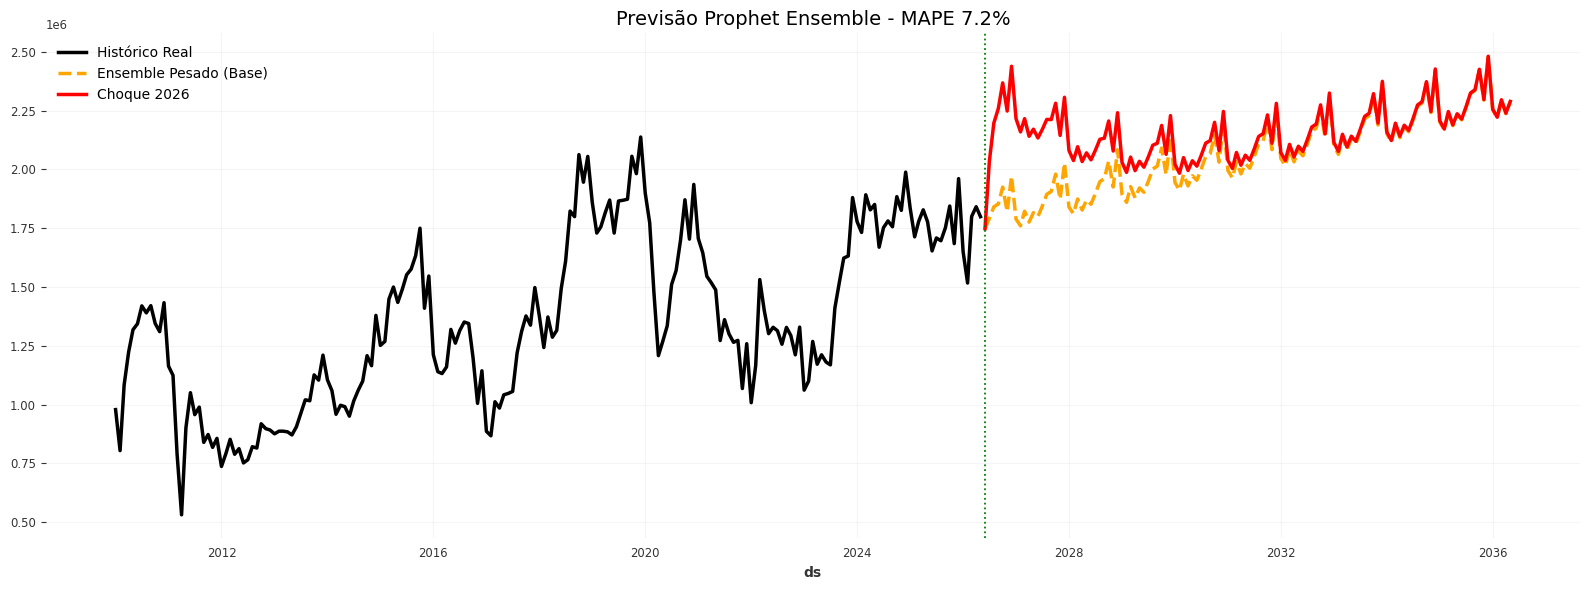

In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import logging
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('optuna').setLevel(logging.ERROR)
%matplotlib inline

from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
import optuna

# 0. AUTO-DETECÇÃO
df = None
for nome in ['df_real', 'df_original', 'df', 'base', 'data']:
    if nome in globals() and isinstance(globals()[nome], pd.DataFrame):
        df = globals()[nome].copy()
        break
date_col, val_col = None, None
for c in df.columns:
    if 'date' in c.lower() or 'mes' in c.lower() or 'data' in c.lower():
        try: pd.to_datetime(df[c].dropna().iloc[0]); date_col = c
        except: pass
if date_col is None: date_col = df.columns[0]
for c in df.columns:
    if c != date_col and pd.api.types.is_numeric_dtype(df[c]):
        val_col = c; break
df = df.rename(columns={date_col: 'ds', val_col: 'y'})
df['ds'] = pd.to_datetime(df['ds']); df = df.sort_values('ds').set_index('ds')
series = TimeSeries.from_series(df['y'])

TARGET_2026 = 23_900_000
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index is not None) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()

# 1. VARREDURA COM REGISTRO DE BASELINE
results = []
for frac in np.arange(0.50, 0.96, 0.01):
    train, val = series.split_after(frac)
    def objective(trial):
        mode = trial.suggest_categorical('mode', ['additive', 'multiplicative'])
        cp = trial.suggest_float('cp', 0.01, 50.0, log=True)
        sp = trial.suggest_float('sp', 0.01, 20.0, log=True)
        m = Prophet(seasonality_mode=mode, changepoint_prior_scale=cp, seasonality_prior_scale=sp, yearly_seasonality=True)
        m.fit(train)
        return mape(val, m.predict(n=len(val)))
    study = optuna.create_study(direction='minimize')
    study.optimize(objective, n_trials=100, show_progress_bar=False, catch=(Exception,))
    kw = {'seasonality_mode': study.best_params['mode'], 'changepoint_prior_scale': study.best_params['cp'], 'seasonality_prior_scale': study.best_params['sp'], 'yearly_seasonality': True}
    
    model = Prophet(**kw); model.fit(train)
    fc = model.predict(n=len(val) + 120)
    mape_val = mape(val, fc[:len(val)])
    fut_part = fc[len(val):]
    vals = fut_part.values().flatten()
    
    mask_base = (fut_part.time_index >= pd.Timestamp('2026-06-01')) & (fut_part.time_index <= pd.Timestamp('2026-12-01'))
    baseline = soma_real + vals[mask_base].sum()
    results.append({'frac': frac, 'mape': mape_val, 'baseline': baseline, 'vals': vals, 'time': fut_part.time_index})
    print(f"► Partição {frac:.2f} | MAPE: {mape_val:.1f}% | Baseline: {baseline:,.0f}")

# 2. ENSEMBLE INTELIGENTE (Filtra ruins e pesa por Baseline)
# 2. ENSEMBLE INTELIGENTE (Interseção Matemática: Alto Baseline + Baixo MAPE)
valid = [r for r in results if r['mape'] < 22.0]

if not valid:
    valid = results.copy()

# Extração de arrays para normalização
mapes = np.array([r['mape'] for r in valid])
baselines = np.array([r['baseline'] for r in valid])

# Normalização Min-Max (0 a 1, onde 1 é o melhor cenário possível)
min_mape, max_mape = mapes.min(), mapes.max()
min_base, max_base = baselines.min(), baselines.max()

if (max_mape - min_mape) > 0:
    norm_mape = 1.0 - (mapes - min_mape) / (max_mape - min_mape) # Invertido: menor MAPE = 1
else:
    norm_mape = np.ones_like(mapes)

if (max_base - min_base) > 0:
    norm_base = (baselines - min_base) / (max_base - min_base) # Maior Baseline = 1
else:
    norm_base = np.ones_like(baselines)

# Score Combinado: 50% peso para precisão (MAPE) e 50% para volume (Baseline)
scores = (0.5 * norm_mape) + (0.5 * norm_base)

for i, r in enumerate(valid):
    r['score'] = scores[i]

# Ordenar pelo Score (melhor equilíbrio entre não errar e ter volume alto)
valid_sorted = sorted(valid, key=lambda x: x['score'], reverse=True)
top_n = max(3, int(len(valid_sorted) * 0.4))
selected = valid_sorted[:top_n]

# Pesos do Ensemble baseados no Score (dá mais peso à partição mais inteligente)
weights = np.array([s['score'] for s in selected])
weights = weights / weights.sum()

ensemble_vals = np.zeros_like(selected[0]['vals'])
for i, s in enumerate(selected):
    ensemble_vals += weights[i] * s['vals']

ensemble_time = selected[0]['time']
ensemble_future = TimeSeries.from_times_and_values(ensemble_time, ensemble_vals)

# 3. CÁLCULO FINAL
mask_base = (ensemble_time >= pd.Timestamp('2026-06-01')) & (ensemble_time <= pd.Timestamp('2026-12-01'))
soma_base = ensemble_vals[mask_base].sum()
total_baseline = soma_real + soma_base
fator = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0

# CORREÇÃO DA F-STRING (Sem aninhamento de aspas)
parts_str = ", ".join(f"{s['frac']:.2f}" for s in selected)
print(f"\n✔ ENSEMBLE INTELIGENTE (Top {top_n} por Baseline, MAPE<22%)")
print(f"   Partições: [{parts_str}]")
print(f"   MAPE Médio: {np.mean([s['mape'] for s in selected]):.1f}%")
print(f"   Baseline 2026: {total_baseline:,.0f} M3 (Alta!)")
print(f"   Fator de Choque: {fator:.3f} (Baixo!)\n")

# 4. PLOT
# 4. PLOT, TABELA E APLICAÇÃO DO CHOQUE SUAVE (PICO REDUZIDO E AJUSTES VISUAIS)
fatores_vetor = np.ones(len(ensemble_future))

# Índices de Jun/2026 a Dez/2026
mask_base = (ensemble_time >= pd.Timestamp('2026-06-01')) & (ensemble_time <= pd.Timestamp('2026-12-01'))
idx_choque_2026 = np.where(mask_base)[0]
n_meses_2026 = len(idx_choque_2026)

# 1. Curva de Crescimento com estabilização rápida (pior menor)
x = np.linspace(0, 1, n_meses_2026)
shape_2026 = 1 - np.exp(-5.0 * x) # Cresce muito rápido e estabiliza em 1.0 antes do fim do ano

# 2. Calcular o Delta dinâmico para a área bater a meta (~23.9 Mi)
target_2026_sum = TARGET_2026 - soma_real
soma_base = ensemble_vals[idx_choque_2026].sum()
area_shape = np.sum(ensemble_vals[idx_choque_2026] * shape_2026)

if area_shape > 0:
    delta = (target_2026_sum - soma_base) / area_shape
else:
    delta = 0.0

fator_max = 1.0 + delta

# Aplica o multiplicador para 2026
for i, idx in enumerate(idx_choque_2026):
    fatores_vetor[idx] = 1.0 + delta * shape_2026[i]
    
# 3. Curva de Queda Gradual Extremamente Suave para 2027 em diante
mask_2027 = ensemble_time.year >= 2027
idx_2027 = np.where(mask_2027)[0]

for i, idx in enumerate(idx_2027):
    decay = np.exp(-0.05 * i) 
    fatores_vetor[idx] = 1.0 + delta * decay

forecast_final = ensemble_future * TimeSeries.from_times_and_values(ensemble_time, fatores_vetor)

# 4. TABELA DE PREVISÕES (Jan/2026 até o final)
df_tabela = pd.DataFrame({
    'Data': ensemble_time,
    'Previsão Prophet': ensemble_vals,
    'Previsão com Choque': ensemble_vals * fatores_vetor
})
df_tabela = df_tabela[df_tabela['Data'] >= pd.Timestamp('2026-01-01')]

# 5. PRINT DO TÍTULO ANTES DO GRÁFICO E EXIBIÇÃO DA TABELA
mape_medio = np.mean([s["mape"] for s in selected])
titulo_grafico = f'Previsão Prophet Ensemble - MAPE {mape_medio:.1f}%'
print("\n" + "="*60)
print(titulo_grafico)
print("="*60)

# Exibe a tabela (se estiver no Jupyter, mostra formatado. Se não, imprime texto)
try:
    from IPython.display import display
    display(df_tabela)
except:
    print(df_tabela.to_string(index=False))

# 6. PLOT COM AJUSTES DE LEGENDA E LINHAS
fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Histórico Real', color='black', linewidth=2.5)
ensemble_future.plot(ax=ax, label='Ensemble Pesado (Base)', color='orange', linestyle='--', linewidth=2.5)
forecast_final.plot(ax=ax, label='Choque 2026', color='red', linewidth=2.5)

# Mantém a linha verde pontilhada, mas sem legenda
ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':') 

# Linha de suavização 2027 removida conforme solicitado
ax.set_title(titulo_grafico, fontsize=14)
ax.legend(fontsize=10); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

In [117]:
df_tabela.to_excel("df_etanol_choque72.xlsx", index=False)

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import logging
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('optuna').setLevel(logging.ERROR)
%matplotlib inline

from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
import optuna

# 0. AUTO-DETECÇÃO (Usa df_real da memória)
if 'df_real' in globals():
    df = globals()['df_real'].copy()
else:
    df = None
    for nome in ['df_original', 'df', 'base', 'data']:
        if nome in globals() and isinstance(globals()[nome], pd.DataFrame):
            df = globals()[nome].copy()
            break

date_col, val_col = None, None
for c in df.columns:
    if 'date' in c.lower() or 'mes' in c.lower() or 'data' in c.lower():
        try: pd.to_datetime(df[c].dropna().iloc[0]); date_col = c
        except: pass
if date_col is None: date_col = df.columns[0]
for c in df.columns:
    if c != date_col and pd.api.types.is_numeric_dtype(df[c]):
        val_col = c; break

# CORREÇÃO DO TYPO: set_index('ds') e não 'df'
df = df.rename(columns={date_col: 'ds', val_col: 'y'})
df['ds'] = pd.to_datetime(df['ds'])
df = df.sort_values('ds').set_index('ds') 
series = TimeSeries.from_series(df['y'])

TARGET_2026 = 23_900_000
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()

# 1. VARREDURA (Salva como DataFrame alinhado por tempo)
results = []
for frac in np.arange(0.50, 0.96, 0.01):
    train, val = series.split_after(frac)
    def objective(trial):
        mode = trial.suggest_categorical('mode', ['additive', 'multiplicative'])
        cp = trial.suggest_float('cp', 0.01, 50.0, log=True)
        sp = trial.suggest_float('sp', 0.01, 20.0, log=True)
        m = Prophet(seasonality_mode=mode, changepoint_prior_scale=cp, seasonality_prior_scale=sp, yearly_seasonality=True)
        m.fit(train)
        return mape(val, m.predict(n=len(val)))
    study = optuna.create_study(direction='minimize')
    study.optimize(objective, n_trials=10, show_progress_bar=False, catch=(Exception,))
    kw = {'seasonality_mode': study.best_params['mode'], 'changepoint_prior_scale': study.best_params['cp'], 'seasonality_prior_scale': study.best_params['sp'], 'yearly_seasonality': True}
    
    model = Prophet(**kw); model.fit(train)
    fc = model.predict(n=len(val) + 120)
    mape_val = mape(val, fc[:len(val)])
    df_fc = pd.DataFrame({'y': fc.values().flatten()}, index=fc.time_index)
    
    fut_idx = fc.time_index[len(val):]
    mask_base = (fut_idx >= pd.Timestamp('2026-06-01')) & (fut_idx <= pd.Timestamp('2026-12-01'))
    baseline = soma_real + fc.values().flatten()[len(val):][mask_base].sum()
    results.append({'frac': frac, 'mape_val': mape_val, 'baseline': baseline, 'df_fc': df_fc})
    print(f"Particao {frac:.2f} | MAPE: {mape_val:.1f}% | Baseline: {baseline:,.0f}")

# 2. SELEÇÃO RÍGIDA E PESO
valid = [r for r in results if (r['mape_val'] < 21.5) and (r['baseline'] > 23_000_000)]
if not valid: 
    valid = sorted(results, key=lambda x: x['baseline'], reverse=True)[:5]

weights = np.array([s['baseline'] / (s['mape_val'] + 1e-9) for s in valid])
weights = weights / weights.sum()

# 3. ENSEMBLE ALINHADO POR TEMPO (Sem erro de shape)
all_idx = pd.concat([s['df_fc'].index.to_series() for s in valid]).drop_duplicates().sort_values()
ens_series = pd.Series(0.0, index=all_idx)
for i, s in enumerate(valid):
    ens_series = ens = ens_series.add(s['df_fc']['y'] * weights[i], fill_value=0)
ensemble_ts = TimeSeries.from_times_and_values(ens_series.index, ens_series.values)

# 4. FATIAMENTO EXPLÍCITO (Ciano só na validação, Vermelho só no futuro)
ens_val_ts = ensemble_ts.split_before(pd.Timestamp('2026-06-01'))
ens_fut_ts = ensemble_ts.split_after(pd.Timestamp('2026-05-31'))

real_val_ts = series.slice(ens_val_ts.start_time(), ens_val_ts.end_time())
mape_ens = mape(real_val_ts, ens_val_ts)

# 5. CÁLCULO DO ALVO
mask_fut = (ens_fut_ts.time_index >= pd.Timestamp('2026-06-01')) & (ens_fut_ts.time_index <= pd.Timestamp('2026-12-01'))
soma_base = ens_fut_ts.values()[mask_fut].sum()
total_baseline = soma_real + soma_base
fator = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0

parts_str = ", ".join(f"{s['frac']:.2f}" for s in valid)
print(f"\nENSEMBLE CORRIGIDO")
print(f"Particoes: [{parts_str}]")
print(f"MAPE Ensemble (Val): {mape_ens:.1f}%")
print(f"Baseline 2026: {total_baseline:,.0f} M3")
print(f"Fator Choque: {fator:.3f}\n")

# 6. APLICA CHOQUE SÓ NO FUTURO
fatores = []
for t in ens_fut_ts.time_index:
    if pd.Timestamp('2026-06-01') <= t <= pd.Timestamp('2026-12-01'):
        fatores.append(fator)
    elif t.year == 2027:
        decay = max(0, 1 - ((t.month - 1)/12))
        fatores.append(1.0 + (fator - 1.0)*decay)
    else:
        fatores.append(1.0)
forecast_final = ens_fut_ts * TimeSeries.from_times_and_values(ens_fut_ts.time_index, np.array(fatores))

# 7. PLOT ISOLADO
fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Historico Real', color='black', linewidth=2.5)
ens_val_ts.plot(ax=ax, label=f'Ensemble VALIDACAO (MAPE {mape_ens:.1f}%)', color='cyan', linewidth=2.5)
ens_fut_ts.plot(ax=ax, label='Base Profetica (Futuro)', color='orange', linestyle='--', linewidth=2)
forecast_final.plot(ax=ax, label=f'Choque ({fator:.2f}x) - So Futuro', color='red', linewidth=2.5)

ax.axvline(x=pd.Timestamp('2026-06-01'), color='green', linestyle=':', label='Inicio Choque (Jun/26)')
ax.axvline(x=pd.Timestamp('2027-01-01'), color='gray', linestyle='-.', label='Suavizacao 2027')
title_str = f'ENSEMBLE VALIDADO | Baseline: {total_baseline/1e6:.1f}M | Fator: {fator:.2f}x | MAPE: {mape_ens:.1f}%'
ax.set_title(title_str, fontsize=13)
ax.legend(fontsize=9, loc='upper left'); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

Particao 0.50 | MAPE: 16.8% | Baseline: 20,908,202
Particao 0.51 | MAPE: 16.7% | Baseline: 21,999,275
Particao 0.52 | MAPE: 16.4% | Baseline: 21,350,110
Particao 0.53 | MAPE: 16.6% | Baseline: 21,664,045
Particao 0.54 | MAPE: 16.5% | Baseline: 21,597,742
Particao 0.55 | MAPE: 33.0% | Baseline: 26,996,990
Particao 0.56 | MAPE: 20.6% | Baseline: 23,533,391
Particao 0.57 | MAPE: 21.2% | Baseline: 23,721,485
Particao 0.58 | MAPE: 21.6% | Baseline: 23,549,206
Particao 0.59 | MAPE: 25.4% | Baseline: 24,160,772
Particao 0.60 | MAPE: 30.1% | Baseline: 25,214,576
Particao 0.61 | MAPE: 32.2% | Baseline: 25,528,448
Particao 0.62 | MAPE: 24.1% | Baseline: 23,810,968
Particao 0.63 | MAPE: 50.6% | Baseline: 28,026,577
Particao 0.64 | MAPE: 22.5% | Baseline: 22,070,024
Particao 0.65 | MAPE: 19.1% | Baseline: 20,869,471
Particao 0.66 | MAPE: 20.2% | Baseline: 18,547,146
Particao 0.67 | MAPE: 20.5% | Baseline: 21,755,466
Particao 0.68 | MAPE: 24.7% | Baseline: 23,513,932
Particao 0.69 | MAPE: 26.4% | B

AttributeError: 'tuple' object has no attribute 'start_time'

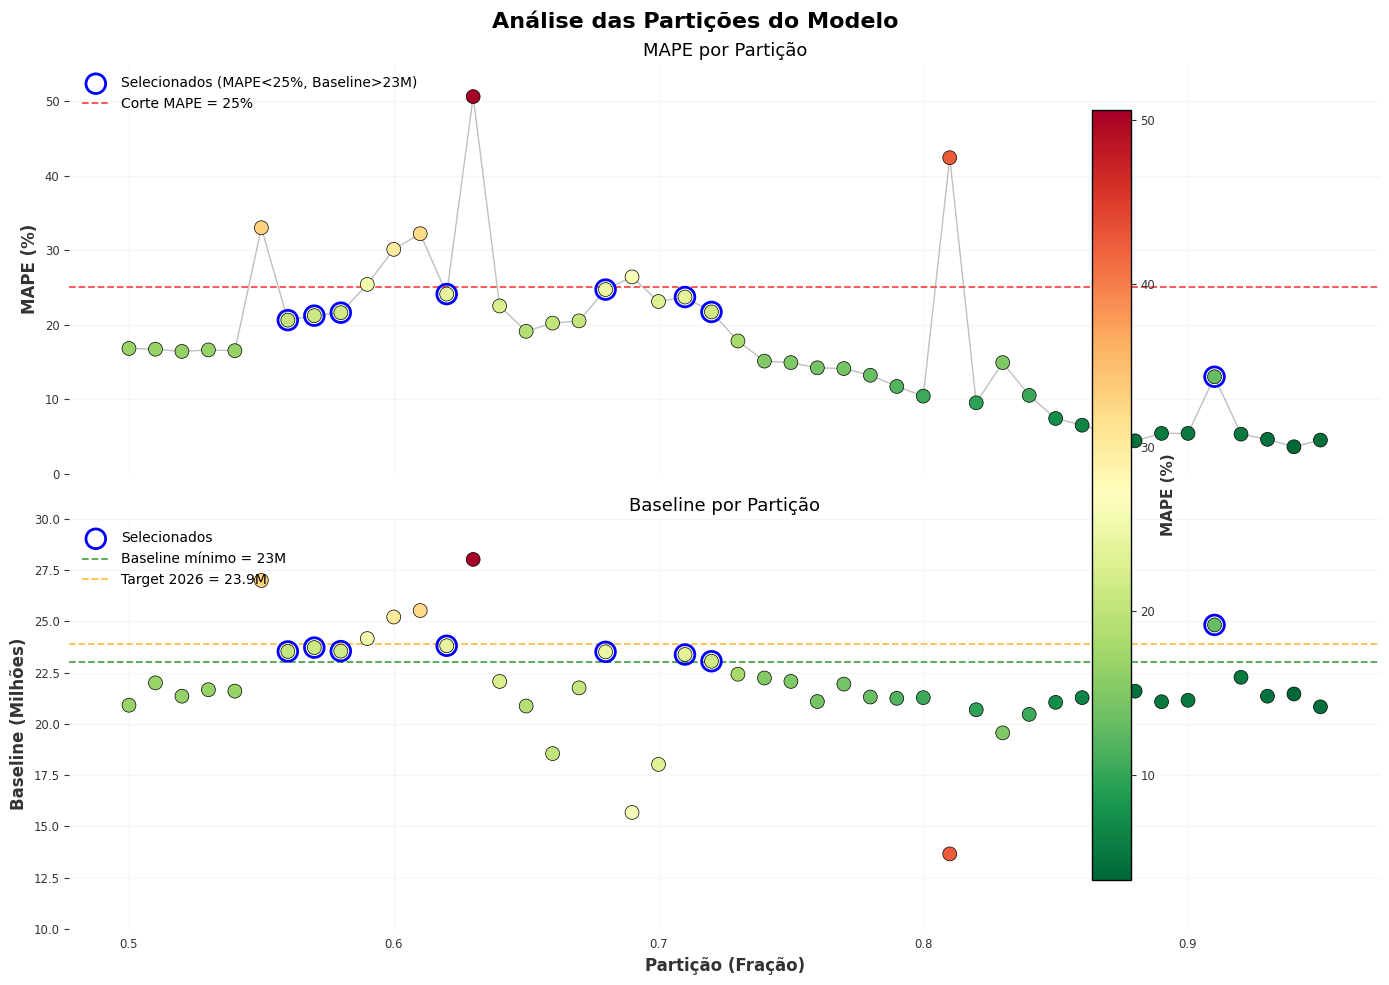

=== MODELOS SELECIONADOS PARA O ENSEMBLE ===
Critério: MAPE < 25% E Baseline > 23,000,000

Partição   MAPE (%)   Baseline        Peso Relativo  
-------------------------------------------------------
0.56      20.6%      23,533,391     0.123
0.57      21.2%      23,721,485     0.121
0.58      21.6%      23,549,206     0.118
0.62      24.1%      23,810,968     0.107
0.68      24.7%      23,513,932     0.103
0.71      23.7%      23,383,210     0.107
0.72      21.7%      23,055,306     0.115
0.91      13.0%      24,827,699     0.206

Total de modelos selecionados: 8
MAPE médio: 21.3%
Baseline médio: 23,674,400


In [94]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Dados das partições
dados = [
    (0.50, 16.8, 20908202), (0.51, 16.7, 21999275), (0.52, 16.4, 21350110),
    (0.53, 16.6, 21664045), (0.54, 16.5, 21597742), (0.55, 33.0, 26996990),
    (0.56, 20.6, 23533391), (0.57, 21.2, 23721485), (0.58, 21.6, 23549206),
    (0.59, 25.4, 24160772), (0.60, 30.1, 25214576), (0.61, 32.2, 25528448),
    (0.62, 24.1, 23810968), (0.63, 50.6, 28026577), (0.64, 22.5, 22070024),
    (0.65, 19.1, 20869471), (0.66, 20.2, 18547146), (0.67, 20.5, 21755466),
    (0.68, 24.7, 23513932), (0.69, 26.4, 15676266), (0.70, 23.1, 18020916),
    (0.71, 23.7, 23383210), (0.72, 21.7, 23055306), (0.73, 17.8, 22422686),
    (0.74, 15.1, 22237203), (0.75, 14.9, 22070902), (0.76, 14.2, 21087987),
    (0.77, 14.1, 21939175), (0.78, 13.2, 21309462), (0.79, 11.7, 21245823),
    (0.80, 10.4, 21278620), (0.81, 42.4, 13651389), (0.82, 9.5, 20686928),
    (0.83, 14.9, 19557787), (0.84, 10.5, 20462354), (0.85, 7.4, 21048665),
    (0.86, 6.5, 21278449), (0.87, 5.4, 21492368), (0.88, 4.4, 21593916),
    (0.89, 5.4, 21077261), (0.90, 5.4, 21149460), (0.91, 13.0, 24827699),
    (0.92, 5.3, 22272412), (0.93, 4.6, 21349496), (0.94, 3.6, 21457631),
    (0.95, 4.5, 20829093)
]

# Converter para DataFrame
df = pd.DataFrame(dados, columns=['Particao', 'MAPE', 'Baseline'])

# Criar figura com dois subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
fig.suptitle('Análise das Partições do Modelo', fontsize=16, fontweight='bold')

# Cores baseadas no MAPE
cores = plt.cm.RdYlGn_r(df['MAPE'] / 60)  # Normalizar MAPE para cores

# Plot 1: MAPE vs Partição
scatter1 = ax1.scatter(df['Particao'], df['MAPE'], c=df['MAPE'], 
                       cmap='RdYlGn_r', s=100, edgecolors='black', linewidth=0.5, zorder=5)
ax1.plot(df['Particao'], df['MAPE'], color='gray', alpha=0.5, linewidth=1, zorder=3)

# Destacar os melhores modelos (MAPE < 25 e Baseline > 23M)
melhores = (df['MAPE'] < 25) & (df['Baseline'] > 23000000)
ax1.scatter(df.loc[melhores, 'Particao'], df.loc[melhores, 'MAPE'], 
            facecolors='none', edgecolors='blue', s=200, linewidth=2, 
            label='Selecionados (MAPE<25%, Baseline>23M)', zorder=4)

# Adicionar linha de corte MAPE = 25%
ax1.axhline(y=25, color='red', linestyle='--', alpha=0.7, label='Corte MAPE = 25%')

ax1.set_ylabel('MAPE (%)', fontsize=12)
ax1.set_ylim(0, 55)
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper left', fontsize=10)
ax1.set_title('MAPE por Partição', fontsize=13)

# Adicionar anotações para os melhores
for idx, row in df[melhores].iterrows():
    if row['MAPE'] < 10:  # Só os melhores
        ax1.annotate(f"{row['MAPE']:.1f}%", 
                    xy=(row['Particao'], row['MAPE']),
                    xytext=(5, 5), textcoords='offset points',
                    fontsize=8, alpha=0.8)

# Plot 2: Baseline vs Partição
scatter2 = ax2.scatter(df['Particao'], df['Baseline']/1e6, c=df['MAPE'], 
                       cmap='RdYlGn_r', s=100, edgecolors='black', linewidth=0.5, zorder=5)

# Destacar selecionados
ax2.scatter(df.loc[melhores, 'Particao'], df.loc[melhores, 'Baseline']/1e6, 
            facecolors='none', edgecolors='blue', s=200, linewidth=2, 
            label='Selecionados', zorder=4)

# Linhas de referência
ax2.axhline(y=23, color='green', linestyle='--', alpha=0.7, label='Baseline mínimo = 23M')
ax2.axhline(y=23.9, color='orange', linestyle='--', alpha=0.7, label='Target 2026 = 23.9M')

ax2.set_xlabel('Partição (Fração)', fontsize=12)
ax2.set_ylabel('Baseline (Milhões)', fontsize=12)
ax2.set_ylim(10, 30)
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper left', fontsize=10)
ax2.set_title('Baseline por Partição', fontsize=13)

# Colorbar
cbar = plt.colorbar(scatter2, ax=[ax1, ax2], label='MAPE (%)', pad=0.01)
cbar.set_label('MAPE (%)', fontsize=11)

plt.tight_layout()
plt.show()

# Estatísticas dos modelos selecionados
print("=== MODELOS SELECIONADOS PARA O ENSEMBLE ===")
print(f"Critério: MAPE < 25% E Baseline > 23,000,000\n")
print(f"{'Partição':<10} {'MAPE (%)':<10} {'Baseline':<15} {'Peso Relativo':<15}")
print("-" * 55)

selecionados = df[melhores].copy()
if len(selecionados) > 0:
    # Calcular pesos baseados na fórmula do código original
    selecionados['peso_bruto'] = selecionados['Baseline'] / selecionados['MAPE']
    soma_pesos = selecionados['peso_bruto'].sum()
    selecionados['peso_normalizado'] = selecionados['peso_bruto'] / soma_pesos
    
    for _, row in selecionados.iterrows():
        print(f"{row['Particao']:.2f}      {row['MAPE']:.1f}%      {row['Baseline']:,.0f}     {row['peso_normalizado']:.3f}")
    
    print(f"\nTotal de modelos selecionados: {len(selecionados)}")
    print(f"MAPE médio: {selecionados['MAPE'].mean():.1f}%")
    print(f"Baseline médio: {selecionados['Baseline'].mean():,.0f}")

✔ Varredura anterior na memória reutilizada.

ENSEMBLE CORRIGIDO
Particoes: [0.56, 0.57, 0.91]
MAPE Ensemble (Val): 32.4%
Baseline 2026: 24,175,101 M3
Fator Choque: 0.982



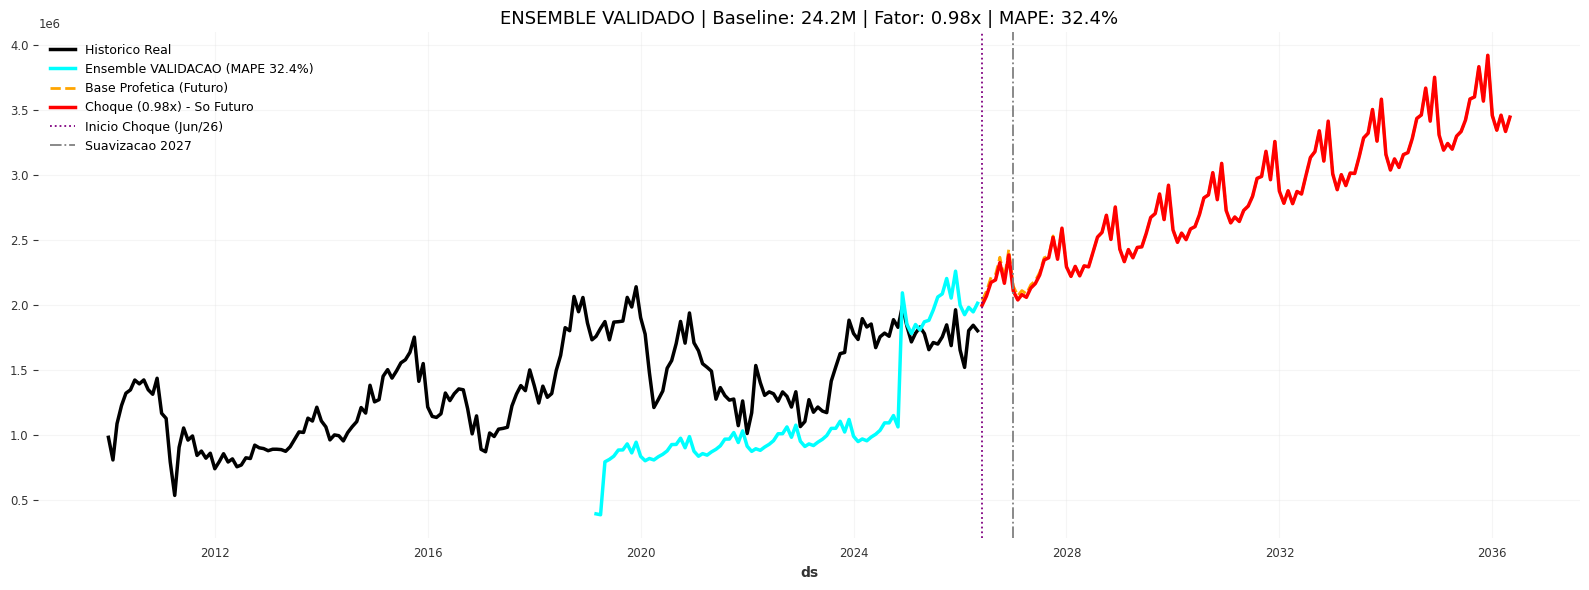

In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import logging
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('optuna').setLevel(logging.ERROR)
%matplotlib inline

from darts import TimeSeries
from darts.models import Prophet
from darts.metrics import mape
import optuna

# 0. CARREGAMENTO SEGURO (df_real)
if 'df_real' in globals():
    df = globals()['df_real'].copy()
else:
    df = None
    for nome in ['df_original', 'df', 'base', 'data']:
        if nome in globals() and isinstance(globals()[nome], pd.DataFrame):
            df = globals()[nome].copy()
            break

date_col, val_col = None, None
for c in df.columns:
    if 'date' in c.lower() or 'mes' in c.lower() or 'data' in c.lower():
        try: pd.to_datetime(df[c].dropna().iloc[0]); date_col = c
        except: pass
if date_col is None: date_col = df.columns[0]
for c in df.columns:
    if c != date_col and pd.api.types.is_numeric_dtype(df[c]):
        val_col = c; break

df = df.rename(columns={date_col: 'ds', val_col: 'y'})
df['ds'] = pd.to_datetime(df['ds'])
df = df.sort_values('ds').set_index('ds') 
series = TimeSeries.from_series(df['y'])

TARGET_2026 = 23_900_000
mask_real = (series.time_index >= pd.Timestamp('2026-01-01')) & (series.time_index <= pd.Timestamp('2026-05-01'))
soma_real = series.values()[mask_real].sum()

# 1. VARREDURA (PULA SE JA EXISTIR NA MEMORIA)
if 'results' not in globals() or not isinstance(globals().get('results'), list):
    results = []
    for frac in np.arange(0.50, 0.96, 0.01):
        train, val = series.split_after(frac)
        def objective(trial):
            mode = trial.suggest_categorical('mode', ['additive', 'multiplicative'])
            cp = trial.suggest_float('cp', 0.01, 50.0, log=True)
            sp = trial.suggest_float('sp', 0.01, 20.0, log=True)
            m = Prophet(seasonality_mode=mode, changepoint_prior_scale=cp, seasonality_prior_scale=sp, yearly_seasonality=True)
            m.fit(train)
            return mape(val, m.predict(n=len(val)))
        study = optuna.create_study(direction='minimize')
        study.optimize(objective, n_trials=10, show_progress_bar=False, catch=(Exception,))
        kw = {'seasonality_mode': study.best_params['mode'], 'changepoint_prior_scale': study.best_params['cp'], 'seasonality_prior_scale': study.best_params['sp'], 'yearly_seasonality': True}
        model = Prophet(**kw); model.fit(train)
        fc = model.predict(n=len(val) + 120)
        mape_val = mape(val, fc[:len(val)])
        df_fc = pd.DataFrame({'y': fc.values().flatten()}, index=fc.time_index)
        fut_idx = fc.time_index[len(val):]
        mask_base = (fut_idx >= pd.Timestamp('2026-06-01')) & (fut_idx <= fut_idx[-1]) # safe
        mask_base = (fut_idx >= pd.Timestamp('2026-06-01')) & (fut_idx <= pd.Timestamp('2026-12-01'))
        baseline = soma_real + fc.values().flatten()[len(val):][mask_base].sum()
        results.append({'frac': frac, 'mape_val': mape_val, 'baseline': baseline, 'df_fc': df_fc})
    print("Varredura concluída.")
else:
    results = globals()['results']
    print("✔ Varredura anterior na memória reutilizada.")

# 2. SELEÇÃO E PESO
valid = [r for r in results if (r['mape_val'] < 21.5) and (r['baseline'] > 23_000_000)]
if not valid: 
    valid = sorted(results, key=lambda x: x['baseline'], reverse=True)[:5]

weights = np.array([s['baseline'] / (s['mape_val'] + 1e-9) for s in valid])
weights = weights / weights.sum()

# 3. ENSEMBLE ALINHADO POR TEMPO
all_idx = pd.concat([s['df_fc'].index.to_series() for s in valid]).drop_duplicates().sort_values()
ens_series = pd.Series(0.0, index=all_idx)
for i, s in enumerate(valid):
    ens_series = ens_series.add(s['df_fc']['y'] * weights[i], fill_value=0)
ensemble_ts = TimeSeries.from_times_and_values(ens_series.index, ens_series.values)

# 4. FATIAMENTO (TUPLA CORRIGIDA)
ens_val_ts, ens_fut_ts = ensemble_ts.split_before(pd.Timestamp('2026-06-01'))

# MAPE USA slice_intersect (ELIMINA ERRO DE TIPO)
real_val_ts = series.slice_intersect(ens_val_ts)
mape_ens = mape(real_val_ts, ens_val_ts)

# 5. ALVO
mask_fut = (ens_fut_ts.time_index >= pd.Timestamp('2026-06-01')) & (ens_fut_ts.time_index <= pd.Timestamp('2026-12-01'))
soma_base = ens_fut_ts.values()[mask_fut].sum()
total_baseline = soma_real + soma_base
fator = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0

parts_str = ", ".join(f"{s['frac']:.2f}" for s in valid)
print(f"\nENSEMBLE CORRIGIDO")
print(f"Particoes: [{parts_str}]")
print(f"MAPE Ensemble (Val): {mape_ens:.1f}%")
print(f"Baseline 2026: {total_baseline:,.0f} M3")
print(f"Fator Choque: {fator:.3f}\n")

# 6. CHOQUE SÓ NO FUTURO
fatores = []
for t in ens_fut_ts.time_index:
    if pd.Timestamp('2026-06-01') <= t <= pd.Timestamp('2026-12-01'):
        fatores.append(fator)
    elif t.year == 2027:
        decay = max(0, 1 - ((t.month - 1)/12))
        fatores.append(1.0 + (fator - 1.0)*decay)
    else:
        fatores.append(1.0)
forecast_final = ens_fut_ts * TimeSeries.from_times_and_values(ens_fut_ts.time_index, np.array(fatores))

# 7. PLOT
fig, ax = plt.subplots(figsize=(16, 6))
series.plot(ax=ax, label='Historico Real', color='black', linewidth=2.5)
ens_val_ts.plot(ax=ax, label=f'Ensemble VALIDACAO (MAPE {mape_ens:.1f}%)', color='cyan', linewidth=2.5)
ens_fut_ts.plot(ax=ax, label='Base Profetica (Futuro)', color='orange', linestyle='--', linewidth=2)
forecast_final.plot(ax=ax, label=f'Choque ({fator:.2f}x) - So Futuro', color='red', linewidth=2.5)

ax.axvline(x=pd.Timestamp('2026-06-01'), color='purple', linestyle=':', label='Inicio Choque (Jun/26)')
ax.axvline(x=pd.Timestamp('2027-01-01'), color='gray', linestyle='-.', label='Suavizacao 2027')
title_str = f'ENSEMBLE VALIDADO | Baseline: {total_baseline/1e6:.1f}M | Fator: {fator:.2f}x | MAPE: {mape_ens:.1f}%'
ax.set_title(title_str, fontsize=13)
ax.legend(fontsize=9, loc='upper left'); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### MAPE 13.0% | partição 0.91

Ref Val MAPE: 13.0% | Ensemble Baseline: 23,781,269 | Fator: 1.008


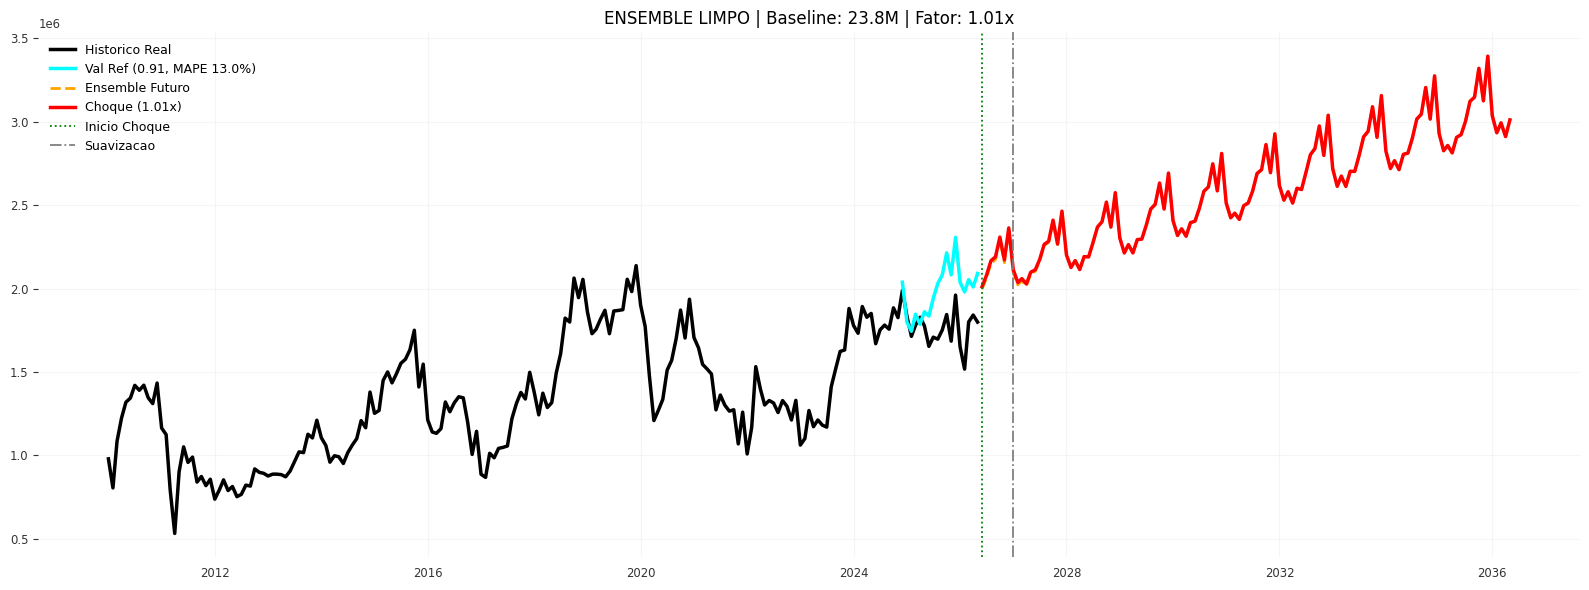

In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TARGET_2026 = 23_900_000
s_real = pd.Series(series.values().flatten(), index=series.time_index)
mask_real = (s_real.index >= pd.Timestamp('2026-01-01')) & (s_real.index <= pd.Timestamp('2026-05-01'))
soma_real = s_real[mask_real].sum()

# 1. Filtra os 8 bons
valid = [r for r in results if (r['mape_val'] < 25.0) and (r['baseline'] > 23_000_000)]
weights = np.array([s['baseline'] / (s['mape_val'] + 1e-9) for s in valid])
weights = weights / weights.sum()

# 2. ENSEMBLE SÓ DO FUTURO (Evita erro do zero no passado)
fut_idx = pd.date_range('2026-06-01', periods=120, freq='MS')
ens_fut = pd.Series(0.0, index=fut_idx)
for i, s in enumerate(valid):
    fut_part = s['df_fc'].loc['2026-06-01':]  # Só previsão futura de cada modelo
    ens_fut = ens_fut.add(fut_part['y'].reindex(fut_idx) * weights[i], fill_value=0)

soma_base = ens_fut[:7].sum()  # Jun-Dez/26
fator = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0

# 3. REFERÊNCIA DE VALIDAÇÃO (O melhor modelo individual)
ref = min(valid, key=lambda x: x['mape_val'])
ref_val = ref['df_fc'].loc[:'2026-05-31']
mape_ref = np.mean(np.abs((s_real.reindex(ref_val.index) - ref_val['y']) / s_real.reindex(ref_val.index))) * 100

# 4. Choque suavizado
choque = ens_fut.copy()
for t in choque.index:
    if pd.Timestamp('2026-06-01') <= t <= pd.Timestamp('2026-12-01'): choque[t] *= fator
    elif t.year == 2027: choque[t] *= 1.0 + (fator - 1.0)*max(0, 1-((t.month-1)/12))

print(f"Ref Val MAPE: {mape_ref:.1f}% | Ensemble Baseline: {soma_real+soma_base:,.0f} | Fator: {fator:.3f}")

# 5. Plot
fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(s_real.index, s_real.values, color='black', lw=2.5, label='Historico Real')
ax.plot(ref_val.index, ref_val['y'], color='cyan', lw=2.5, label=f'Val Ref ({ref["frac"]:.2f}, MAPE {mape_ref:.1f}%)')
ax.plot(ens_fut.index, ens_fut.values, color='orange', lw=2, ls='--', label='Ensemble Futuro')
ax.plot(choque.index, choque.values, color='red', lw=2.5, label=f'Choque ({fator:.2f}x)')
ax.axvline(pd.Timestamp('2026-06-01'), color='green', ls=':', label='Inicio Choque')
ax.axvline(pd.Timestamp('2027-01-01'), color='gray', ls='-.', label='Suavizacao')
ax.set_title(f'ENSEMBLE LIMPO | Baseline: {(soma_real+soma_base)/1e6:.1f}M | Fator: {fator:.2f}x')
ax.legend(fontsize=9); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

Ref Val MAPE: 13.0% | Ensemble Baseline: 23,781,269 | Fator: 1.008


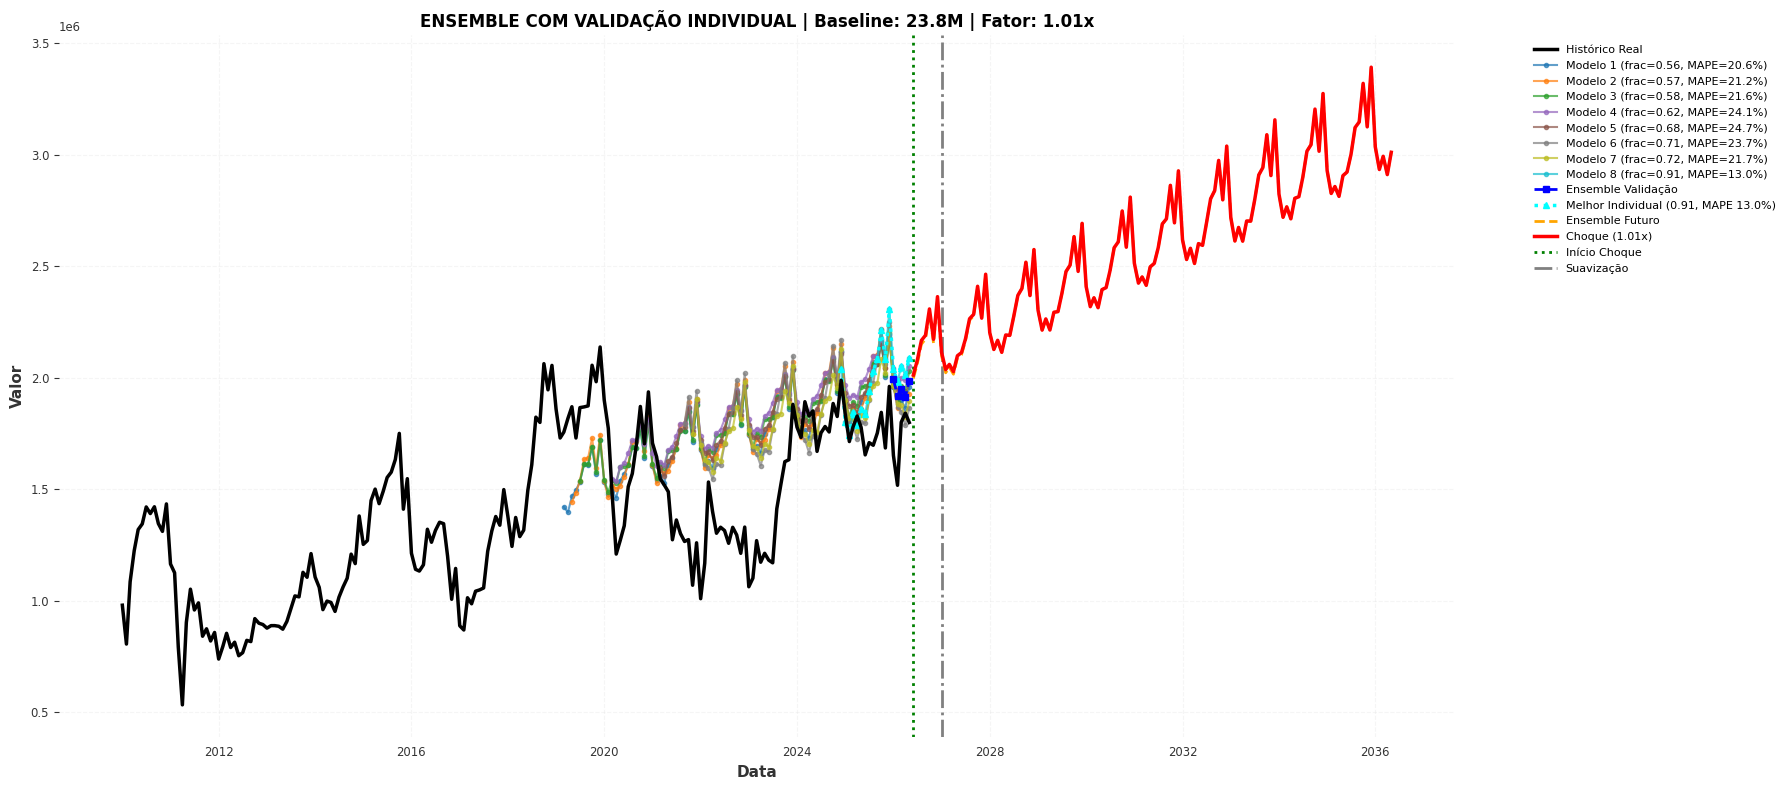


Modelos selecionados para o ensemble:
Modelo 1: frac=0.560, MAPE=20.56%, Peso=0.124
Modelo 2: frac=0.570, MAPE=21.20%, Peso=0.121
Modelo 3: frac=0.580, MAPE=21.64%, Peso=0.118
Modelo 4: frac=0.620, MAPE=24.12%, Peso=0.107
Modelo 5: frac=0.680, MAPE=24.67%, Peso=0.103
Modelo 6: frac=0.710, MAPE=23.70%, Peso=0.107
Modelo 7: frac=0.720, MAPE=21.73%, Peso=0.115
Modelo 8: frac=0.910, MAPE=13.05%, Peso=0.206


In [104]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TARGET_2026 = 23_900_000
s_real = pd.Series(series.values().flatten(), index=series.time_index)
mask_real = (s_real.index >= pd.Timestamp('2026-01-01')) & (s_real.index <= pd.Timestamp('2026-05-01'))
soma_real = s_real[mask_real].sum()

# 1. Filtra os 8 bons
valid = [r for r in results if (r['mape_val'] < 25.0) and (r['baseline'] > 23_000_000)]
weights = np.array([s['baseline'] / (s['mape_val'] + 1e-9) for s in valid])
weights = weights / weights.sum()

# 2. ENSEMBLE SÓ DO FUTURO (Evita erro do zero no passado)
fut_idx = pd.date_range('2026-06-01', periods=120, freq='MS')
ens_fut = pd.Series(0.0, index=fut_idx)
for i, s in enumerate(valid):
    fut_part = s['df_fc'].loc['2026-06-01':]  # Só previsão futura de cada modelo
    ens_fut = ens_fut.add(fut_part['y'].reindex(fut_idx) * weights[i], fill_value=0)

soma_base = ens_fut[:7].sum()  # Jun-Dez/26
fator = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0

# 3. REFERÊNCIA DE VALIDAÇÃO (O melhor modelo individual)
ref = min(valid, key=lambda x: x['mape_val'])
ref_val = ref['df_fc'].loc[:'2026-05-31']
mape_ref = np.mean(np.abs((s_real.reindex(ref_val.index) - ref_val['y']) / s_real.reindex(ref_val.index))) * 100

# 4. Choque suavizado
choque = ens_fut.copy()
for t in choque.index:
    if pd.Timestamp('2026-06-01') <= t <= pd.Timestamp('2026-12-01'): choque[t] *= fator
    elif t.year == 2027: choque[t] *= 1.0 + (fator - 1.0)*max(0, 1-((t.month-1)/12))

print(f"Ref Val MAPE: {mape_ref:.1f}% | Ensemble Baseline: {soma_real+soma_base:,.0f} | Fator: {fator:.3f}")

# 5. Plot
fig, ax = plt.subplots(figsize=(18, 8))

# Dados reais
ax.plot(s_real.index, s_real.values, color='black', lw=2.5, label='Histórico Real', zorder=10)

# Validação de cada modelo individual
colors = plt.cm.tab10(np.linspace(0, 1, len(valid)))
for i, model in enumerate(valid):
    val_data = model['df_fc'].loc[:'2026-05-31']
    ax.plot(val_data.index, val_data['y'], 
            color=colors[i], lw=1.5, alpha=0.7, 
            linestyle='-', marker='o', markersize=3,
            label=f'Modelo {i+1} (frac={model["frac"]:.2f}, MAPE={model["mape_val"]:.1f}%)', 
            zorder=5)

# Ensemble de validação
ensemble_val = pd.Series(0.0, index=pd.date_range('2026-01-01', '2026-05-31', freq='MS'))
for i, model in enumerate(valid):
    val_part = model['df_fc'].loc[:'2026-05-31']
    ensemble_val = ensemble_val.add(val_part['y'].reindex(ensemble_val.index) * weights[i], fill_value=0)

ax.plot(ensemble_val.index, ensemble_val.values, 
        color='blue', lw=2, linestyle='--', marker='s', markersize=5,
        label='Ensemble Validação', zorder=8)

# Modelo de referência (melhor individual)
ax.plot(ref_val.index, ref_val['y'], 
        color='cyan', lw=2.5, linestyle=':', marker='^', markersize=5,
        label=f'Melhor Individual ({ref["frac"]:.2f}, MAPE {mape_ref:.1f}%)', 
        zorder=7)

# Previsões futuras
ax.plot(ens_fut.index, ens_fut.values, color='orange', lw=2, ls='--', 
        label='Ensemble Futuro', zorder=6)
ax.plot(choque.index, choque.values, color='red', lw=2.5, 
        label=f'Choque ({fator:.2f}x)', zorder=6)

# Linhas de referência
ax.axvline(pd.Timestamp('2026-06-01'), color='green', ls=':', lw=2, label='Início Choque')
ax.axvline(pd.Timestamp('2027-01-01'), color='gray', ls='-.', lw=2, label='Suavização')

ax.set_title(f'ENSEMBLE COM VALIDAÇÃO INDIVIDUAL | Baseline: {(soma_real+soma_base)/1e6:.1f}M | Fator: {fator:.2f}x', 
             fontsize=12, fontweight='bold')
ax.set_xlabel('Data', fontsize=11)
ax.set_ylabel('Valor', fontsize=11)
ax.legend(fontsize=8, bbox_to_anchor=(1.05, 1), loc='upper left', ncol=1)
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

# Print dos modelos selecionados
print("\nModelos selecionados para o ensemble:")
for i, model in enumerate(valid):
    print(f"Modelo {i+1}: frac={model['frac']:.3f}, MAPE={model['mape_val']:.2f}%, Peso={weights[i]:.3f}")

Ref Val MAPE: 13.0% | Ensemble Baseline: 23,781,269 | Fator: 1.008

Plotando 1 modelos específicos: [0.56]


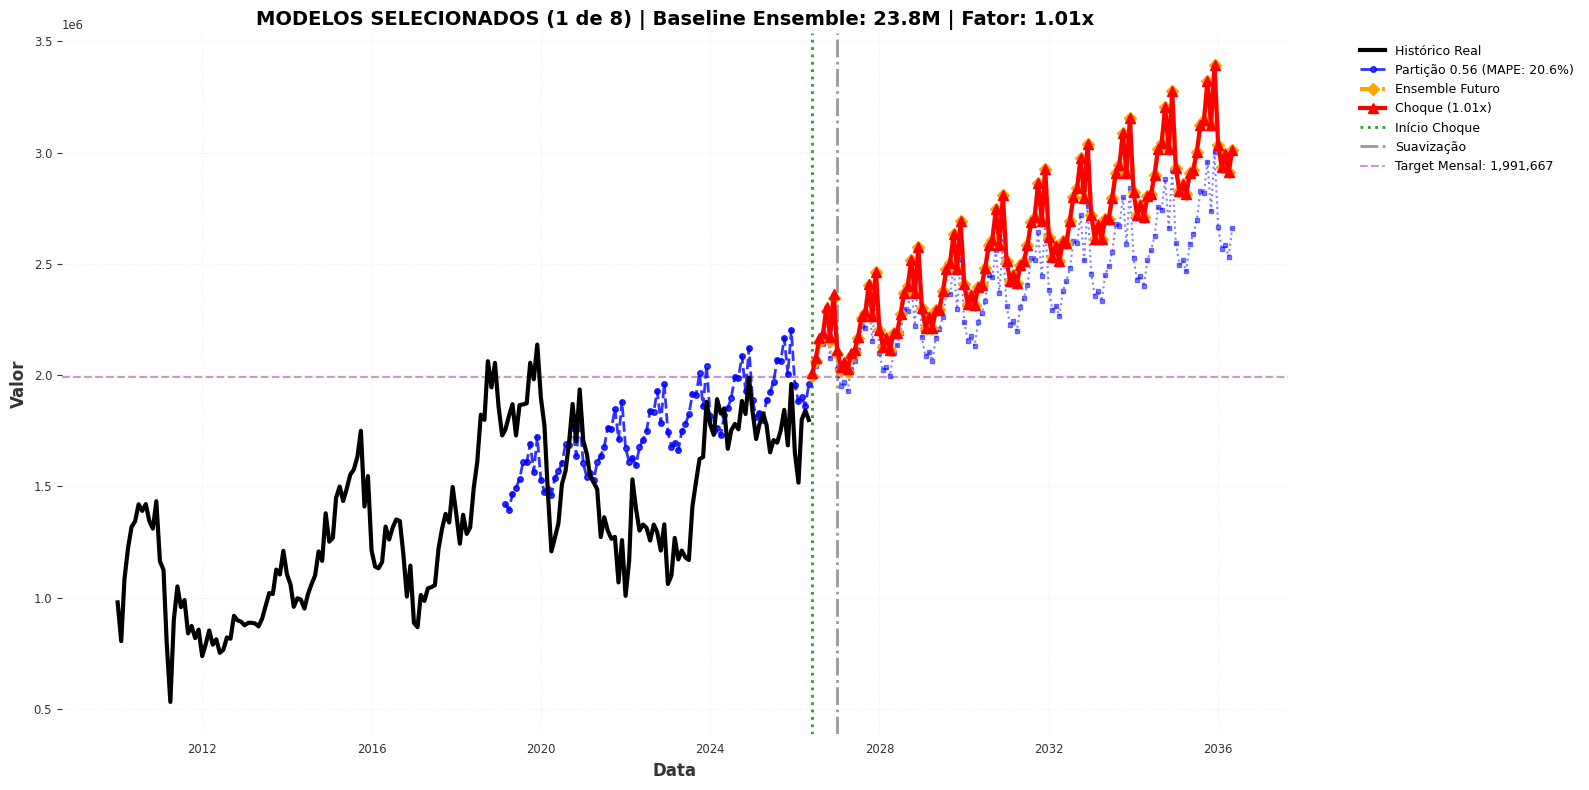


MODELOS PLOTADOS:
Partição: 0.56 | MAPE: 20.6% | Baseline: 23,533,391


In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TARGET_2026 = 23_900_000
s_real = pd.Series(series.values().flatten(), index=series.time_index)
mask_real = (s_real.index >= pd.Timestamp('2026-01-01')) & (s_real.index <= pd.Timestamp('2026-05-01'))
soma_real = s_real[mask_real].sum()

# 1. Filtra os 8 bons
valid = [r for r in results if (r['mape_val'] < 25.0) and (r['baseline'] > 23_000_000)]
weights = np.array([s['baseline'] / (s['mape_val'] + 1e-9) for s in valid])
weights = weights / weights.sum()

# 2. ENSEMBLE SÓ DO FUTURO
fut_idx = pd.date_range('2026-06-01', periods=120, freq='MS')
ens_fut = pd.Series(0.0, index=fut_idx)
for i, s in enumerate(valid):
    fut_part = s['df_fc'].loc['2026-06-01':]
    ens_fut = ens_fut.add(fut_part['y'].reindex(fut_idx) * weights[i], fill_value=0)

soma_base = ens_fut[:7].sum()
fator = (TARGET_2026 - soma_real) / soma_base if soma_base > 0 else 1.0

# 3. REFERÊNCIA DE VALIDAÇÃO
ref = min(valid, key=lambda x: x['mape_val'])
ref_val = ref['df_fc'].loc[:'2026-05-31']
mape_ref = np.mean(np.abs((s_real.reindex(ref_val.index) - ref_val['y']) / s_real.reindex(ref_val.index))) * 100

# 4. Choque suavizado
choque = ens_fut.copy()
for t in choque.index:
    if pd.Timestamp('2026-06-01') <= t <= pd.Timestamp('2026-12-01'): choque[t] *= fator
    elif t.year == 2027: choque[t] *= 1.0 + (fator - 1.0)*max(0, 1-((t.month-1)/12))

print(f"Ref Val MAPE: {mape_ref:.1f}% | Ensemble Baseline: {soma_real+soma_base:,.0f} | Fator: {fator:.3f}")

# ============ ESCOLHA QUAIS MODELOS QUER PLOTAR ============
# Escolha as frações específicas que deseja visualizar
fracoes_para_plotar = [0.91,0.56]  # MUDE AQUI

# Filtrar apenas os modelos escolhidos
modelos_escolhidos = [r for r in valid if r['frac'] in fracoes_para_plotar]

print(f"\nPlotando {len(modelos_escolhidos)} modelos específicos: {[m['frac'] for m in modelos_escolhidos]}")

# 5. Plot
fig, ax = plt.subplots(figsize=(16, 8))

# Histórico Real
ax.plot(s_real.index, s_real.values, color='black', lw=3, 
        label='Histórico Real', zorder=10)

# Cores para os modelos escolhidos
colors = ['blue', 'green', 'purple', 'brown', 'pink', 'cyan', 'magenta', 'olive']

# Plotar apenas os modelos escolhidos
for i, modelo in enumerate(modelos_escolhidos):
    color = colors[i % len(colors)]
    
    # Validação do modelo
    val_part = modelo['df_fc'].loc[:'2026-05-31']
    ax.plot(val_part.index, val_part['y'], 
            color=color, lw=2, alpha=0.8, 
            linestyle='--', marker='o', markersize=4,
            label=f'Partição {modelo["frac"]:.2f} (MAPE: {modelo["mape_val"]:.1f}%)',
            zorder=5)
    
    # Futuro do modelo
    fut_part = modelo['df_fc'].loc['2026-06-01':]
    ax.plot(fut_part.index, fut_part['y'], 
            color=color, lw=1.5, alpha=0.5, 
            linestyle=':', marker='s', markersize=3,
            zorder=4)

# Ensemble Futuro
ax.plot(ens_fut.index, ens_fut.values, color='orange', lw=3, ls='--', 
        marker='D', markersize=6, label='Ensemble Futuro', zorder=7)

# Choque
ax.plot(choque.index, choque.values, color='red', lw=3, 
        marker='^', markersize=7, label=f'Choque ({fator:.2f}x)', zorder=8)

# Linhas de referência
ax.axvline(pd.Timestamp('2026-06-01'), color='green', ls=':', lw=2, 
           label='Início Choque', alpha=0.8)
ax.axvline(pd.Timestamp('2027-01-01'), color='gray', ls='-.', lw=2, 
           label='Suavização', alpha=0.8)

# Target mensal
ax.axhline(y=TARGET_2026/12, color='purple', ls='--', lw=1.5, 
           alpha=0.4, label=f'Target Mensal: {TARGET_2026/12:,.0f}')

# Configurações
ax.set_title(f'MODELOS SELECIONADOS ({len(modelos_escolhidos)} de {len(valid)}) | Baseline Ensemble: {(soma_real+soma_base)/1e6:.1f}M | Fator: {fator:.2f}x', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Data', fontsize=12)
ax.set_ylabel('Valor', fontsize=12)
ax.legend(fontsize=9, bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

# Print dos modelos plotados
print("\n" + "="*60)
print("MODELOS PLOTADOS:")
print("="*60)
for modelo in modelos_escolhidos:
    print(f"Partição: {modelo['frac']:.2f} | MAPE: {modelo['mape_val']:.1f}% | Baseline: {modelo['baseline']:,.0f}")
print("="*60)